# Figures of the manuscript

*Escaping Aharonov–Bohm caging* — arXiv:2511.20255

This notebook only **plots**: it reads the data in `Data/` (produced by the notebooks in `Notebooks/Results for manuscript/`)
and saves every figure to `Figures/Figures for paper/`, using the file names of the LaTeX source.

| Figure | File(s) | Data notebook |
|---|---|---|
| 1 b), d) | `bulk_bands.pdf`, `open_vs_closed.pdf` | `Fig01_static_band_structure` |
| 2 | `quasienergies.pdf` | `Fig02_quasienergy_spectrum` |
| 3 | schematic, not reproduced | — |
| 4 a)–c) | `dynamics_starting_csite.pdf` | `Fig04_dynamics_from_C_site` |
| 5 | `edgestates_driven.pdf` | `Fig05_driven_edge_states` |
| 6 | `short_dynamics.pdf` | `Fig06_short_chain_dynamics` |
| 7 | `entanglements.pdf` | `Fig07_entanglement_dynamics` |
| A1 | `edge_states_static.pdf` | `FigA01_static_edge_states` |
| A2 | `zak_phase.pdf` | `FigA02_A08_zak_phase` |
| A3 | `convergence_A.pdf`, `convergence_Gamma.pdf` | `FigA03_convergence_of_Gamma` |
| A4 | `dynamics_starting_ulattice.pdf` | `FigA04_dynamics_from_U_site` |
| A5 | `dynamics_csite_vs_w.pdf` | `FigA05_dynamics_vs_frequency` |
| A6 | `hopping_ren.pdf` | `FigA06_hopping_renormalization` |
| A7 | `diamond_compared_to_ssh.pdf` | `FigA07_diamond_vs_SSH` |
| A8 | `zak_phase_effective.pdf` | `FigA02_A08_zak_phase` |
| A9 | `fouriertransform_colormap.pdf` | `FigA09_fourier_transform_entanglement` |
| A10 | `colormap_AV.pdf` | `FigA10_max_entanglement_vs_A_and_V` |
| A11 | `two_particle_spectrum_vs_V.pdf` | `FigA11_two_particle_spectrum_vs_V` |

The schematics (Fig. 1 a, c; Fig. 3; Fig. 4 d) were composed separately (see `Figures/Schematics/`). The insets of Fig. 2 are not included.

In [1]:
import os
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parents[1]                 # .../paper_reproduction
DATA = ROOT / 'Data'
FIGURES = ROOT / 'Figures' / 'Figures for paper'
FIGURES.mkdir(parents=True, exist_ok=True)

from data_io import load_data

# The style uses LaTeX for all text; on macOS the TeX binaries are not always in the PATH of the Jupyter kernel
if Path('/Library/TeX/texbin').exists() and '/Library/TeX/texbin' not in os.environ['PATH']:
    os.environ['PATH'] += os.pathsep + '/Library/TeX/texbin'
plt.style.use(ROOT / 'Source' / 'paper_style.mplstyle')

In [3]:
# Dominant oscillation frequencies of S^(A)(mT): peaks of its Fourier transform (Fig. A9)
OMEGA_FT_V0 = 0.125          # V = 0
OMEGA_FT_V02_FAST = 0.227    # V = 0.2
OMEGA_FT_V02_SLOW = 0.0345   # V = 0.2
# Stroboscopic time (V = 0.2) at which p_{1,1} = 1 and S^(A) = E_P(1,1) != 0
M_SPECIAL = 106

## Fig. 1 Static diamond chain


Fig01_bulk_bands.npz
    parameters: {'J': 1.0}
    kvals: shape (601,)
    phivals: shape (3,)
    bands: shape (3, 3, 601)


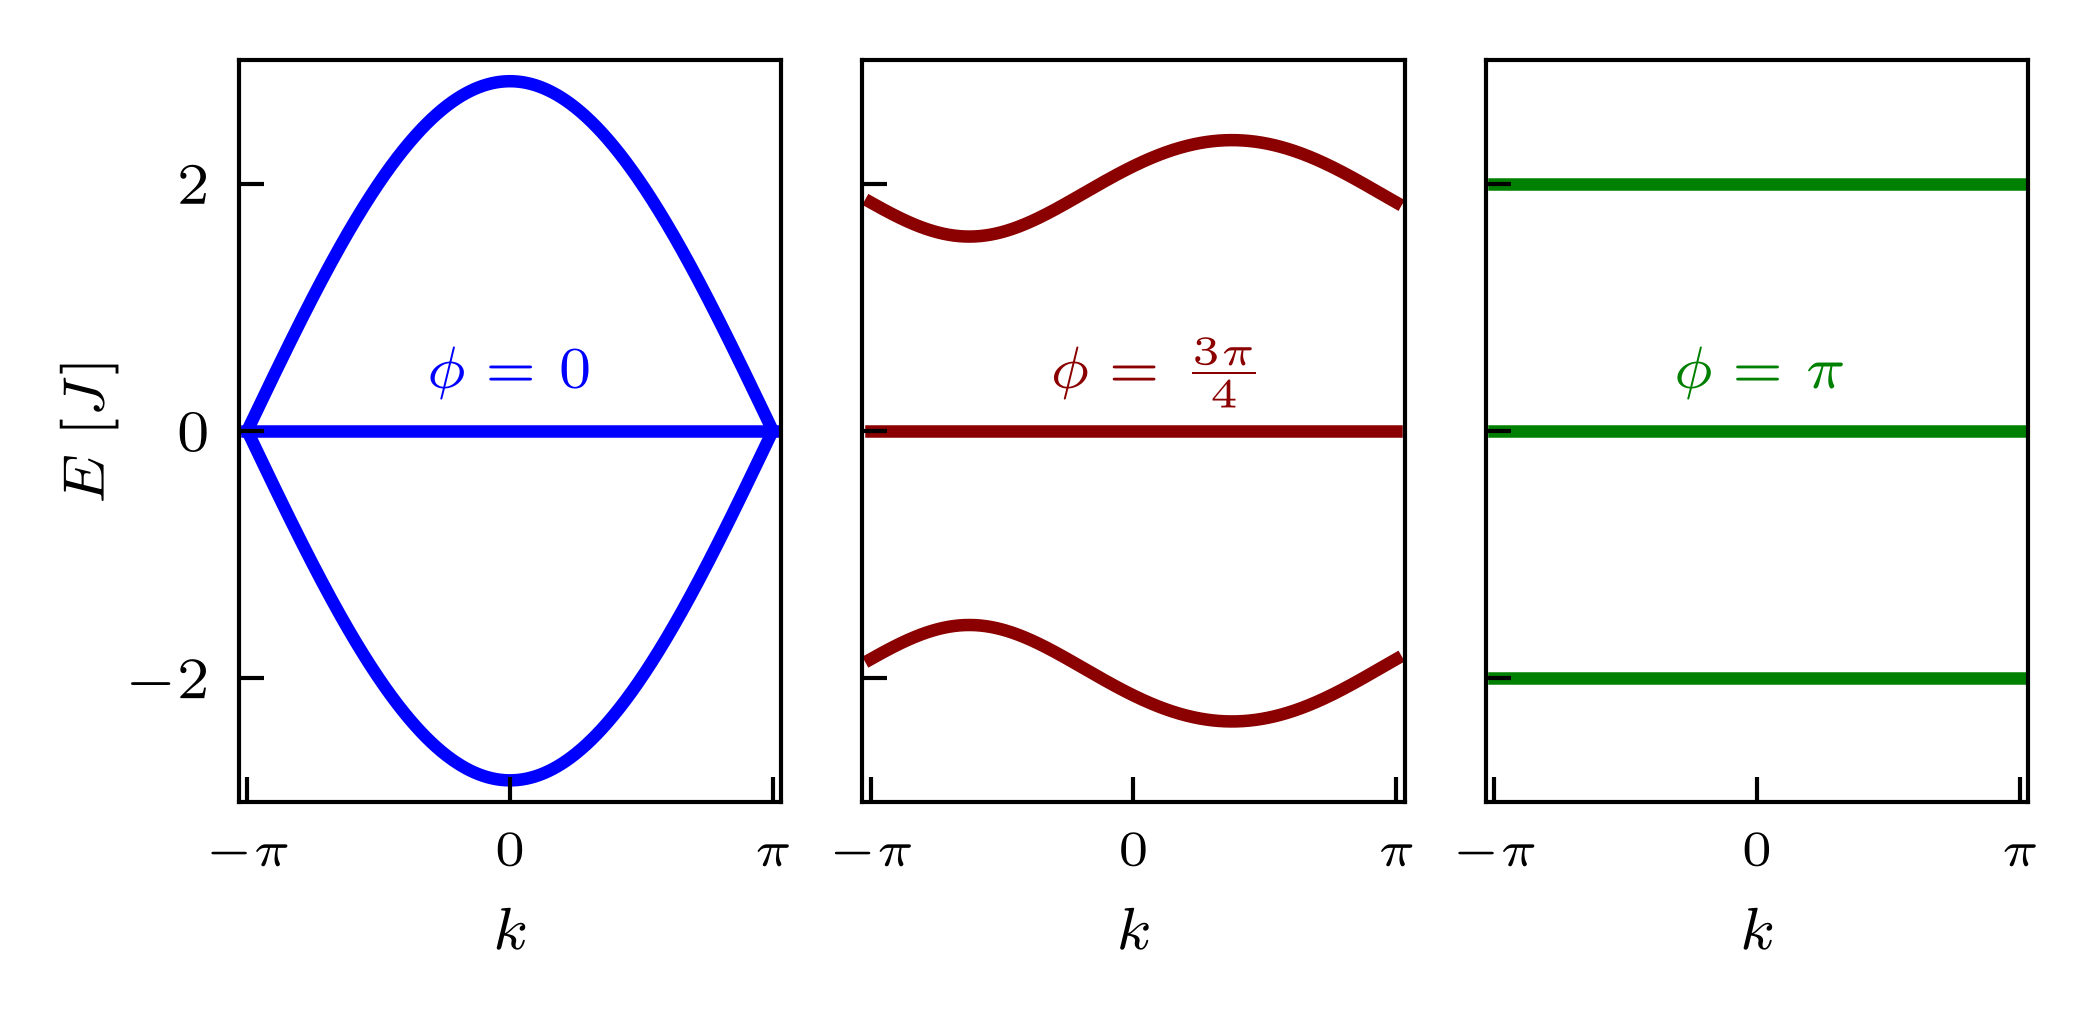

In [4]:
d, p = load_data(DATA / 'Fig01_bulk_bands.npz')
kvals, phivals, bands = d['kvals'], d['phivals'], d['bands']

fig, ax = plt.subplots(1, 3, figsize=(3.5, 1.8), sharey=True)

colors = ['blue', 'darkred', 'green']
labels = ['0', r'$\frac{3\pi}{4}$', r'$\pi$']

for i in range(len(phivals)):
    for j in range(3):
        ax[i].plot(kvals, bands[i, j], lw=1.5, color=colors[i])

    ax[i].set_xticks([-np.pi, 0, np.pi], [r'$-\pi$', r'$0$', r'$\pi$'], fontsize=6)
    ax[i].set_xlim(-np.pi - 0.1, np.pi + 0.1)
    ax[i].set_ylim(-3, 3)
    ax[i].set_yticks([-2, 0, 2])
    ax[i].set_xlabel(r'$k$', fontsize=7)
    ax[i].text(-1, 0.35, rf'$\phi =$ {labels[i]}', fontsize=7, color=colors[i])

ax[0].tick_params(axis='y', labelsize=7)
ax[0].set_ylabel(r'$E \hspace{2pt} [J]$', fontsize=7, labelpad=0.8)

plt.tight_layout()
plt.subplots_adjust(wspace=0.15, right=0.98)
plt.savefig(FIGURES / 'bulk_bands.pdf', transparent=True)

Fig01_finite_chain_vs_flux.npz
    parameters: {'J': 1.0, 'Ncells': 6}
    phivals: shape (200,)
    band_max: shape (200, 3)
    band_min: shape (200, 3)
    E_open: shape (200, 18)
    E_closed: shape (200, 19)


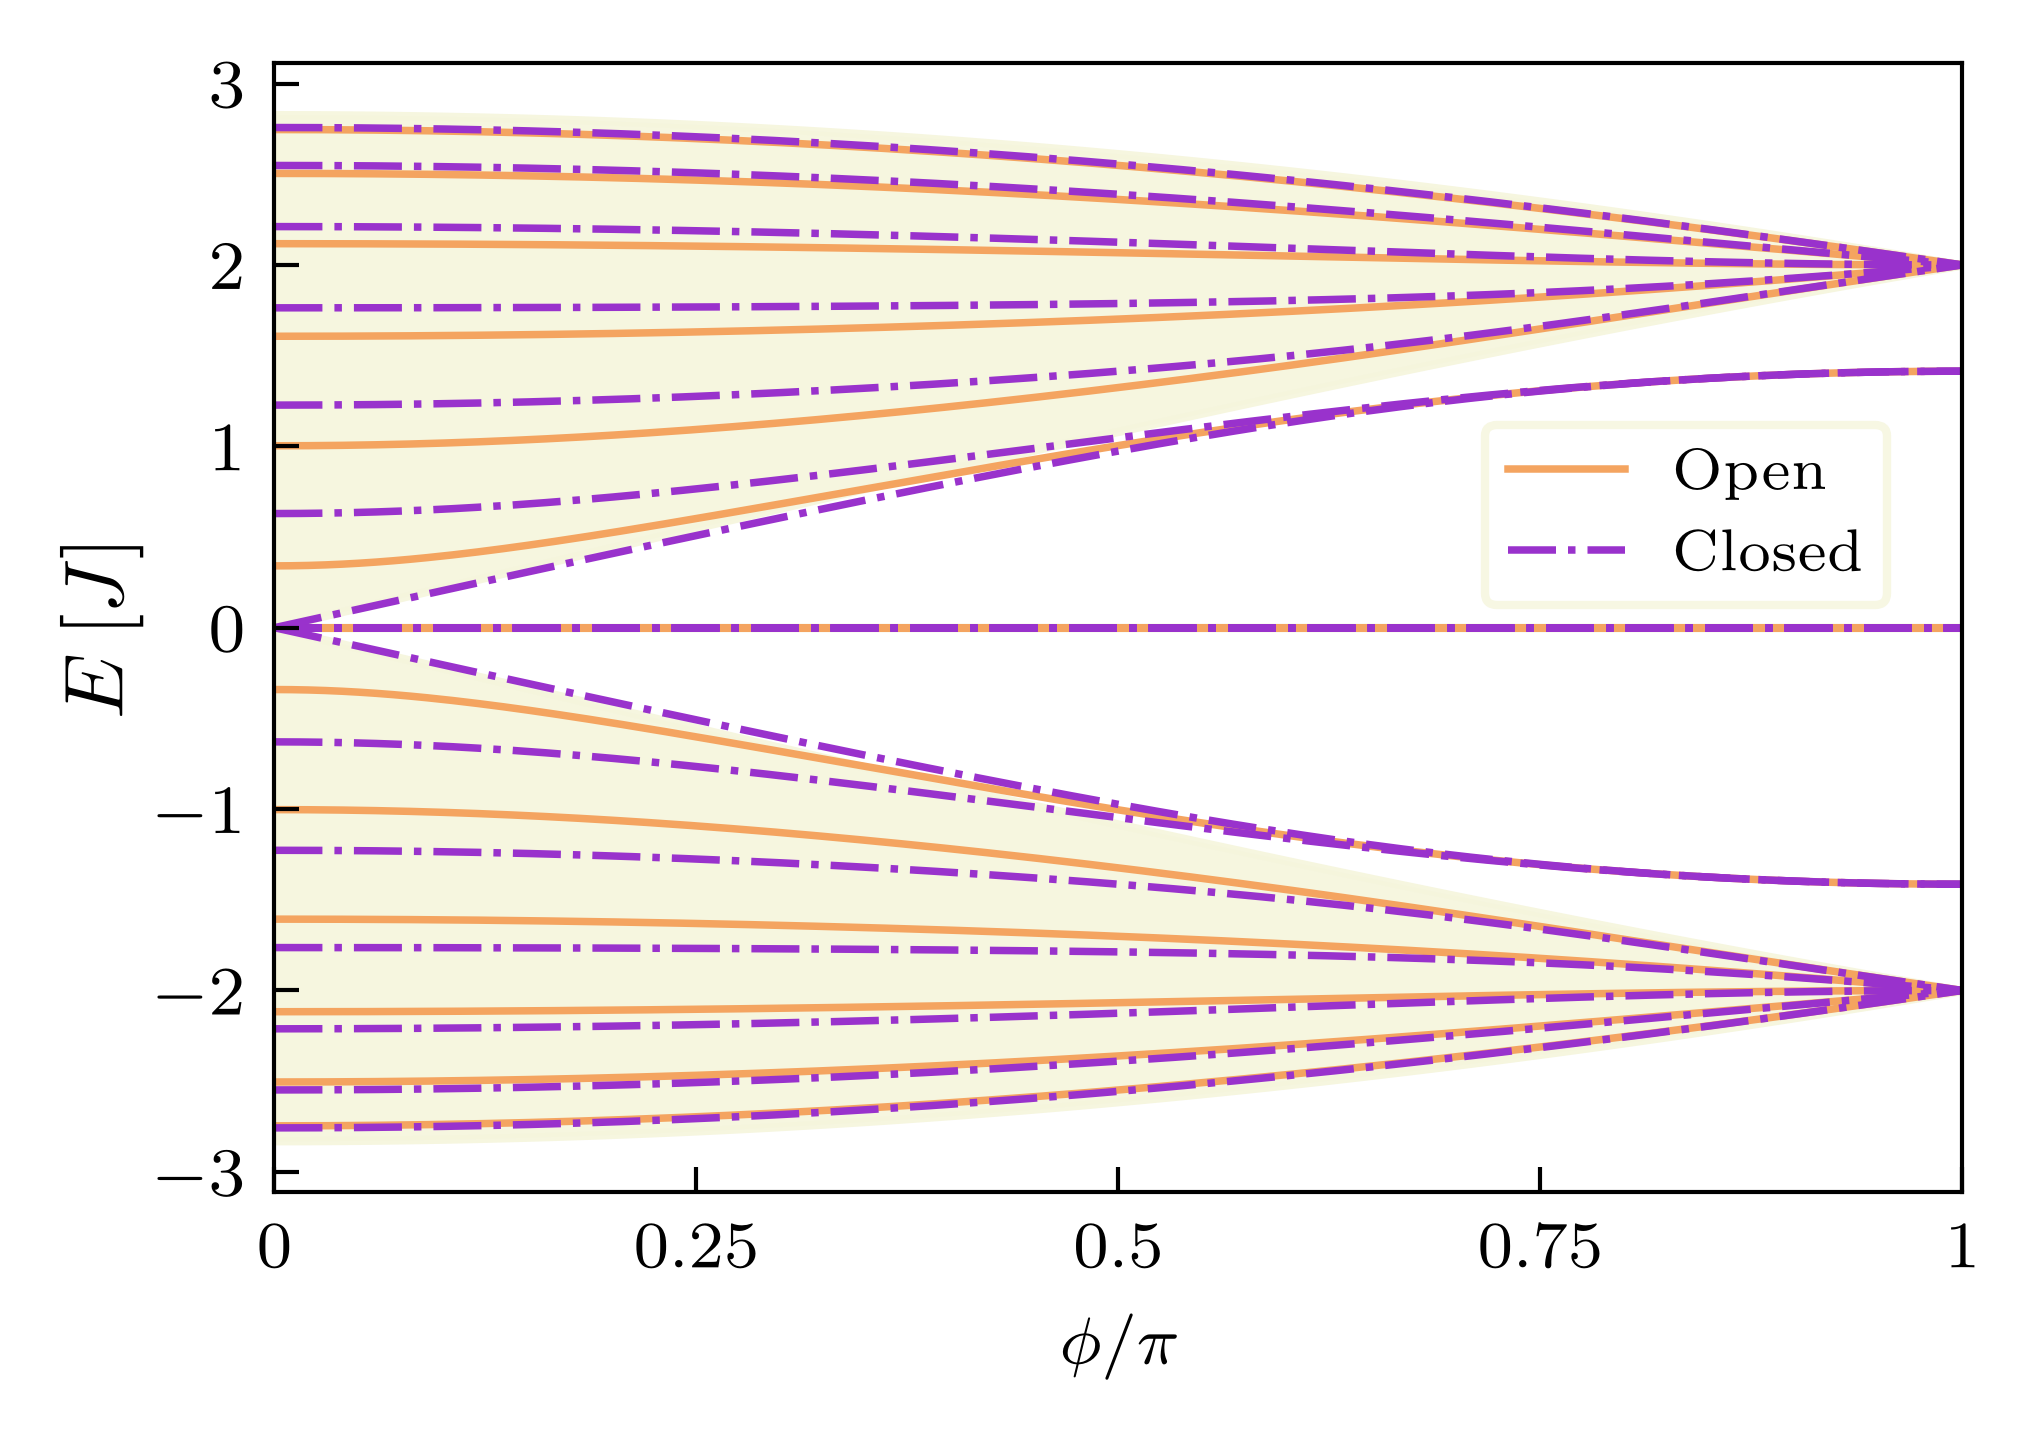

In [5]:
d, p = load_data(DATA / 'Fig01_finite_chain_vs_flux.npz')
phivals, E_open, E_closed = d['phivals'], d['E_open'], d['E_closed']

fig, ax = plt.subplots(figsize=(3.5, 2.5))

for i in range(3):
    ax.fill_between(phivals / np.pi, d['band_min'][:, i], d['band_max'][:, i], color='beige', alpha=0.9)

for i in range(E_open.shape[1]):
    ax.plot(phivals / np.pi, E_open[:, i], color='sandybrown', linewidth=0.9, label='Open' if i == 0 else None)
for i in range(E_closed.shape[1]):
    ax.plot(phivals / np.pi, E_closed[:, i], '-.', color='darkorchid', linewidth=0.9, label='Closed' if i == 0 else None)

ax.legend(bbox_to_anchor=[0.7, 0.6], fontsize=7, frameon=True, edgecolor='beige')
ax.set_xlabel(r'$\phi / \pi$', fontsize=8)
ax.set_xlim(0, 1)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1])
ax.set_xticklabels([0, 0.25, 0.5, 0.75, 1], fontsize=8)
ax.set_ylabel(r'$E \hspace{2pt} [J]$', labelpad=1)

plt.tight_layout()
plt.savefig(FIGURES / 'open_vs_closed.pdf', transparent=True)

## Fig. 2 Quasienergy spectrum vs $\omega$
All $3N+1$ quasienergies of the closed chain are plotted (the original plotting loop skipped the highest one).

Fig02_quasienergies.npz
    parameters: {'J': 1.0, 'phi': 3.141592653589793, 'Ncells': 14, 'Atilde': 1.2, 'nk': 151}
    wvals: shape (450,)
    qk_max_antisymmetric: shape (450, 3)
    qk_min_antisymmetric: shape (450, 3)
    qe_finite_antisymmetric: shape (450, 43)
    qk_max_symmetric: shape (450, 3)
    qk_min_symmetric: shape (450, 3)
    qe_finite_symmetric: shape (450, 43)


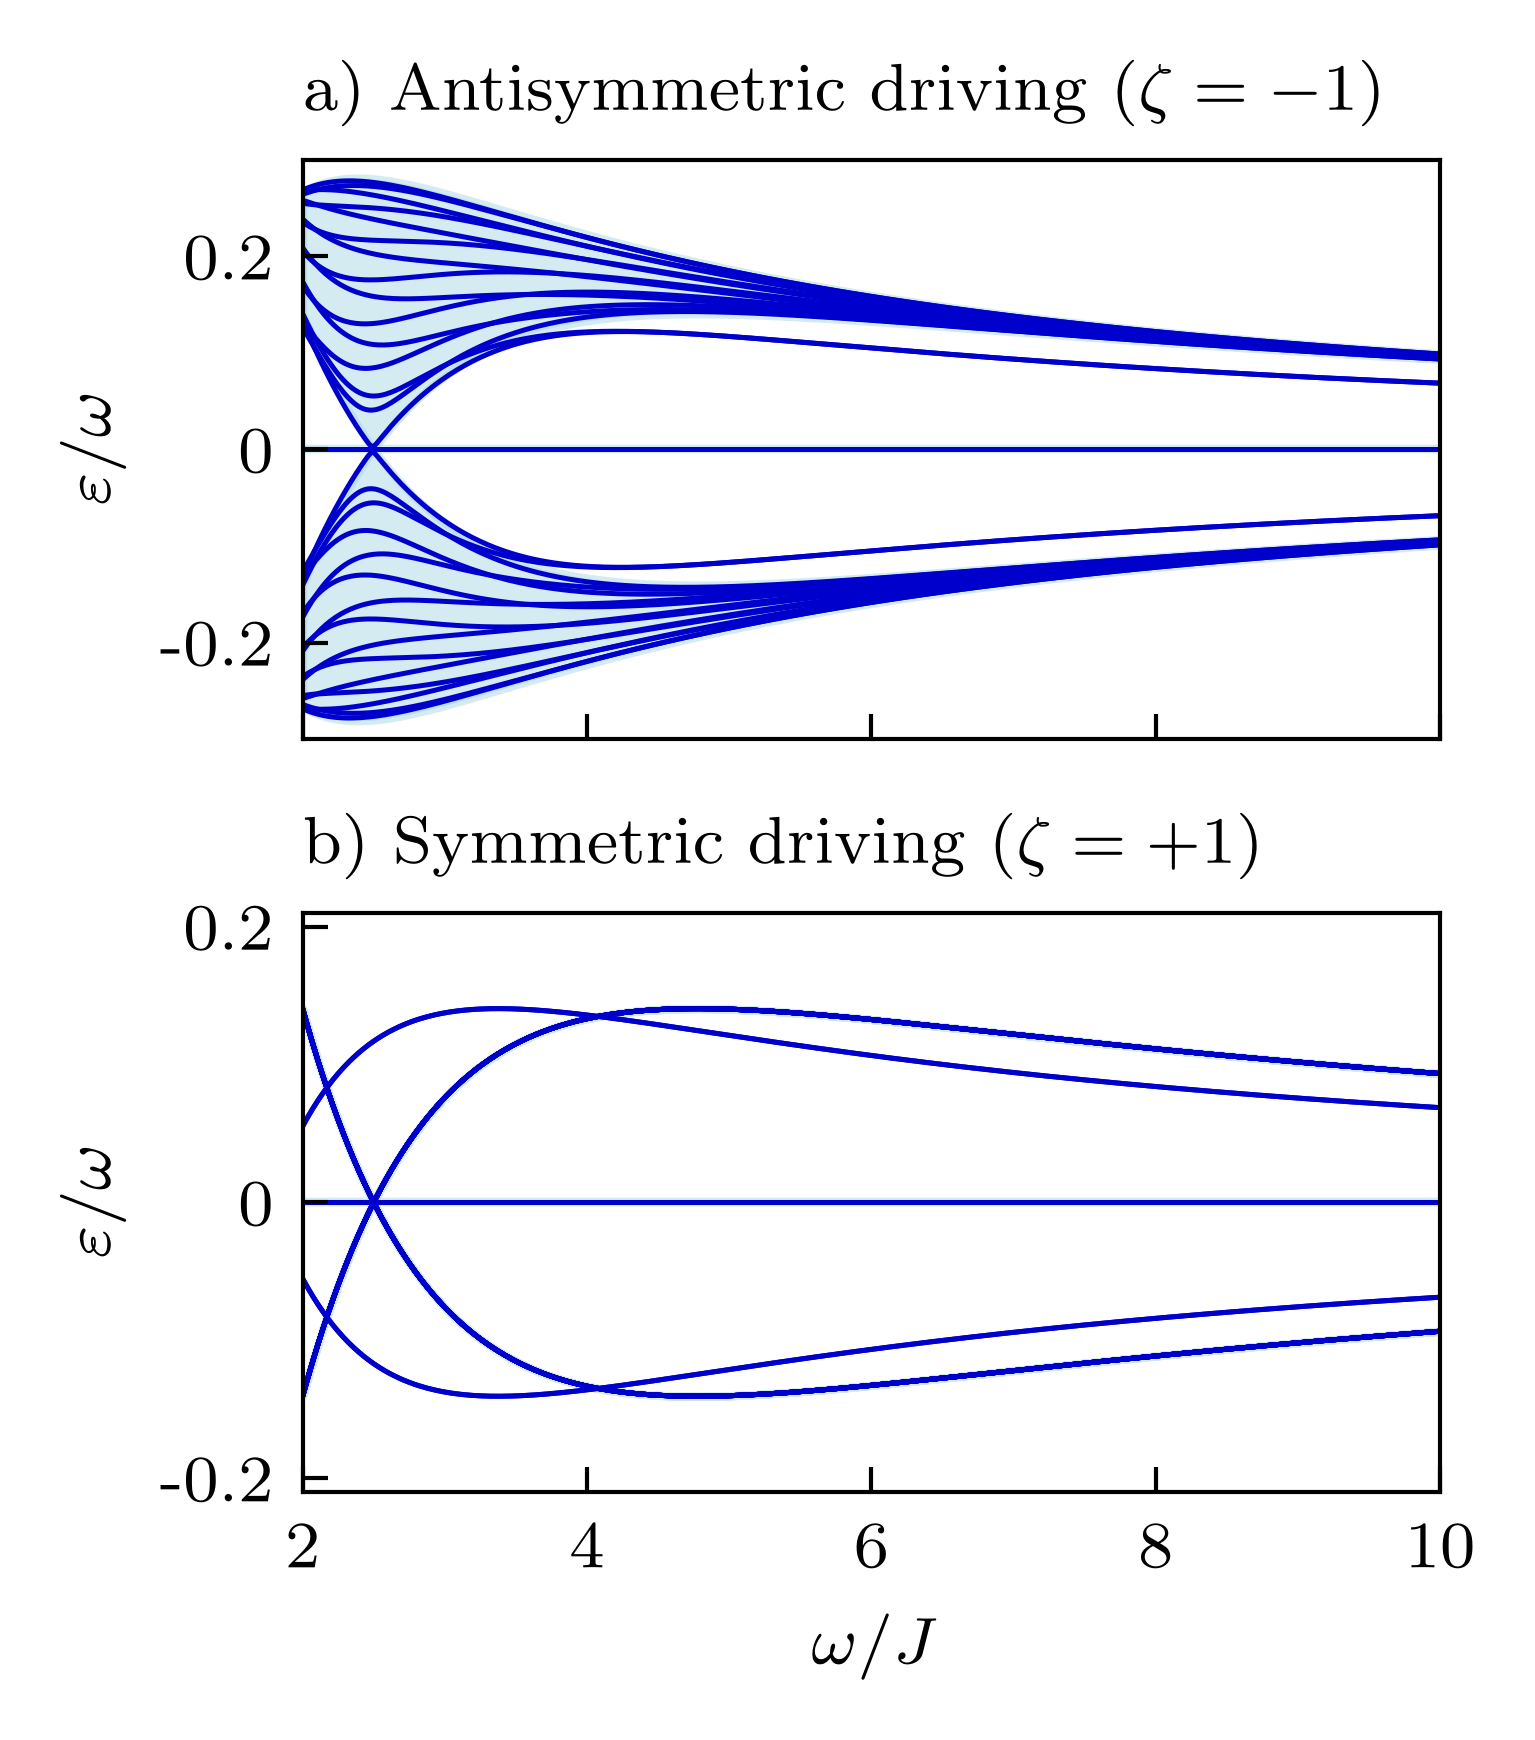

In [6]:
d, p = load_data(DATA / 'Fig02_quasienergies.npz')
wvals = d['wvals']

fig, ax = plt.subplots(2, 1, figsize=(3.5, 3), sharex=True)

for j, label in enumerate(['antisymmetric', 'symmetric']):
    qk_max, qk_min, qe_finite = d[f'qk_max_{label}'], d[f'qk_min_{label}'], d[f'qe_finite_{label}']

    for i in range(3):
        ax[j].fill_between(wvals, qk_min[:, i] / wvals, qk_max[:, i] / wvals, color='lightblue', alpha=0.5)
    for m in range(qe_finite.shape[1]):
        ax[j].plot(wvals, qe_finite[:, m] / wvals, linewidth=0.6, color='mediumblue')

    ax[j].set_ylabel(r'$\varepsilon / \omega$', fontsize=8)
    ax[j].set_xlim(2, 10)
    ax[j].set_yticks([-0.2, 0, 0.2])
    ax[j].set_yticklabels([-0.2, 0, 0.2], fontsize=8)

ax[0].set_ylim(-0.3, 0.3)
ax[1].set_ylim(-0.21, 0.21)
ax[1].set_xlabel(r'$\omega / J$', fontsize=8)
ax[1].set_xticks(np.linspace(2, 10, 5))
ax[1].set_xticklabels([int(i) for i in np.linspace(2, 10, 5)], fontsize=8)
ax[0].set_title(r'a) Antisymmetric driving ($\zeta = -1$)', fontsize=8, loc='left')
ax[1].set_title(r'b) Symmetric driving ($\zeta = +1$)', fontsize=8, loc='left')

plt.tight_layout()
fig.subplots_adjust(right=0.7, hspace=0.3)    # space on the right for the schematics
plt.savefig(FIGURES / 'quasienergies.pdf', transparent=True)

In [7]:
def plot_long_chain_dynamics(populations, tvals, T, Ncells, sublattices, ylabels, height_ratios):
    """Colormaps of log10 P(mT) on the sublattices in `sublattices` (0 = C, 1 = U, 2 = D), around the center of the chain."""
    fig, axs = plt.subplots(len(height_ratios), 1, figsize=(3.5, 3.75), height_ratios=height_ratios)
    cycles_list = np.linspace(0, 400, 5)

    for ax, sub in zip(axs, sublattices):
        nrows = populations[:, sub::3].shape[1]
        # Row k is centered on its site index sub + 3k (0-based); the offset avoids log10(0), drawn transparent
        pcm = ax.imshow(np.log10(populations[:, sub::3].T + 1e-12),
                        extent=[tvals.min() / T, tvals.max() / T, sub - 1.5, sub + 3 * (nrows - 1) + 1.5],
                        aspect='auto', origin='lower', vmin=-5, vmax=0, interpolation='none', cmap='YlGnBu_r')
        ax.tick_params(axis='both', direction='out')
        ax.set_xticks(cycles_list)
        ax.set_xticklabels([])

    # One tick per cell (cells 43 to 59), labels every 4 cells, cells counted from 1: the tick of cell n sits on the
    # row of site (sublattice, n), i.e. site index 3 (n - 1) + sub. The central cell of the N = 100 chain is n = 51.
    cells = np.arange(43, 60)
    for ax, sub, ylabel in zip(axs, sublattices, ylabels):
        t = 3 * (cells - 1) + sub
        ax.set_ylim(t[0] - 1.5, t[-1] + 1.5)
        ax.set_yticks(t[::4])
        ax.set_yticklabels([f'${c}$' for c in cells[::4]], fontsize=8)
        ax.set_yticks(np.setdiff1d(t, t[::4]), minor=True)
        ax.tick_params(axis='y', which='major', length=4, direction='out')
        ax.tick_params(axis='y', which='minor', length=2, direction='out', color='gray')
        ax.set_ylabel(ylabel, fontsize=8)

    return fig, axs, pcm


def add_colorbar(fig, pcm, ax_top, ax_bottom, shrink, pad=0.015, width=0.02):
    """Vertical colorbar to the right of ax_top...ax_bottom, centered and shrunk by `shrink`."""
    y_bottom, y_top = ax_bottom.get_position().y0, ax_top.get_position().y1
    height = (y_top - y_bottom) * shrink
    cax = fig.add_axes([ax_top.get_position().x1 + pad, (y_top + y_bottom) / 2 - height / 2, width, height])
    cbar = fig.colorbar(pcm, cax=cax, ticks=[-5, -4, -3, -2, -1, 0])
    cbar.ax.tick_params(labelsize=6)
    cbar.set_ticklabels([rf'$10^{{{i}}}$' for i in range(-5, 1)])
    cbar.set_label(r'$P_{\alpha_i}(mT)$', fontsize=6)
    return cbar

## Fig. 4 Dynamics starting from the central $C$ site
Panels a)–c); panel d) is a schematic. Cells are counted from 1: the initial state is the central site $C_{51}$ (site index 150).

Fig04_dynamics_C_site.npz
    parameters: {'J': 1.0, 'phi': 3.141592653589793, 'Ncells': 100, 'w': 8, 'A': 9.6, 'zeta': -1, 'ncycles': 400, 'initial_site': 150}
    tvals: shape (401,)
    populations: shape (401, 301)


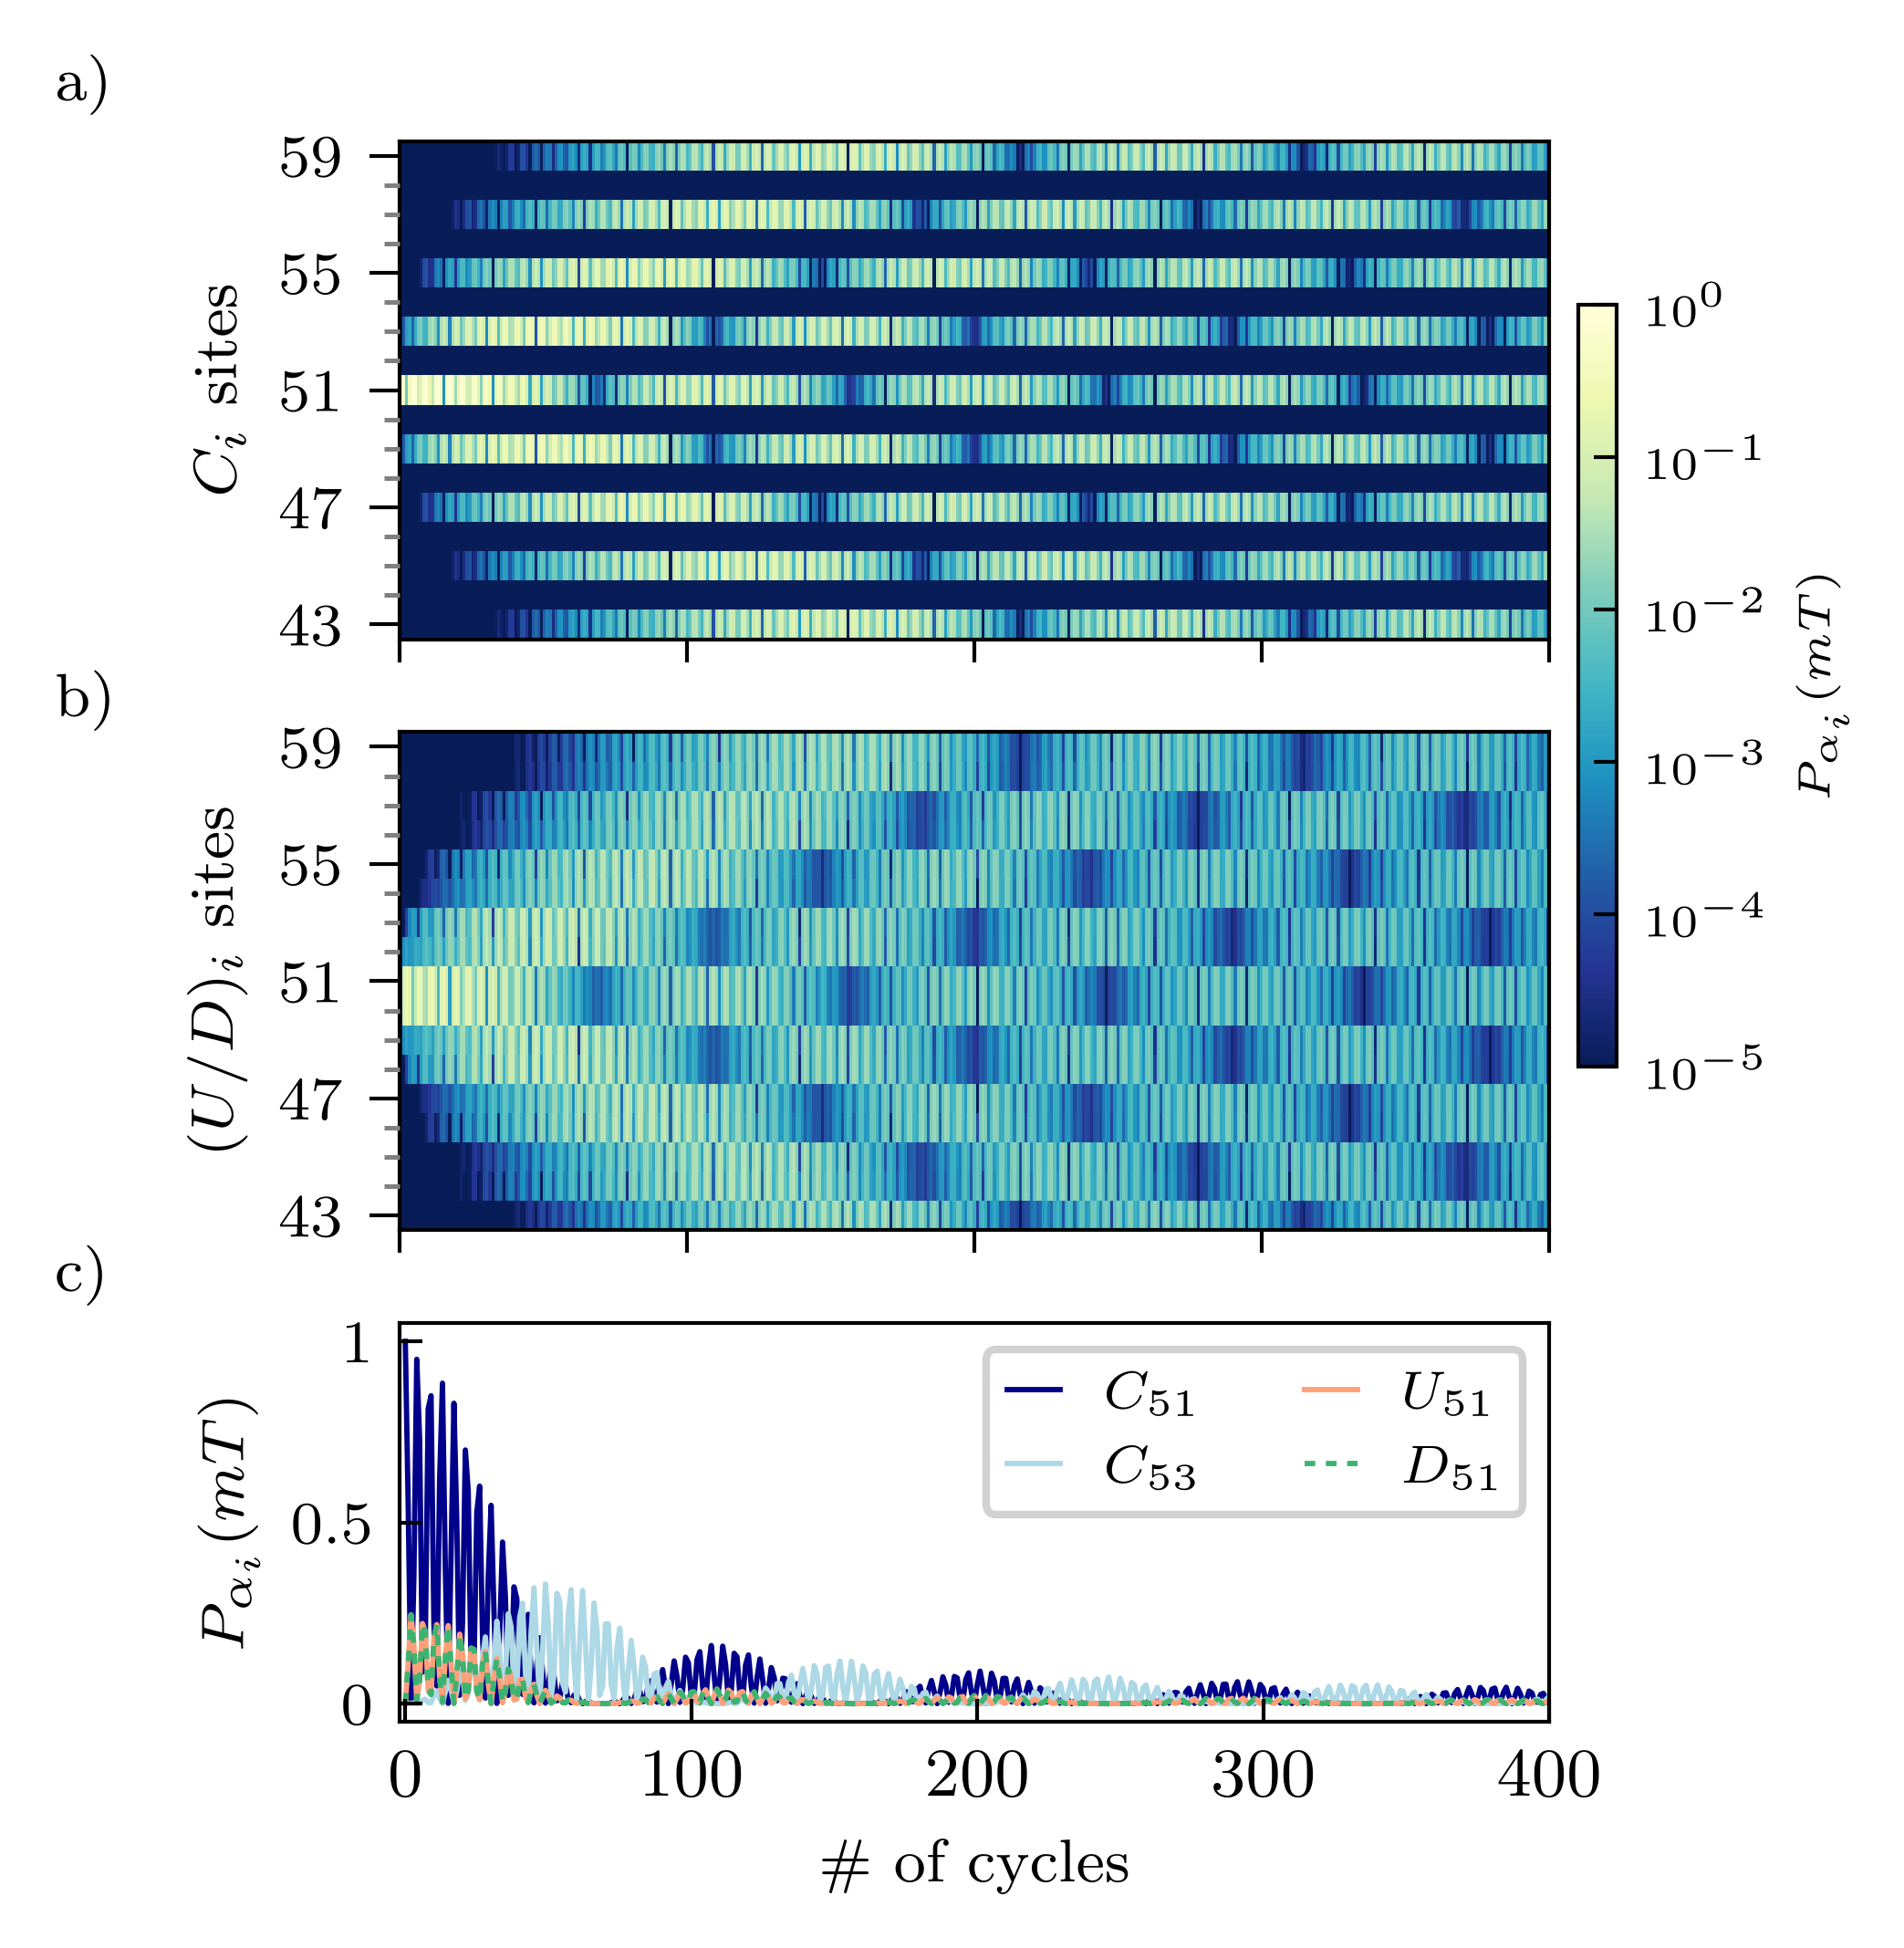

In [8]:
d, p = load_data(DATA / 'Fig04_dynamics_C_site.npz')
populations, tvals, Ncells = d['populations'], d['tvals'], p['Ncells']
T = 2 * np.pi / p['w']

fig, axs, pcm = plot_long_chain_dynamics(populations, tvals, T, Ncells, sublattices=[0, 1],
                                         ylabels=[r'$C_i$ sites', r'$(U/D)_i$ sites'], height_ratios=[1, 1, 0.8])
fig.subplots_adjust(right=0.8, left=0.2, hspace=0.2)
add_colorbar(fig, pcm, axs[0], axs[1], shrink=0.7)

# c) occupation of selected sites (index 150 = central C site)
i0 = 3 * Ncells // 2
axs[2].plot(tvals / T, populations[:, i0], linewidth=0.7, color='darkblue', label=r'$C_{51}$')
axs[2].plot(tvals / T, populations[:, i0 + 6], linewidth=0.7, color='lightblue', label=r'$C_{53}$')
axs[2].plot(tvals / T, populations[:, i0 + 1], linewidth=0.7, color='lightsalmon', label=r'$U_{51}$')
axs[2].plot(tvals / T, populations[:, i0 + 2], linewidth=0.7, linestyle='--', dashes=[2, 2], color='mediumseagreen', label=r'$D_{51}$')
axs[2].legend(fontsize=7, ncols=2, handlelength=1, loc='upper right', framealpha=0.9)

cycles_list = np.linspace(0, 400, 5)
axs[2].set_xlim([-2, 400])
axs[2].set_xticks(cycles_list)
axs[2].set_xticklabels([int(i) for i in cycles_list], fontsize=9)
axs[2].set_xlabel(r'$\#$ of cycles', fontsize=8)
axs[2].set_ylabel(r'$P_{\alpha_i}(mT)$', fontsize=8)
axs[2].set_yticks([0, 0.5, 1])
axs[2].set_yticklabels([0, 0.5, 1], fontsize=8)

plt.text(0.02, 0.9, r'a)', fontsize=8, transform=fig.transFigure)
plt.text(0.02, 0.6, r'b)', fontsize=8, transform=fig.transFigure)
plt.text(0.02, 0.32, r'c)', fontsize=8, transform=fig.transFigure)

plt.savefig(FIGURES / 'dynamics_starting_csite.pdf', transparent=True)

## Fig. 5 — Edge states of the driven chain
The labels (1)–(4) now refer to the same states in both panels (in the original code the profiles of (1) and (2) were swapped).

Fig05_driven_edge_states.npz
    parameters: {'J': 1.0, 'phi': 3.141592653589793, 'Ncells': 14, 'w': 8, 'A': 9.6, 'zeta': -1}
    quasienergies: shape (43,)
    modes: shape (43, 43)


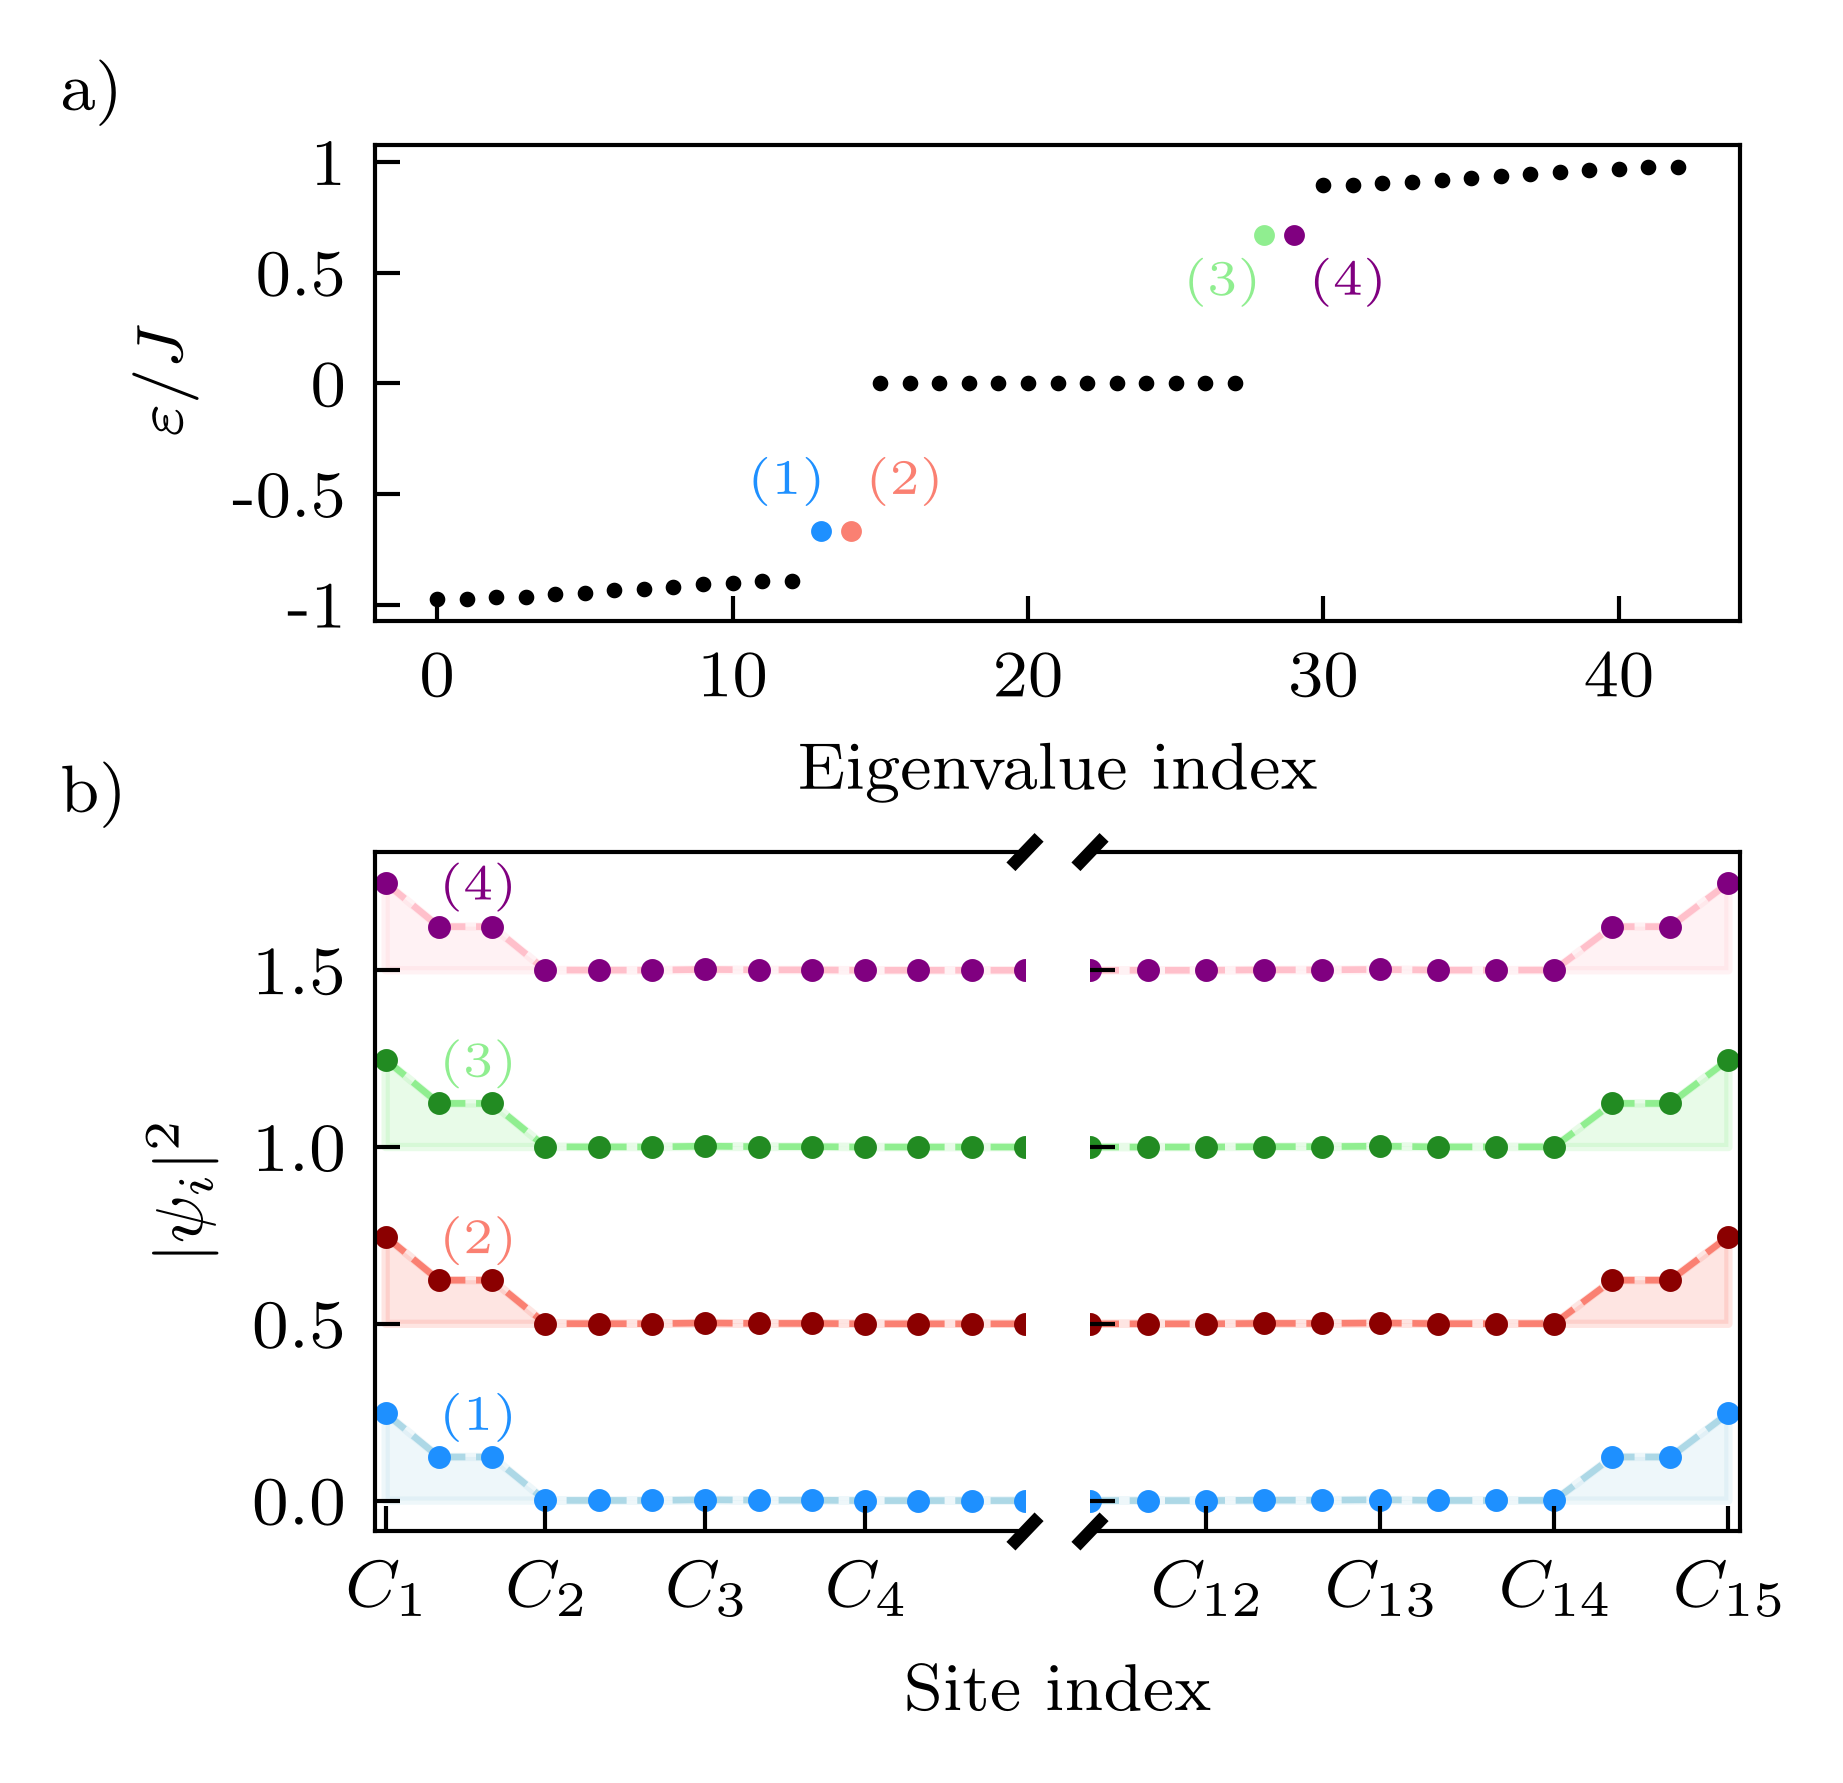

In [9]:
d, p = load_data(DATA / 'Fig05_driven_edge_states.npz')
qe, modes, Ncells = d['quasienergies'], d['modes'], p['Ncells']

edge = [Ncells - 1, Ncells, 2 * Ncells, 2 * Ncells + 1]          # states (1), (2), (3), (4)
dot_colors = ['dodgerblue', 'salmon', 'lightgreen', 'purple']
line_colors = ['lightblue', 'salmon', 'lightgreen', 'pink']
mark_colors = ['dodgerblue', 'darkred', 'forestgreen', 'purple']
label_pos_a = [(Ncells - 3.5, -0.5), (Ncells + 0.5, -0.5), (2 * Ncells - 2.75, 0.4), (2 * Ncells + 1.5, 0.4)]

fig, ax = plt.subplot_mosaic([['A', 'A'], ['B', 'C']], figsize=(3.5, 3.), height_ratios=[0.7, 1],
                             gridspec_kw={'wspace': 0.1, 'hspace': 0.4, 'left': 0.2, 'right': 0.85})

# a) quasienergies
ax['A'].plot(qe, '.', markersize=1.75, color='black')
for n, (idx, c, pos) in enumerate(zip(edge, dot_colors, label_pos_a)):
    ax['A'].plot(idx, qe[idx], '.', markersize=3, color=c)
    ax['A'].text(*pos, rf'$({n + 1})$', color=c, fontsize=6)

ax['A'].set_yticks([-1, -0.5, 0, 0.5, 1])
ax['A'].set_yticklabels([-1, -0.5, 0, 0.5, 1], fontsize=8)
ax['A'].set_ylabel(r'$\varepsilon / J$', fontsize=8)
ax['A'].set_xlabel(r'Eigenvalue index', fontsize=8)
ax['A'].tick_params(axis='both', which='major', labelsize=8)

# b) edge-state profiles, shifted vertically; the bulk of the chain is cut out
x = np.arange(3 * Ncells + 1)
ms, alpha = 3.5, 0.2
for axis in (ax['B'], ax['C']):
    for n, idx in enumerate(edge):
        y = 0.5 * n + np.abs(modes[:, idx]) ** 2
        axis.plot(x, y, '--', linewidth=0.8, color=line_colors[n])
        axis.plot(x, y, '.', markersize=ms, color=mark_colors[n])
        axis.fill_between(x, 0.5 * n, y, color=line_colors[n], alpha=alpha)
for n in range(4):
    ax['B'].text(1, 0.2 + 0.5 * n, rf'$({n + 1})$', color=dot_colors[n], fontsize=6)

ax['B'].set_xticks([0, 3, 6, 9])
ax['B'].set_xticklabels([r'$C_1$', r'$C_2$', r'$C_3$', r'$C_4$'], fontsize=8)
ax['B'].set_xlim(-0.2, 12)
ax['C'].sharey(ax['B'])
ax['C'].set_xticks([33, 36, 39, 42])
ax['C'].set_xticklabels([r'$C_{12}$', r'$C_{13}$', r'$C_{14}$', r'$C_{15}$'], fontsize=8)
ax['C'].set_xlim(31, x.max() + 0.2)

# Broken axis
ax['B'].spines['right'].set_visible(False)
ax['C'].spines['left'].set_visible(False)
ax['C'].tick_params(labelleft=False)
dd = 0.015
kwargs = dict(transform=ax['B'].transAxes, color='k', clip_on=False)
ax['B'].plot((1 - dd, 1 + dd), (-dd, +dd), **kwargs)
ax['B'].plot((1 - dd, 1 + dd), (1 - dd, 1 + dd), **kwargs)
kwargs.update(transform=ax['C'].transAxes)
ax['C'].plot((-dd, +dd), (-dd, +dd), **kwargs)
ax['C'].plot((-dd, +dd), (1 - dd, 1 + dd), **kwargs)

x_center = 0.5 * (ax['B'].get_position().x0 + ax['C'].get_position().x1)
fig.text(x_center, 0.02, r'Site index', ha='center', va='center', fontsize=8)
ax['B'].set_ylabel(r'$\vert \psi_i \vert^2$', fontsize=8)

plt.text(0.05, 0.9, r'a)', fontsize=8, transform=fig.transFigure)
plt.text(0.05, 0.51, r'b)', fontsize=8, transform=fig.transFigure)

plt.savefig(FIGURES / 'edgestates_driven.pdf', bbox_inches='tight', transparent=True)

## Fig. 6 — Dynamics in short chains
The colorbar is linear in $P_{\alpha_i}(mT)$ (the published colorbar is labelled $\log_{10}(P_{\alpha_i})$, but the scale is linear).

Fig06_short_chain_dynamics.npz
    parameters: {'J': 1.0, 'phi': 3.141592653589793, 'w': 8, 'A': 9.6, 'zeta': -1, 'ncycles': 500, 'initial_site': 'C_1'}
    tvals: shape (501,)
    populations_N2: shape (501, 7)
    populations_N3: shape (501, 10)


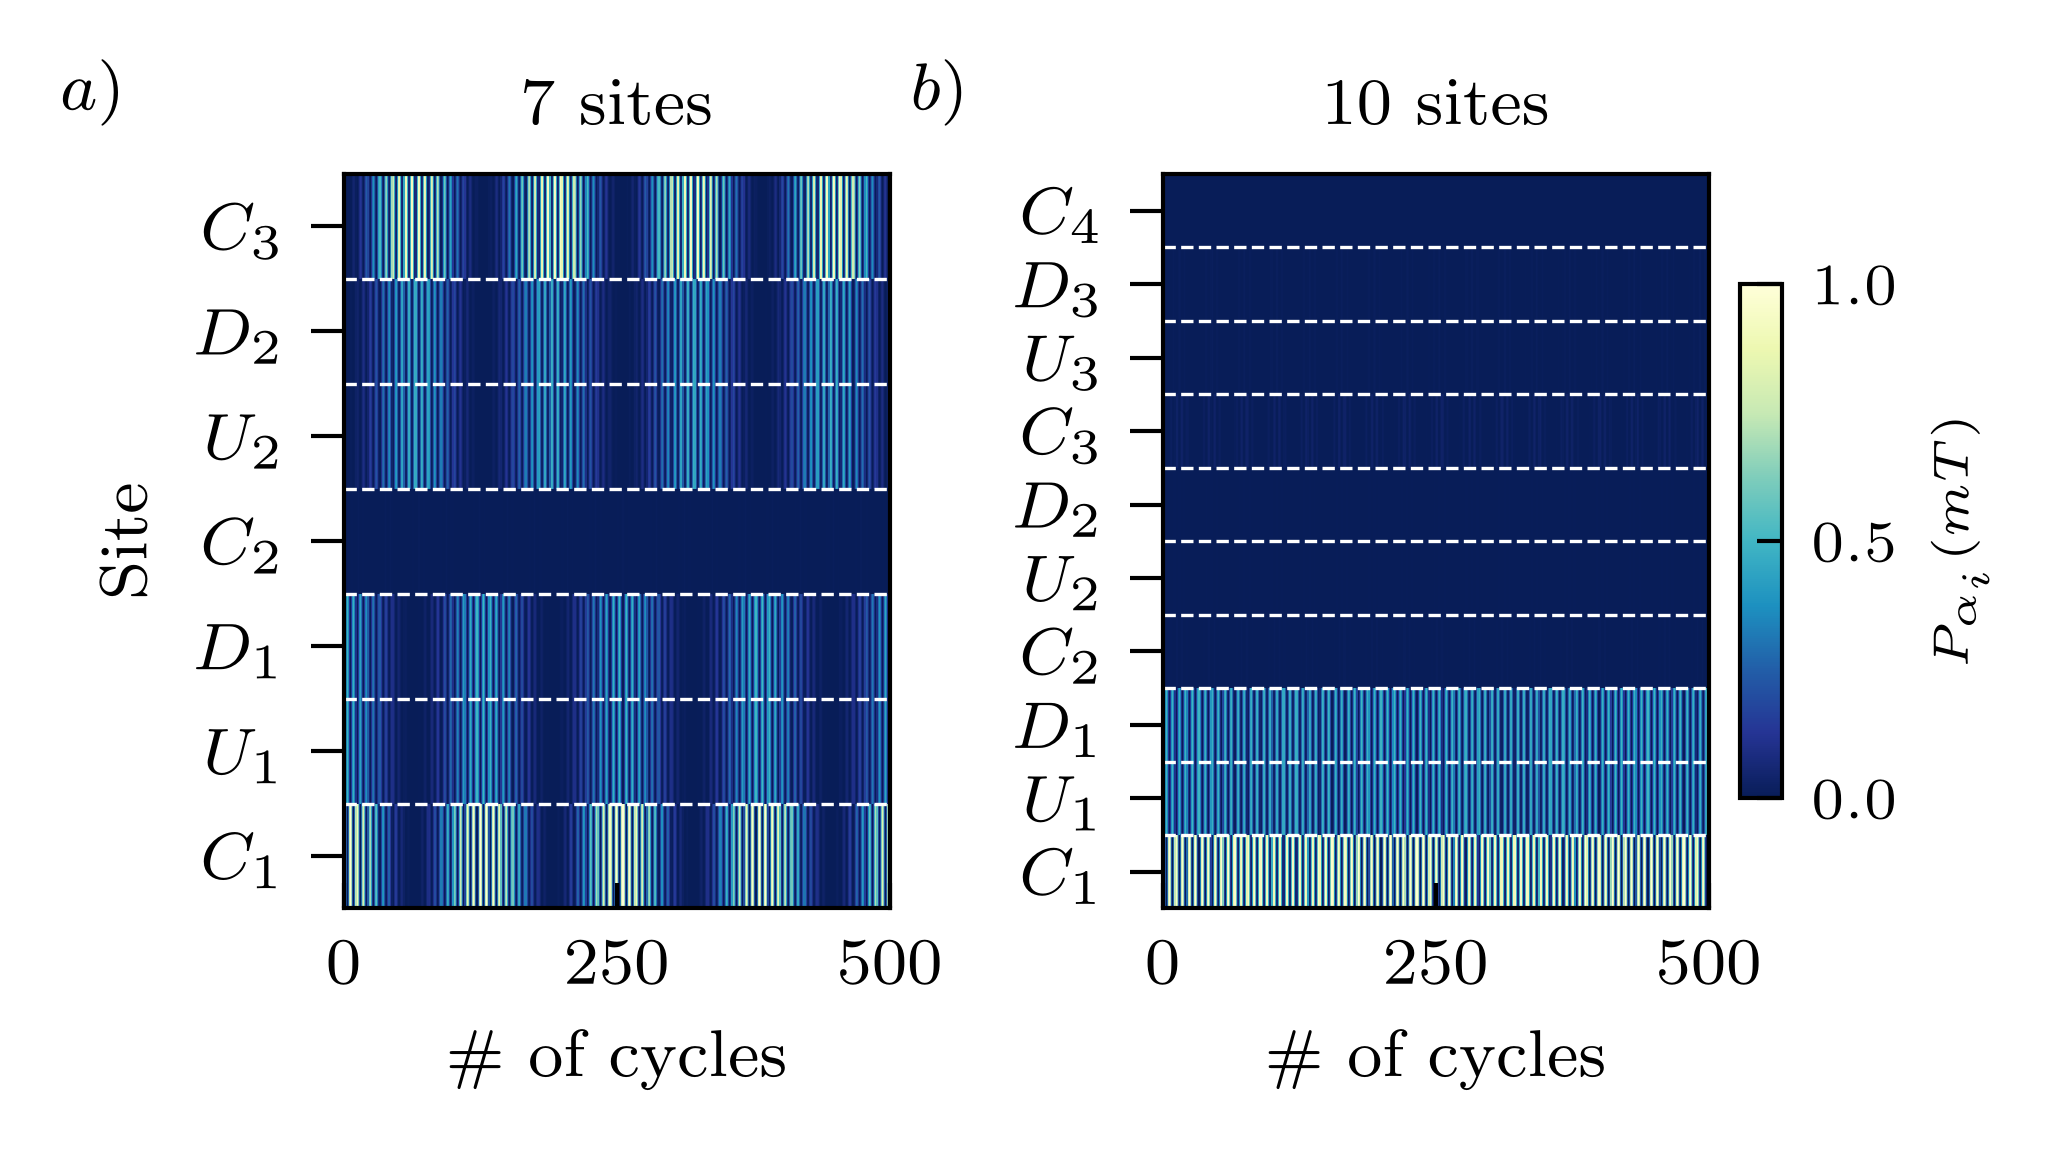

In [10]:
d, p = load_data(DATA / 'Fig06_short_chain_dynamics.npz')
tvals = d['tvals']
T = 2 * np.pi / p['w']

fig, ax = plt.subplots(1, 2, figsize=(3.5, 1.8))

for axis, Ncells in zip(ax, (2, 3)):
    nsites = 3 * Ncells + 1
    pcm = axis.imshow(d[f'populations_N{Ncells}'].T, extent=[tvals.min() / T, tvals.max() / T, 0, nsites - 1],
                      aspect='auto', origin='lower', vmin=0, vmax=1, interpolation='none', cmap='YlGnBu_r')
    row = (nsites - 1) / nsites                   # height of one row
    axis.set_ylim(0, nsites - 1)
    axis.set_yticks(row / 2 + row * np.arange(nsites))
    names = [f'${s}_{n + 1}$' for n in range(Ncells) for s in 'CUD'] + [f'$C_{Ncells + 1}$']
    axis.set_yticklabels(names, fontsize=8)
    for i in range(nsites - 1):
        axis.axhline((i + 1) * row, linewidth=0.4, linestyle='--', color='w')
    axis.set_xlim(0, tvals.max() / T)
    axis.set_xticks([0, 250, 500])
    axis.set_xticklabels([0, 250, 500], fontsize=8)
    axis.set_xlabel(r'$\#$ of cycles', fontsize=8)
    axis.set_title(rf'${nsites}$ sites', fontsize=8)
    axis.tick_params(axis='y', which='major', length=4, direction='out')

ax[0].set_ylabel(r'Site', fontsize=8)
fig.subplots_adjust(left=0.15, wspace=0.5, bottom=0.2, right=0.8)

pos = ax[1].get_position()
cb_height = pos.height * 0.7
cax = fig.add_axes([pos.x1 + 0.015, pos.y0 + pos.height / 2 - cb_height / 2, 0.02, cb_height])
cbar = fig.colorbar(pcm, cax=cax)
cbar.set_ticks([0, 0.5, 1])
cbar.ax.tick_params(labelsize=7)
cbar.set_label(r'$P_{\alpha_i}(mT)$', fontsize=6)

plt.text(0.015, 0.94, r'$a)$', fontsize=8, transform=fig.transFigure)
plt.text(0.42, 0.94, r'$b)$', fontsize=8, transform=fig.transFigure)

plt.savefig(FIGURES / 'short_dynamics.pdf', transparent=True)

## Fig. 7 — Two-particle entanglement dynamics
Vertical lines: oscillation periods $2\pi/\omega_\mathrm{FT}$ of the dominant Fourier components of $S^{(A)}$ (Fig. A9), and the special point $m = 106$.

Fig07_entanglement_V0.npz
    parameters: {'Ncells': 2, 'Nup': 2, 'Ndown': 0, 'J': 1.0, 'phi': 3.141592653589793, 'w': 8, 'A': 9.6, 'zeta': -1, 'V': 0.0, 'A_spec': [['C', 1], ['U', 1], ['D', 1]], 'psi0_binary': '1000001|0000000', 'ncycles': 400}
    tvals: shape (401,)
    densities: shape (7, 401)
    S_A: shape (401,)
    p11: shape (401,)
    S_11: shape (401,)
    E_P: shape (401,)
Fig07_entanglement_V0.2.npz
    parameters: {'Ncells': 2, 'Nup': 2, 'Ndown': 0, 'J': 1.0, 'phi': 3.141592653589793, 'w': 8, 'A': 9.6, 'zeta': -1, 'V': 0.2, 'A_spec': [['C', 1], ['U', 1], ['D', 1]], 'psi0_binary': '1000001|0000000', 'ncycles': 400}
    tvals: shape (401,)
    densities: shape (7, 401)
    S_A: shape (401,)
    p11: shape (401,)
    S_11: shape (401,)
    E_P: shape (401,)
At m = 106 (V = 0.2): p11 = 0.9984, S_A = 0.6957, E_P = 0.6826, P_C1 = 0.523


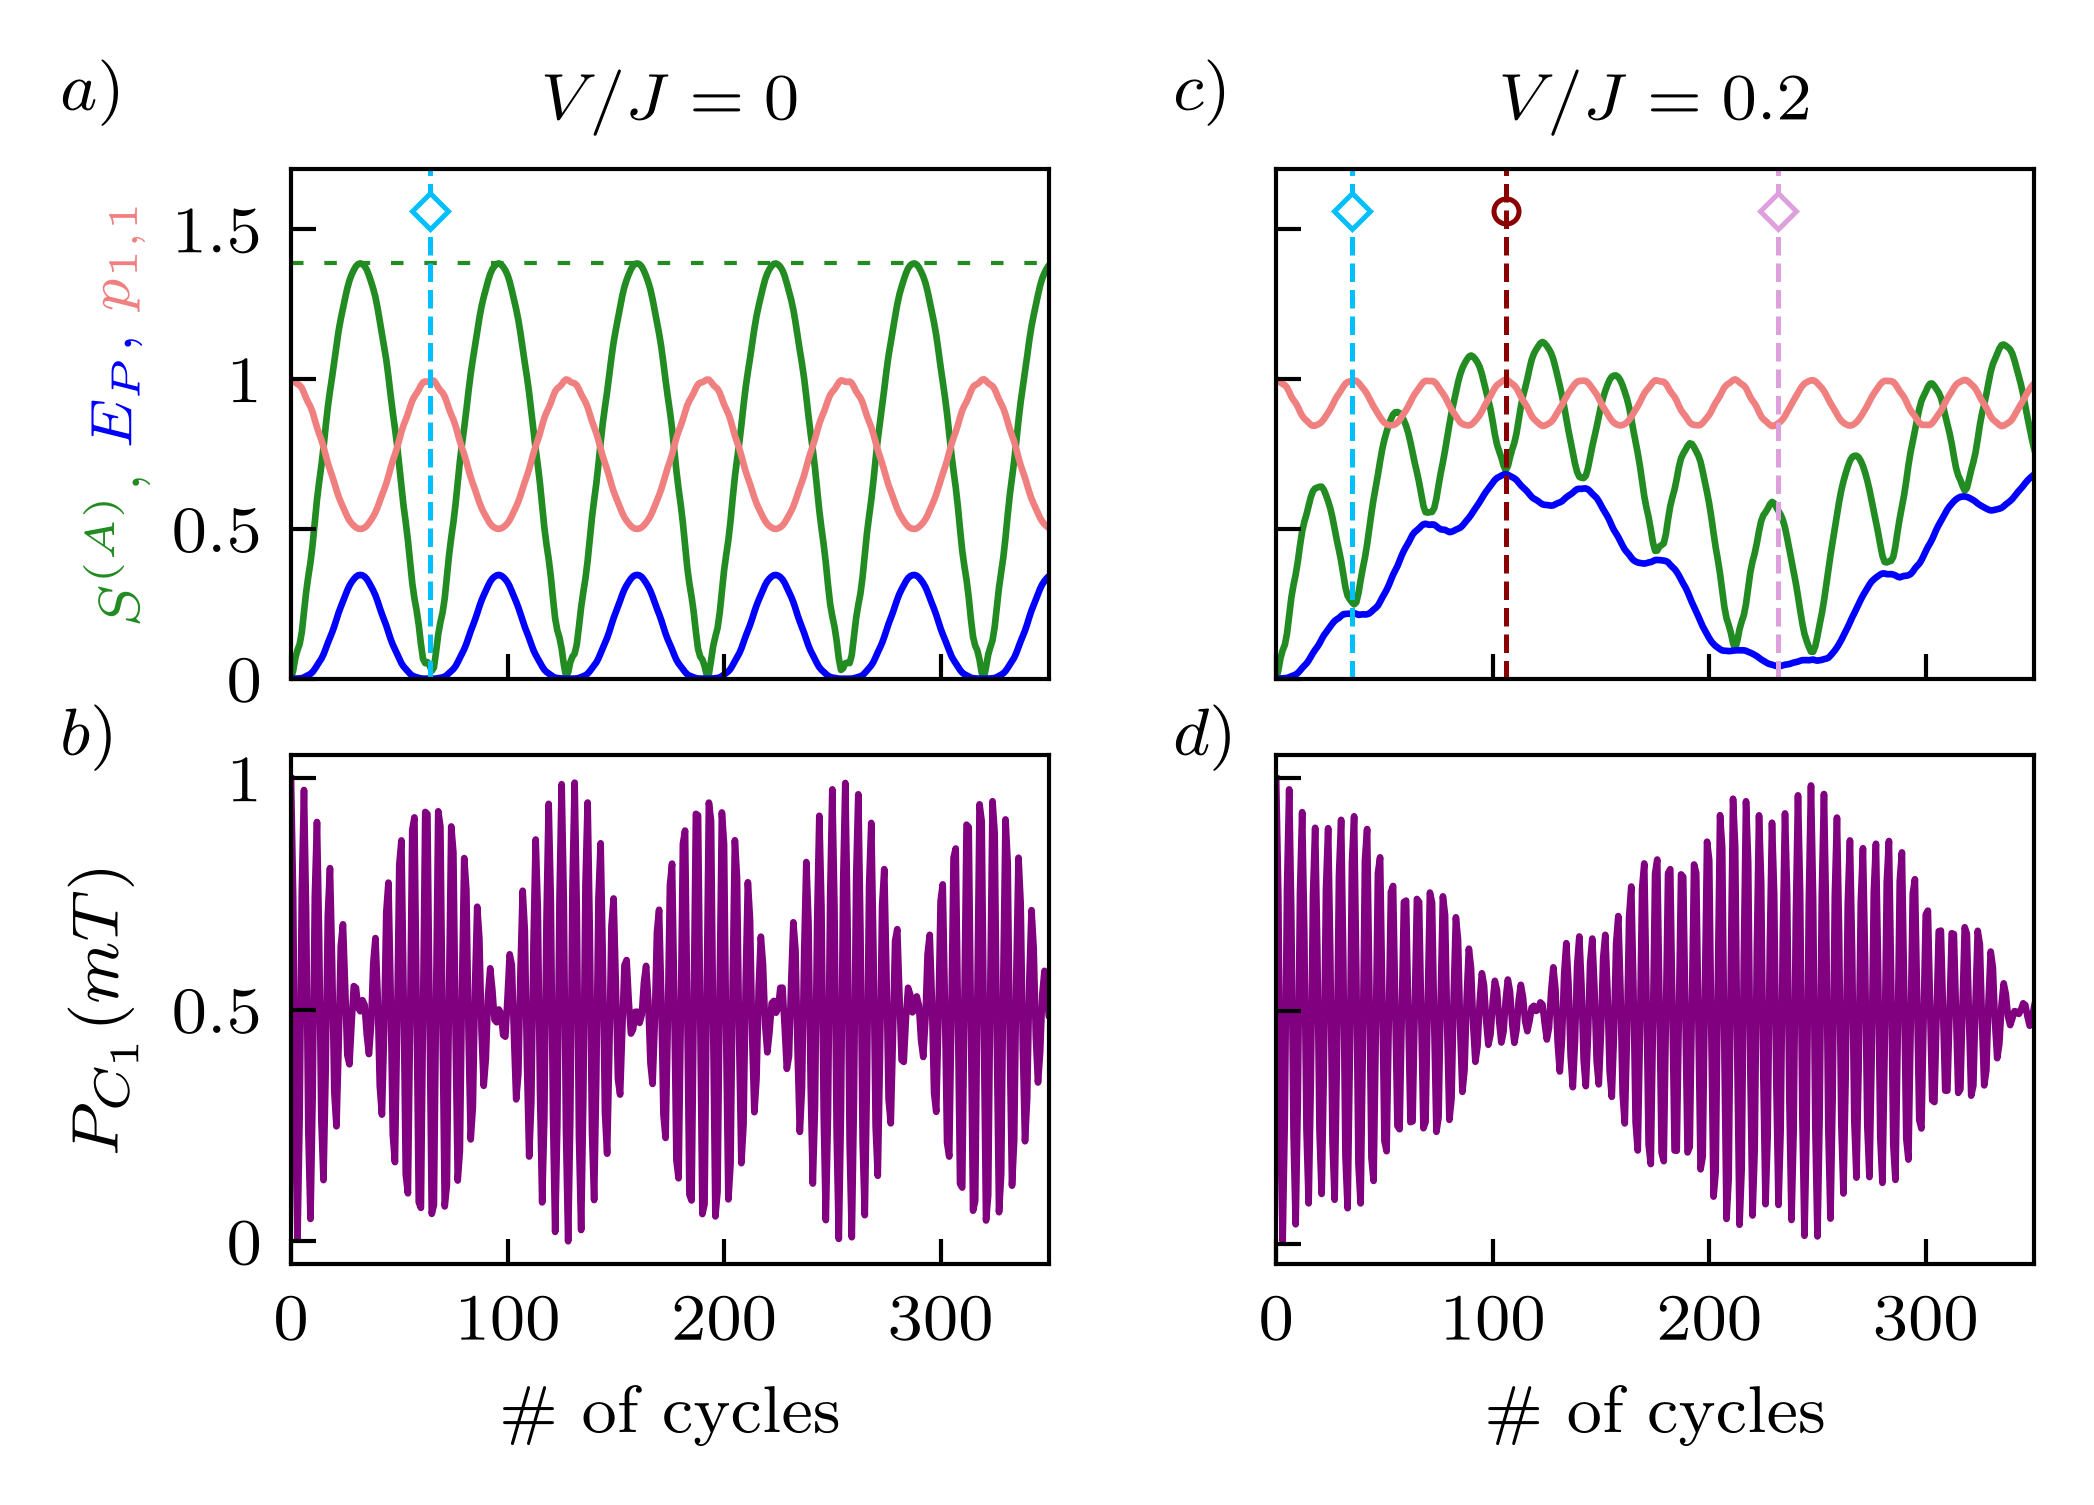

In [11]:
d0, p0 = load_data(DATA / 'Fig07_entanglement_V0.npz')
d2, p2 = load_data(DATA / 'Fig07_entanglement_V0.2.npz')
T = 2 * np.pi / p0['w']
cycles = d0['tvals'] / T


def period_in_cycles(omega):
    return 2 * np.pi / omega / T


def mark(ax, x, color, marker='D', y=1.56, facecolor='white'):
    ax.axvline(x, linestyle='--', linewidth=0.6, color=color)
    ax.plot(x, y, marker=marker, markersize=3., markerfacecolor=facecolor, markeredgecolor=color,
            markeredgewidth=0.6, clip_on=False)


fig, ax = plt.subplots(2, 2, figsize=(3.5, 2.5), sharex=True)

for col, d in enumerate([d0, d2]):
    ax[0, col].plot(cycles, d['S_A'], color='forestgreen', linewidth=0.8, label=r'$S^{(A)}$')
    ax[0, col].plot(cycles, d['E_P'], color='blue', linewidth=0.8, label=r'$E_P(1,1)$')
    ax[0, col].plot(cycles, d['p11'], color='lightcoral', linewidth=0.8, label=r'$p_{1,1}$')
    ax[1, col].plot(cycles, d['densities'][0], linewidth=0.8, color='purple')     # site C_1

# V = 0: maximum entropy 2 log 2 and oscillation period
ax[0, 0].axhline(2 * np.log(2), linewidth=0.5, linestyle='--', dashes=[3, 5], color='forestgreen')
mark(ax[0, 0], period_in_cycles(OMEGA_FT_V0), 'deepskyblue')

# V = 0.2: two periods and the special point
mark(ax[0, 1], period_in_cycles(OMEGA_FT_V02_FAST), 'deepskyblue')
mark(ax[0, 1], period_in_cycles(OMEGA_FT_V02_SLOW), 'plum')
mark(ax[0, 1], M_SPECIAL, 'darkred', marker='o', facecolor='none')

# Formatting
ax[0, 0].text(-0.23, 0.1, r'$S^{(A)}$,', color='forestgreen', transform=ax[0, 0].transAxes, rotation=90, ha='center', va='bottom', fontsize=7)
ax[0, 0].text(-0.23, 0.45, r'$E_P, $', color='blue', transform=ax[0, 0].transAxes, rotation=90, ha='center', va='bottom', fontsize=7)
ax[0, 0].text(-0.23, 0.72, r'$p_{1,1}$', color='lightcoral', transform=ax[0, 0].transAxes, rotation=90, ha='center', va='bottom', fontsize=7)

for col in range(2):
    ax[0, col].set_ylim(0, 1.7)
    ax[0, col].set_yticks([0, 0.5, 1, 1.5])
    ax[1, col].set_yticks([0, 0.5, 1])
    ax[1, col].set_xlim(0, 350)
    ax[1, col].set_xticks([0, 100, 200, 300])
    ax[1, col].set_xticklabels([0, 100, 200, 300], fontsize=8)
    ax[1, col].set_xlabel(r'$\#$ of cycles', fontsize=8)
ax[0, 0].set_yticklabels([0, 0.5, 1, 1.5], fontsize=8)
ax[1, 0].set_yticklabels([0, 0.5, 1], fontsize=8)
ax[0, 1].set_yticklabels([])
ax[1, 1].set_yticklabels([])
ax[1, 0].set_ylabel(r'$P_{C_1}(mT)$', fontsize=8)
ax[0, 0].set_title(r'$V/J = 0$', fontsize=8)
ax[0, 1].set_title(r'$V/J = 0.2$', fontsize=8)

plt.text(0.01, 0.92, r'$a)$', fontsize=8, transform=fig.transFigure)
plt.text(0.01, 0.49, r'$b)$', fontsize=8, transform=fig.transFigure)
plt.text(0.54, 0.92, r'$c)$', fontsize=8, transform=fig.transFigure)
plt.text(0.54, 0.49, r'$d)$', fontsize=8, transform=fig.transFigure)
fig.subplots_adjust(hspace=0.15, wspace=0.3, left=0.12, bottom=0.15, right=0.95)

plt.savefig(FIGURES / 'entanglements.pdf', transparent=True)

m = M_SPECIAL
print(f'At m = {m} (V = 0.2): p11 = {d2["p11"][m]:.4f}, S_A = {d2["S_A"][m]:.4f}, E_P = {d2["E_P"][m]:.4f}, P_C1 = {d2["densities"][0][m]:.3f}')

## Fig. A1 — Edge states of the static chain

FigA01_static_edge_states.npz
    parameters: {'J': 1.0, 'phi': 3.141592653589793, 'Ncells': 6}
    closed_lower_left: shape (19,)
    closed_lower_right: shape (19,)
    closed_upper_left: shape (19,)
    closed_upper_right: shape (19,)
    open_lower: shape (18,)
    open_upper: shape (18,)


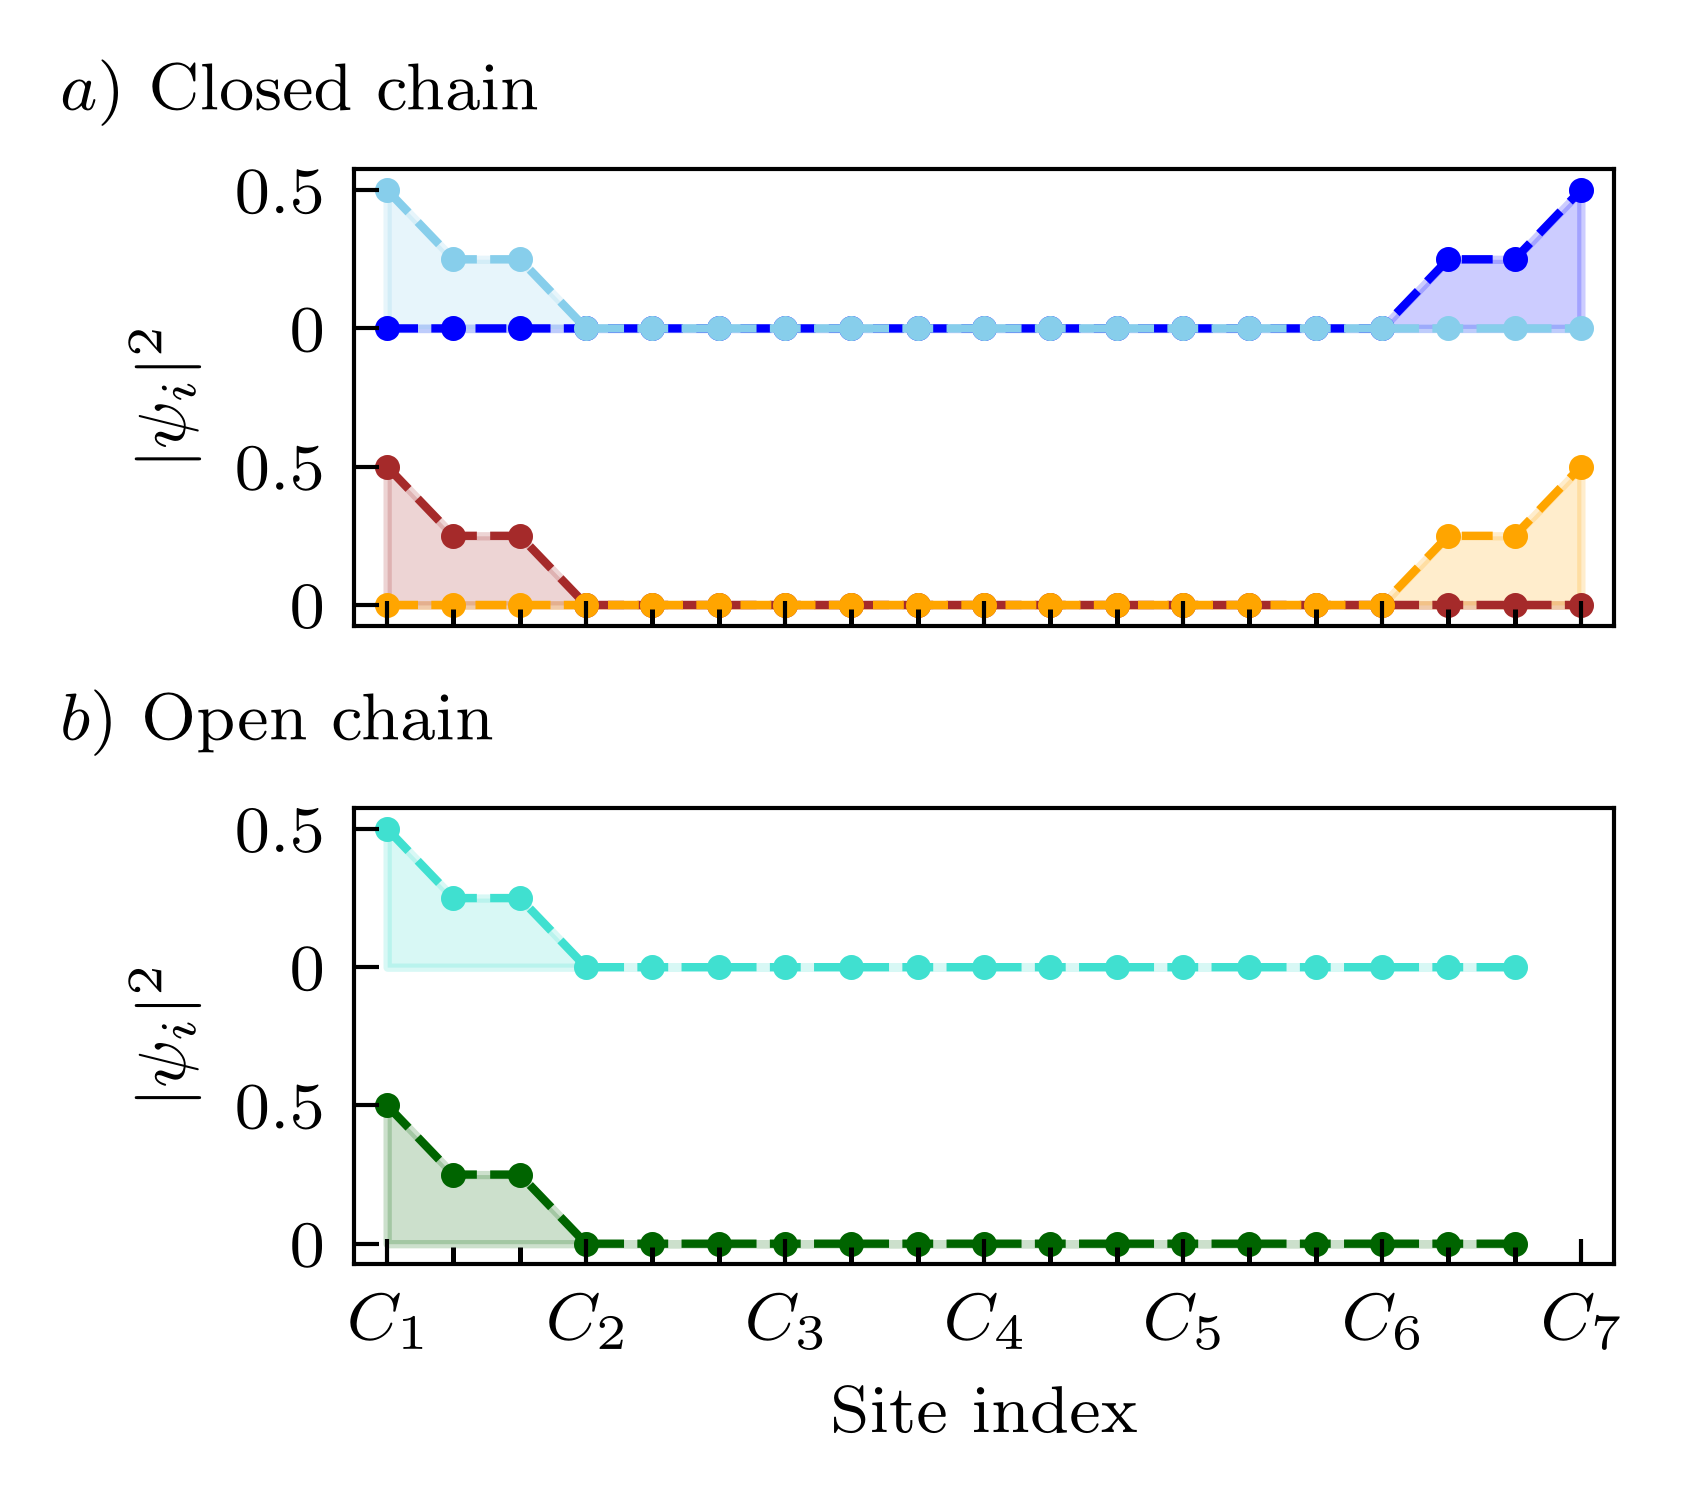

In [12]:
d, p = load_data(DATA / 'FigA01_static_edge_states.npz')
Ncells = p['Ncells']

fig, ax = plt.subplots(2, 1, figsize=(3.5, 2.5))

x_closed = np.arange(3 * Ncells + 1)
closed = [('closed_lower_left', 'brown', 0), ('closed_lower_right', 'orange', 0),
          ('closed_upper_right', 'blue', 1), ('closed_upper_left', 'skyblue', 1)]
for key, color, shift in closed:
    y = shift + np.abs(d[key]) ** 2
    ax[0].plot(x_closed, y, '.', markersize=4, color=color)
    ax[0].plot(x_closed, y, linestyle='--', color=color, linewidth=1)
    ax[0].fill_between(x_closed, shift, y, color=color, alpha=0.2)

x_open = np.arange(3 * Ncells)
for key, color, shift in [('open_lower', 'darkgreen', 0), ('open_upper', 'turquoise', 1)]:
    y = shift + np.abs(d[key]) ** 2
    ax[1].plot(x_open, y, '.', markersize=4, color=color)
    ax[1].plot(x_open, y, linestyle='--', color=color, linewidth=1)
    ax[1].fill_between(x_open, shift, y, color=color, alpha=0.2)

for axis in ax:
    axis.set_ylabel(r'$\vert \psi_i \vert^2$', fontsize=8)
    axis.set_xlim(-0.5, 3 * Ncells + 0.5)
    axis.set_xticks(np.arange(0, 3 * Ncells + 1, 3))
    axis.set_xticks(np.setdiff1d(np.arange(3 * Ncells), np.arange(0, 3 * Ncells + 1, 3)), minor=True)
    axis.set_yticks([0, 0.5, 1, 1.5])
    axis.set_yticklabels([0, 0.5, 0, 0.5], fontsize=8)
ax[0].set_xticklabels([])
ax[1].set_xticklabels([f'$C_{n + 1}$' for n in range(Ncells + 1)], fontsize=8)
ax[1].set_xlabel(r'Site index', fontsize=8)

plt.text(0.06, 0.92, r'$a)$ Closed chain', fontsize=8, transform=fig.transFigure)
plt.text(0.06, 0.5, r'$b)$ Open chain', fontsize=8, transform=fig.transFigure)
fig.subplots_adjust(right=0.8, left=0.2, hspace=0.4, bottom=0.15)

plt.savefig(FIGURES / 'edge_states_static.pdf', transparent=True)

## Fig. A2 — Zak phases vs $\tilde A$
$|\mathcal{Z}_j|/\pi$ of the three Floquet bands ($j = 1, 2, 3$ by increasing quasienergy) for antisymmetric driving, $\omega = 8$:
exact stroboscopic Floquet modes (markers, every 4th point) and second-order $\hat H_{\rm eff}(k)$ (lines; missing at the pole $\tilde A = 1$).
Bands $j = 1$ and $j = 3$ coincide. Data from `FigA02_A08_zak_phase` (`Data/FigA02_A08_zak_phase.npz`). One column wide.

FigA02_A08_zak_phase.npz
    parameters: {'J': 1.0, 'phi': 3.141592653589793, 'zeta': -1, 'w': 8, 'nk': 400, 'A_t0': 9.6}
    Avals: shape (101,)
    Z_exact: shape (101, 3)
    Z_effective: shape (101, 3)
    gap_min: shape (101,)
    t0_over_T: shape (41,)
    Z_t0: shape (41, 3)


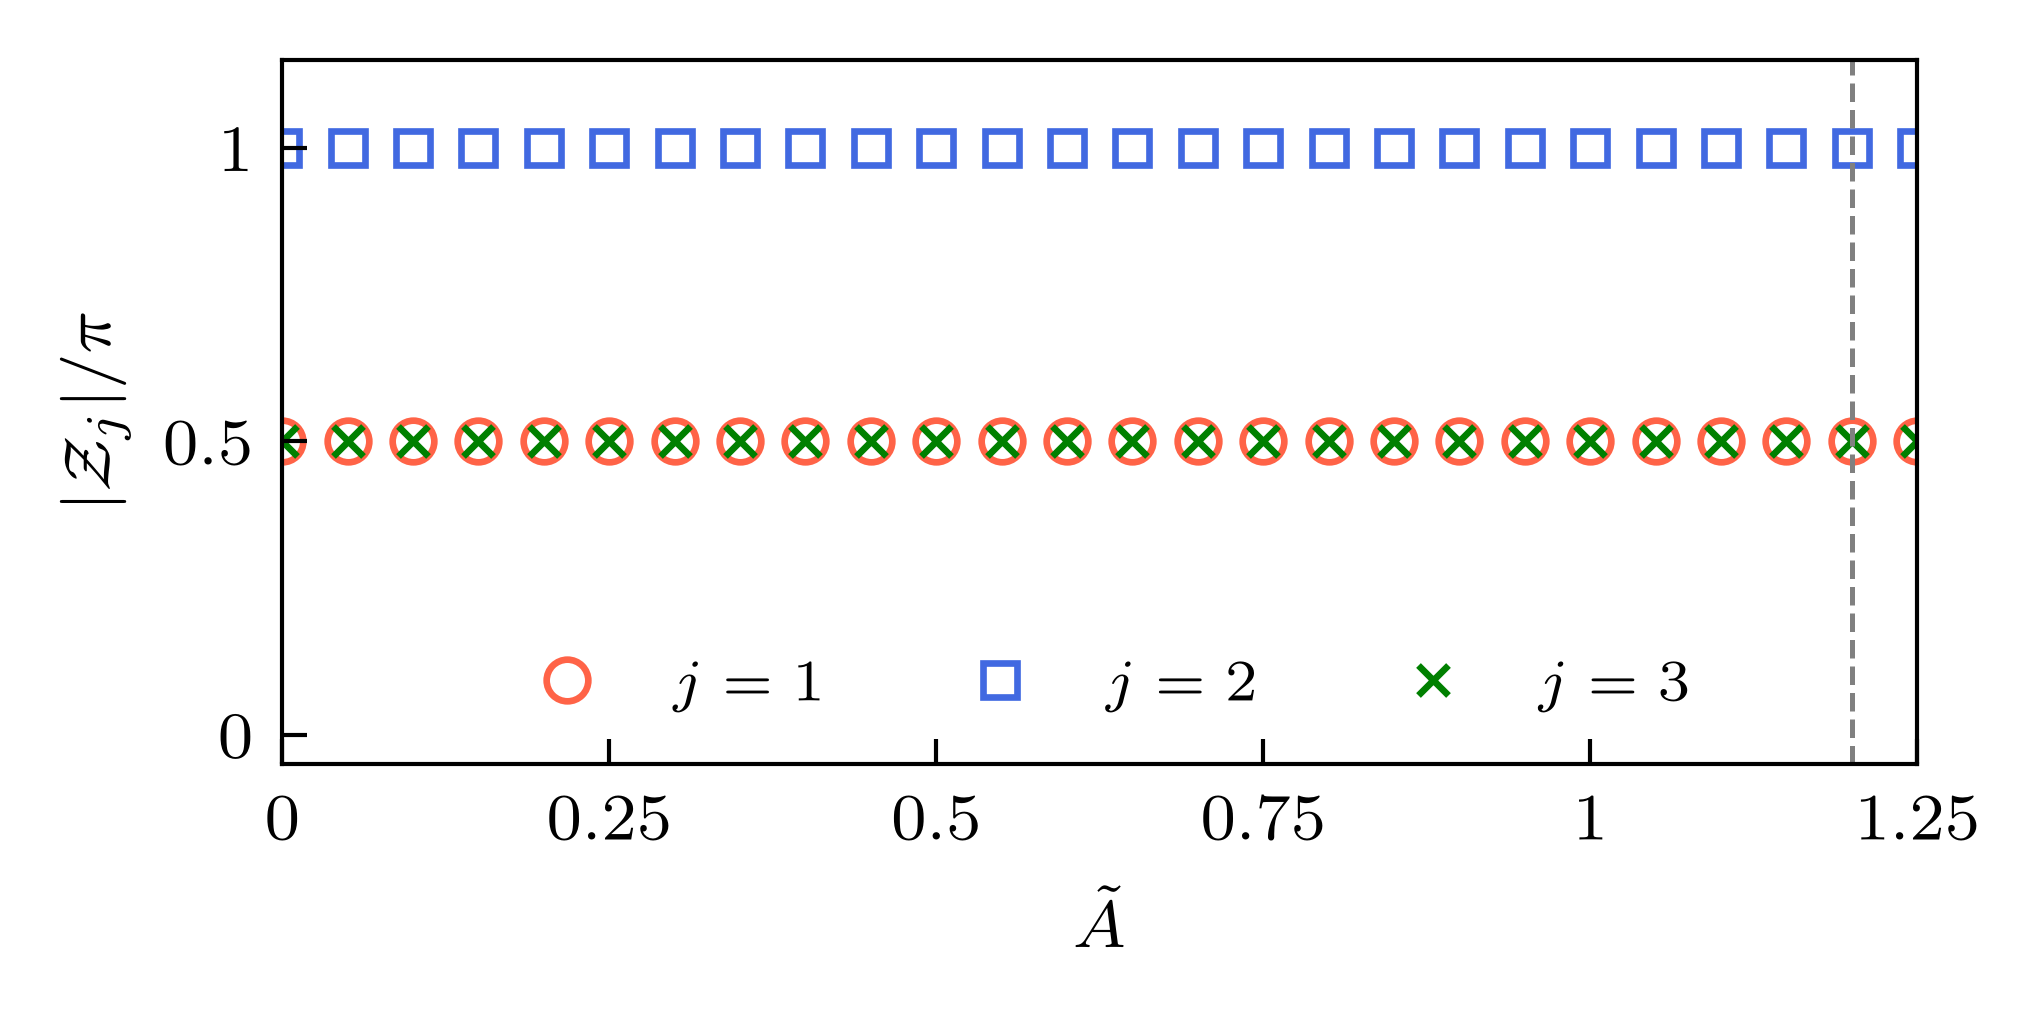

In [13]:
d, p = load_data(DATA / 'FigA02_A08_zak_phase.npz')
At = d['Avals'] / p['w']
Z_exact, Z_effective = np.abs(d['Z_exact']) / np.pi, np.abs(d['Z_effective']) / np.pi

colors = ['tomato', 'royalblue', 'green']
markers = ['o', 's', 'x']                     # j = 1 and j = 3 coincide: different markers keep both visible
sizes = [5, 4, 3.5]

fig, ax = plt.subplots(figsize=(3.5, 1.8))

for j in range(3):
    #ax.plot(At, Z_effective[:, j], '-', lw=1, color=colors[j], alpha=0.5)
    ax.plot(At[::4], Z_exact[::4, j], markers[j], ms=sizes[j], mfc='none', mew=0.8, color=colors[j],
            label=rf'$j = {j + 1}$')

ax.axvline(p['A_t0'] / p['w'], ls='--', lw=0.6, color='gray')          # Atilde = 1.2 of the manuscript
ax.set_xlim(0, At.max())
ax.set_ylim(-0.05, 1.15)
ax.set_yticks([0, 0.5, 1])
ax.set_yticklabels([0, 0.5, 1], fontsize=8)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1, 1.25])
ax.set_xticklabels([0, 0.25, 0.5, 0.75, 1, 1.25], fontsize=8)
ax.set_xlabel(r'$\tilde{A}$', fontsize=8)
ax.set_ylabel(r'$|\mathcal{Z}_j|/\pi$', fontsize=8)
ax.legend(fontsize=7, ncol=3, loc='lower center', frameon=False)

plt.tight_layout()
plt.savefig(FIGURES / 'zak_phase.pdf', transparent=True)

## Fig. A3 — Convergence of $\Gamma$
$\Gamma$ is the full sum of Eq. (gamma_Def) (positive and negative harmonics; see `FigA03_convergence_of_Gamma`), $\Gamma(1.2) = -49.01$.
The axis limits are set for these values.

FigA03_convergence_Gamma.npz
    parameters: {'n_max': 39, 'm_max': 39}
    n_max_vals: shape (19,)
    m_max_vals: shape (4,)
    Atilde_conv: shape (2,)
    Gamma_vs_cutoff: shape (2, 4, 19)
    Atildevals: shape (201,)
    Gamma: shape (201,)


Atilde = 1.2: Gamma at n_max = 18 for m_max = [np.int64(1), np.int64(3), np.int64(5), np.int64(7)]: [-48.9318 -49.0041 -49.0067 -49.0071]
Atilde = 2.3: Gamma at n_max = 18 for m_max = [np.int64(1), np.int64(3), np.int64(5), np.int64(7)]: [1.9338 2.0494 2.0518 2.0521]


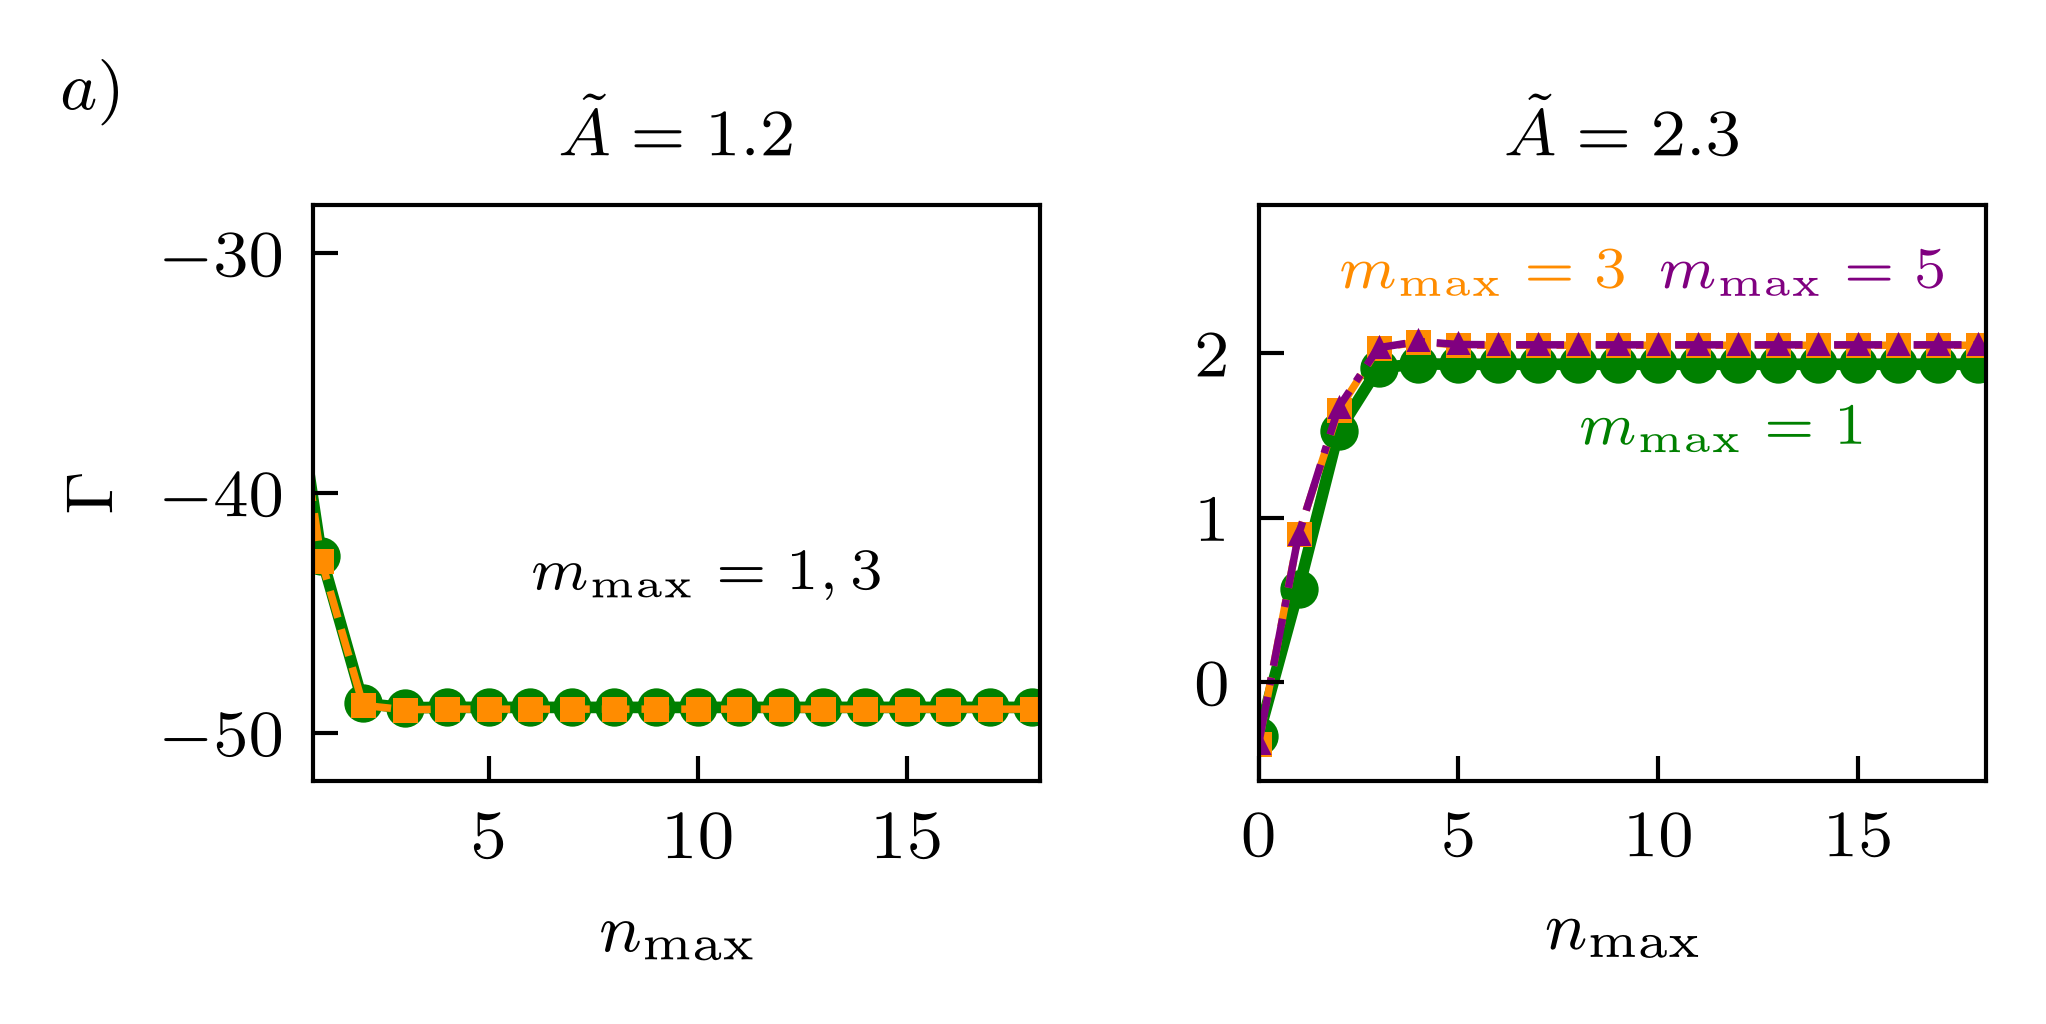

In [14]:
d, p = load_data(DATA / 'FigA03_convergence_Gamma.npz')
n_max_vals, m_max_vals, G = d['n_max_vals'], list(d['m_max_vals']), d['Gamma_vs_cutoff']

colors = {1: 'green', 3: 'darkorange', 5: 'purple'}
linestyles = {1: '-', 3: '--', 5: '-.'}
# One curve per m_max with its own line style, open marker and width, so that overlapping curves remain visible
markers = {1: 'o', 3: 's', 5: '^'}
markersizes = {1: 4., 3: 2.5, 5: 2.}
linewidths = {1: 1.4, 3: 0.9, 5: 0.9}

fig, ax = plt.subplots(1, 2, figsize=(3.5, 1.75))

for i, (At, m_list) in enumerate([(1.2, [1, 3]), (2.3, [1, 3, 5])]):
    for m_max in m_list:
        y = G[i, m_max_vals.index(m_max)]
        ax[i].plot(n_max_vals, y, ls=linestyles[m_max], linewidth=linewidths[m_max], color=colors[m_max],
                   marker=markers[m_max], markersize=markersizes[m_max], markerfacecolor=colors[m_max], markeredgewidth=0.6)
    ax[i].set_title(rf'$\tilde{{A}} = {At}$', fontsize=8)
    ax[i].set_xlabel(r'$n_{\mathrm{max}}$', fontsize=8)

ax[0].set_ylim([-52, -28])
ax[0].set_yticks([-50, -40, -30])
ax[0].set_yticklabels(['$-50$', '$-40$', '$-30$'], fontsize=8)
ax[0].set_xlim(0.8, 18.2)
ax[0].set_ylabel(r'$\Gamma$', fontsize=8)
ax[0].text(6, -44, r'$m_{\mathrm{max}} = 1, 3$', fontsize=7)

ax[1].set_ylim([-0.6, 2.9])
ax[1].set_xlim([0, 18.2])
ax[1].set_xticks([0, 5, 10, 15])
ax[1].set_xticklabels([0, 5, 10, 15], fontsize=8)
ax[1].set_yticks([0, 1, 2])
ax[1].set_yticklabels(['$0$', '$1$', '$2$'], fontsize=8)
ax[1].text(8, 1.45, r'$m_{\mathrm{max}} = 1$', color='green', fontsize=7)
ax[1].text(2, 2.4, r'$m_{\mathrm{max}} = 3$', color='darkorange', fontsize=7)
ax[1].text(10, 2.4, r'$m_{\mathrm{max}} = 5$', color='purple', fontsize=7)

plt.tight_layout()
fig.subplots_adjust(wspace=0.3)
plt.text(0.04, 0.9, r'$a)$', fontsize=8, transform=fig.transFigure)

plt.savefig(FIGURES / 'convergence_A.pdf', transparent=True)

for i, At in enumerate([1.2, 2.3]):
    print(f'Atilde = {At}: Gamma at n_max = 18 for m_max = {m_max_vals}:', np.round(G[i, :, -1], 4))

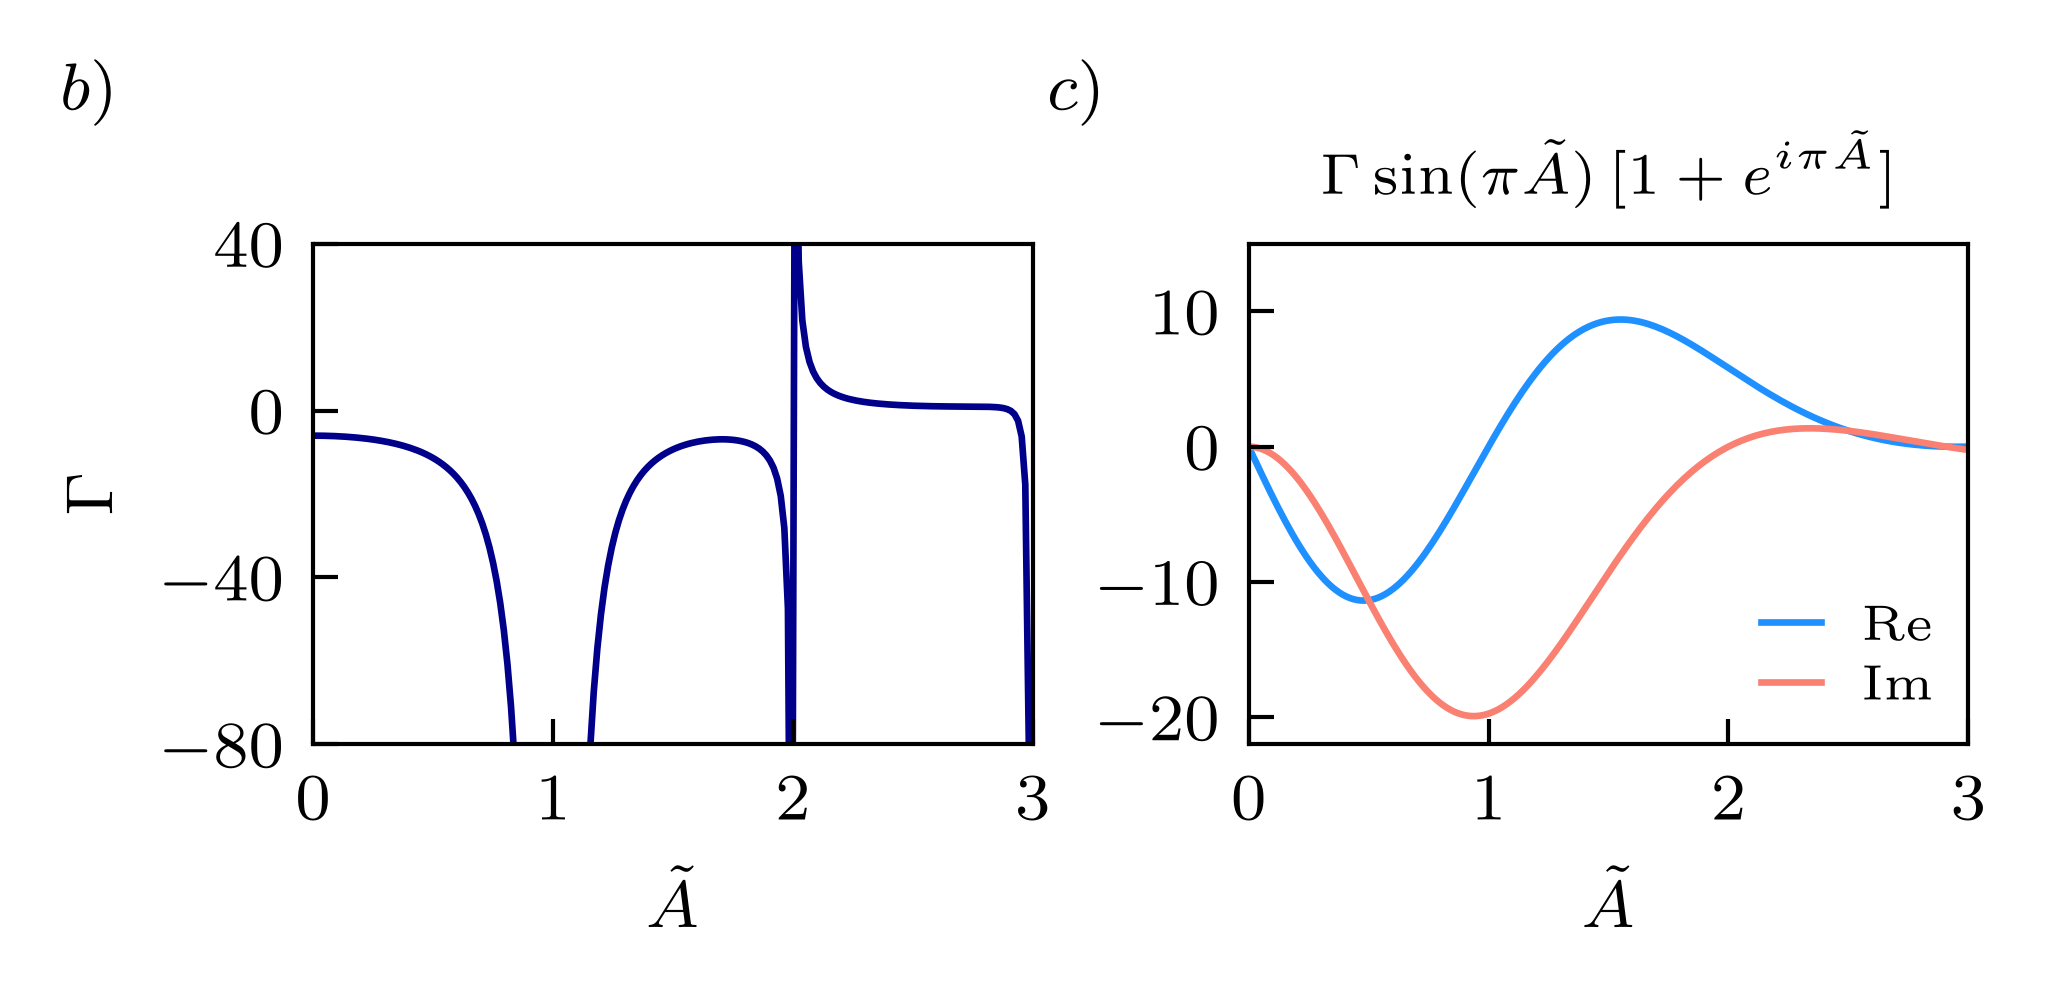

In [15]:
At, Gamma = d['Atildevals'], d['Gamma']

fig, ax = plt.subplots(1, 2, figsize=(3.5, 1.65))

ax[0].plot(At, Gamma, linewidth=0.8, color='darkblue')
ax[0].set_xlim([0, 3])
ax[0].set_ylim([-80, 40])
ax[0].set_xticks([0, 1, 2, 3])
ax[0].set_xticklabels([0, 1, 2, 3], fontsize=8)
ax[0].set_yticks([-80, -40, 0, 40])
ax[0].set_yticklabels(['$-80$', '$-40$', '$0$', '$40$'], fontsize=8)
ax[0].set_ylabel(r'$\Gamma$', fontsize=8)
ax[0].set_xlabel(r'$\tilde{A}$', fontsize=8)

# Real and imaginary part of Gamma sin(pi At) [1 + exp(i pi At)]
ax[1].plot(At, np.sin(np.pi * At) * (1 + np.cos(np.pi * At)) * Gamma, linewidth=0.8, color='dodgerblue', label=r'$\mathrm{Re}$')
ax[1].plot(At, np.sin(np.pi * At) * np.sin(np.pi * At) * Gamma, linewidth=0.8, color='salmon', label=r'$\mathrm{Im}$')
ax[1].legend(loc='lower right', fontsize=6, frameon=False, handlelength=1.2, borderaxespad=0.3, labelspacing=0.3)
ax[1].set_title(r'$\Gamma \sin(\pi \tilde{A})\,[1 + e^{i \pi \tilde{A}}]$', fontsize=7)
ax[1].set_xlim([0, 3])
ax[1].set_ylim(-22, 15)
ax[1].set_xticks([0, 1, 2, 3])
ax[1].set_xticklabels([0, 1, 2, 3], fontsize=8)
ax[1].set_yticks([-20, -10, 0, 10])
ax[1].set_yticklabels(['$-20$', '$-10$', '$0$', '$10$'], fontsize=8)
ax[1].set_xlabel(r'$\tilde{A}$', fontsize=8)

plt.tight_layout()
fig.subplots_adjust(wspace=0.3)
plt.text(0.04, 0.93, r'$b)$', fontsize=8, transform=fig.transFigure)
plt.text(0.51, 0.93, r'$c)$', fontsize=8, transform=fig.transFigure)

plt.savefig(FIGURES / 'convergence_Gamma.pdf', transparent=True)

## Fig. A4 — Dynamics starting from the central $U$ site

FigA04_dynamics_U_site.npz
    parameters: {'J': 1.0, 'phi': 3.141592653589793, 'Ncells': 100, 'w': 8, 'A': 9.6, 'zeta': -1, 'ncycles': 400, 'initial_site': 151}
    tvals: shape (401,)
    populations: shape (401, 301)


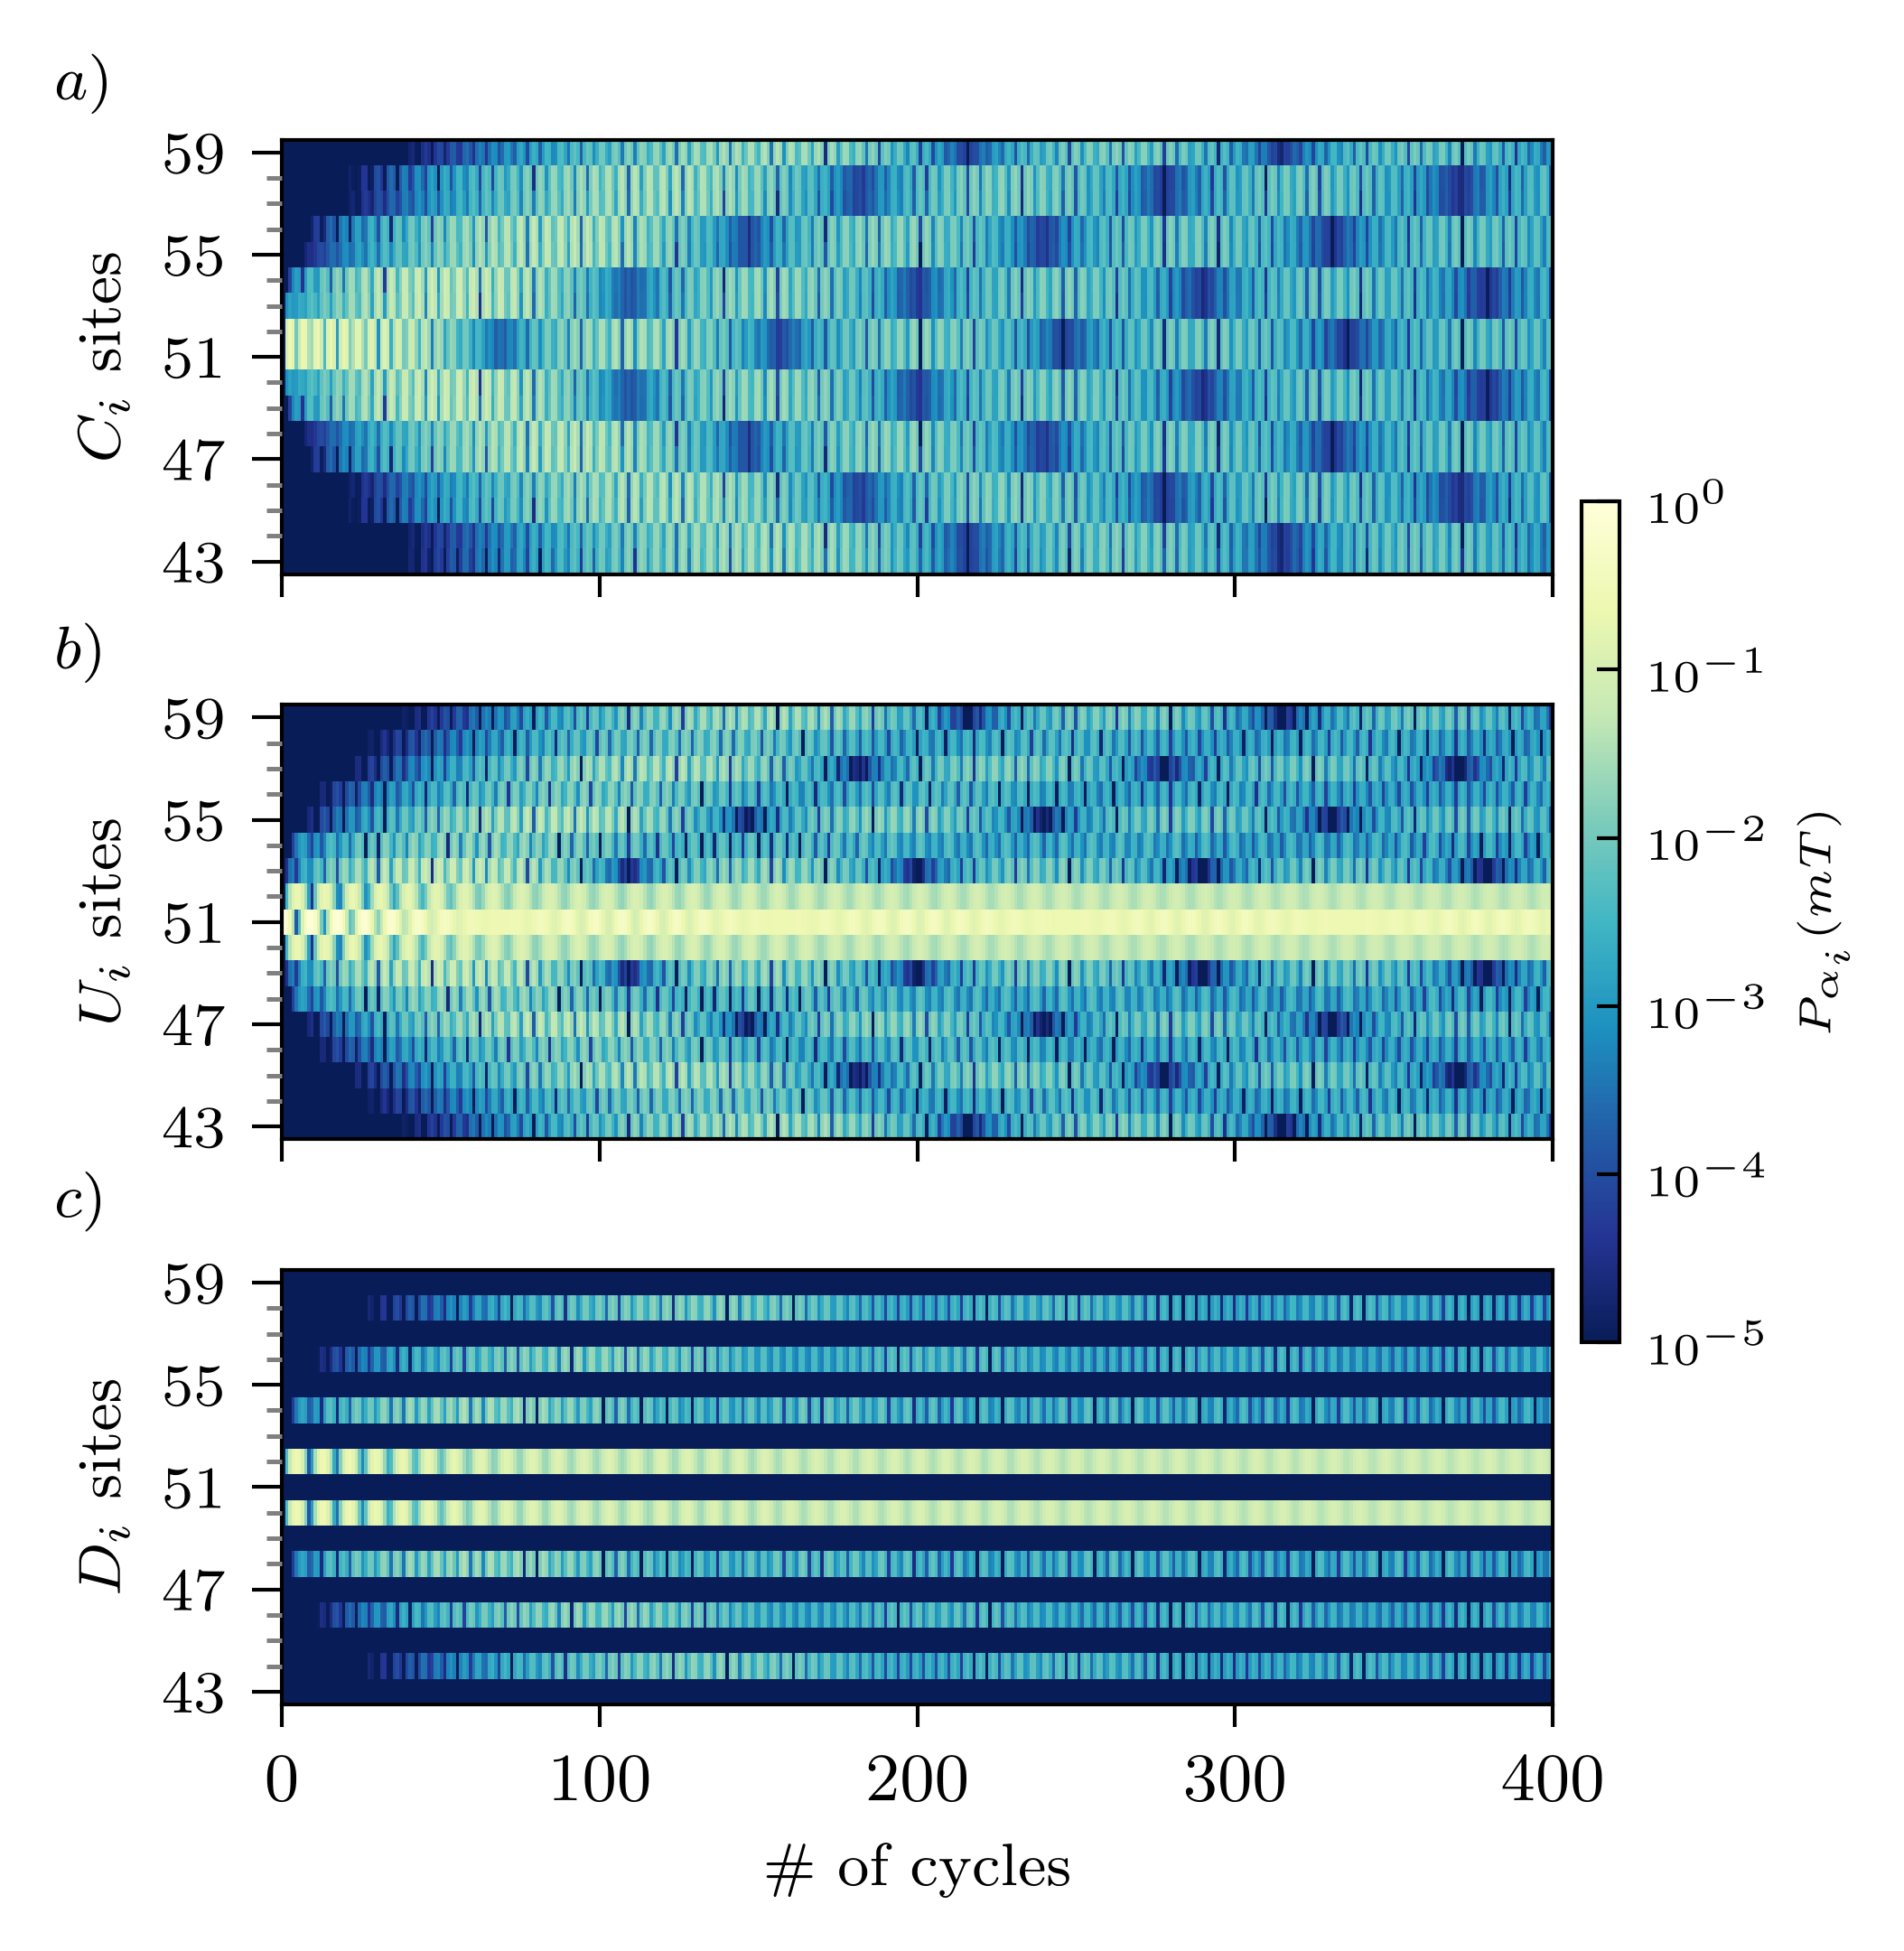

In [16]:
d, p = load_data(DATA / 'FigA04_dynamics_U_site.npz')
populations, tvals, Ncells = d['populations'], d['tvals'], p['Ncells']
T = 2 * np.pi / p['w']

fig, axs, pcm = plot_long_chain_dynamics(populations, tvals, T, Ncells, sublattices=[0, 1, 2],
                                         ylabels=[r'$C_i$ sites', r'$U_i$ sites', r'$D_i$ sites'], height_ratios=[1, 1, 1])
fig.subplots_adjust(right=0.8, left=0.13, hspace=0.3)

cbar = add_colorbar(fig, pcm, axs[1], axs[1], shrink=1)
cbar.ax.set_position([axs[1].get_position().x1 + 0.015, axs[1].get_position().y0 - 0.1, 0.02, axs[1].get_position().height + 0.2])

cycles_list = np.linspace(0, 400, 5)
axs[2].set_xticklabels([int(i) for i in cycles_list], fontsize=9)
axs[2].set_xlabel(r'$\#$ of cycles', fontsize=8)

plt.text(0.01, 0.9, r'$a)$', fontsize=8, transform=fig.transFigure)
plt.text(0.01, 0.62, r'$b)$', fontsize=8, transform=fig.transFigure)
plt.text(0.01, 0.35, r'$c)$', fontsize=8, transform=fig.transFigure)

plt.savefig(FIGURES / 'dynamics_starting_ulattice.pdf', transparent=True)

## Fig. A5 — Dynamics from the central $C$ site for several $\omega$
Same chain and initial state as Fig. 4 ($N = 100$, $\ket{C_{51}}$), at fixed $\tilde A = 1.2$ for $\omega = 8, 6, 4$; only the $C$ sublattice is shown.
Data from `FigA05_dynamics_vs_frequency` (`Data/FigA05_dynamics_C_site_vs_w.npz`). One column wide, three rows.

FigA05_dynamics_C_site_vs_w.npz
    parameters: {'J': 1.0, 'phi': 3.141592653589793, 'Ncells': 100, 'w_values': [8.0, 6.0, 4.0, 3.0, 2.0], 'A_over_w': 1.2, 'zeta': -1, 'ncycles': 400, 'initial_site': 150}
    tvals: shape (5, 401)
    populations: shape (5, 401, 301)


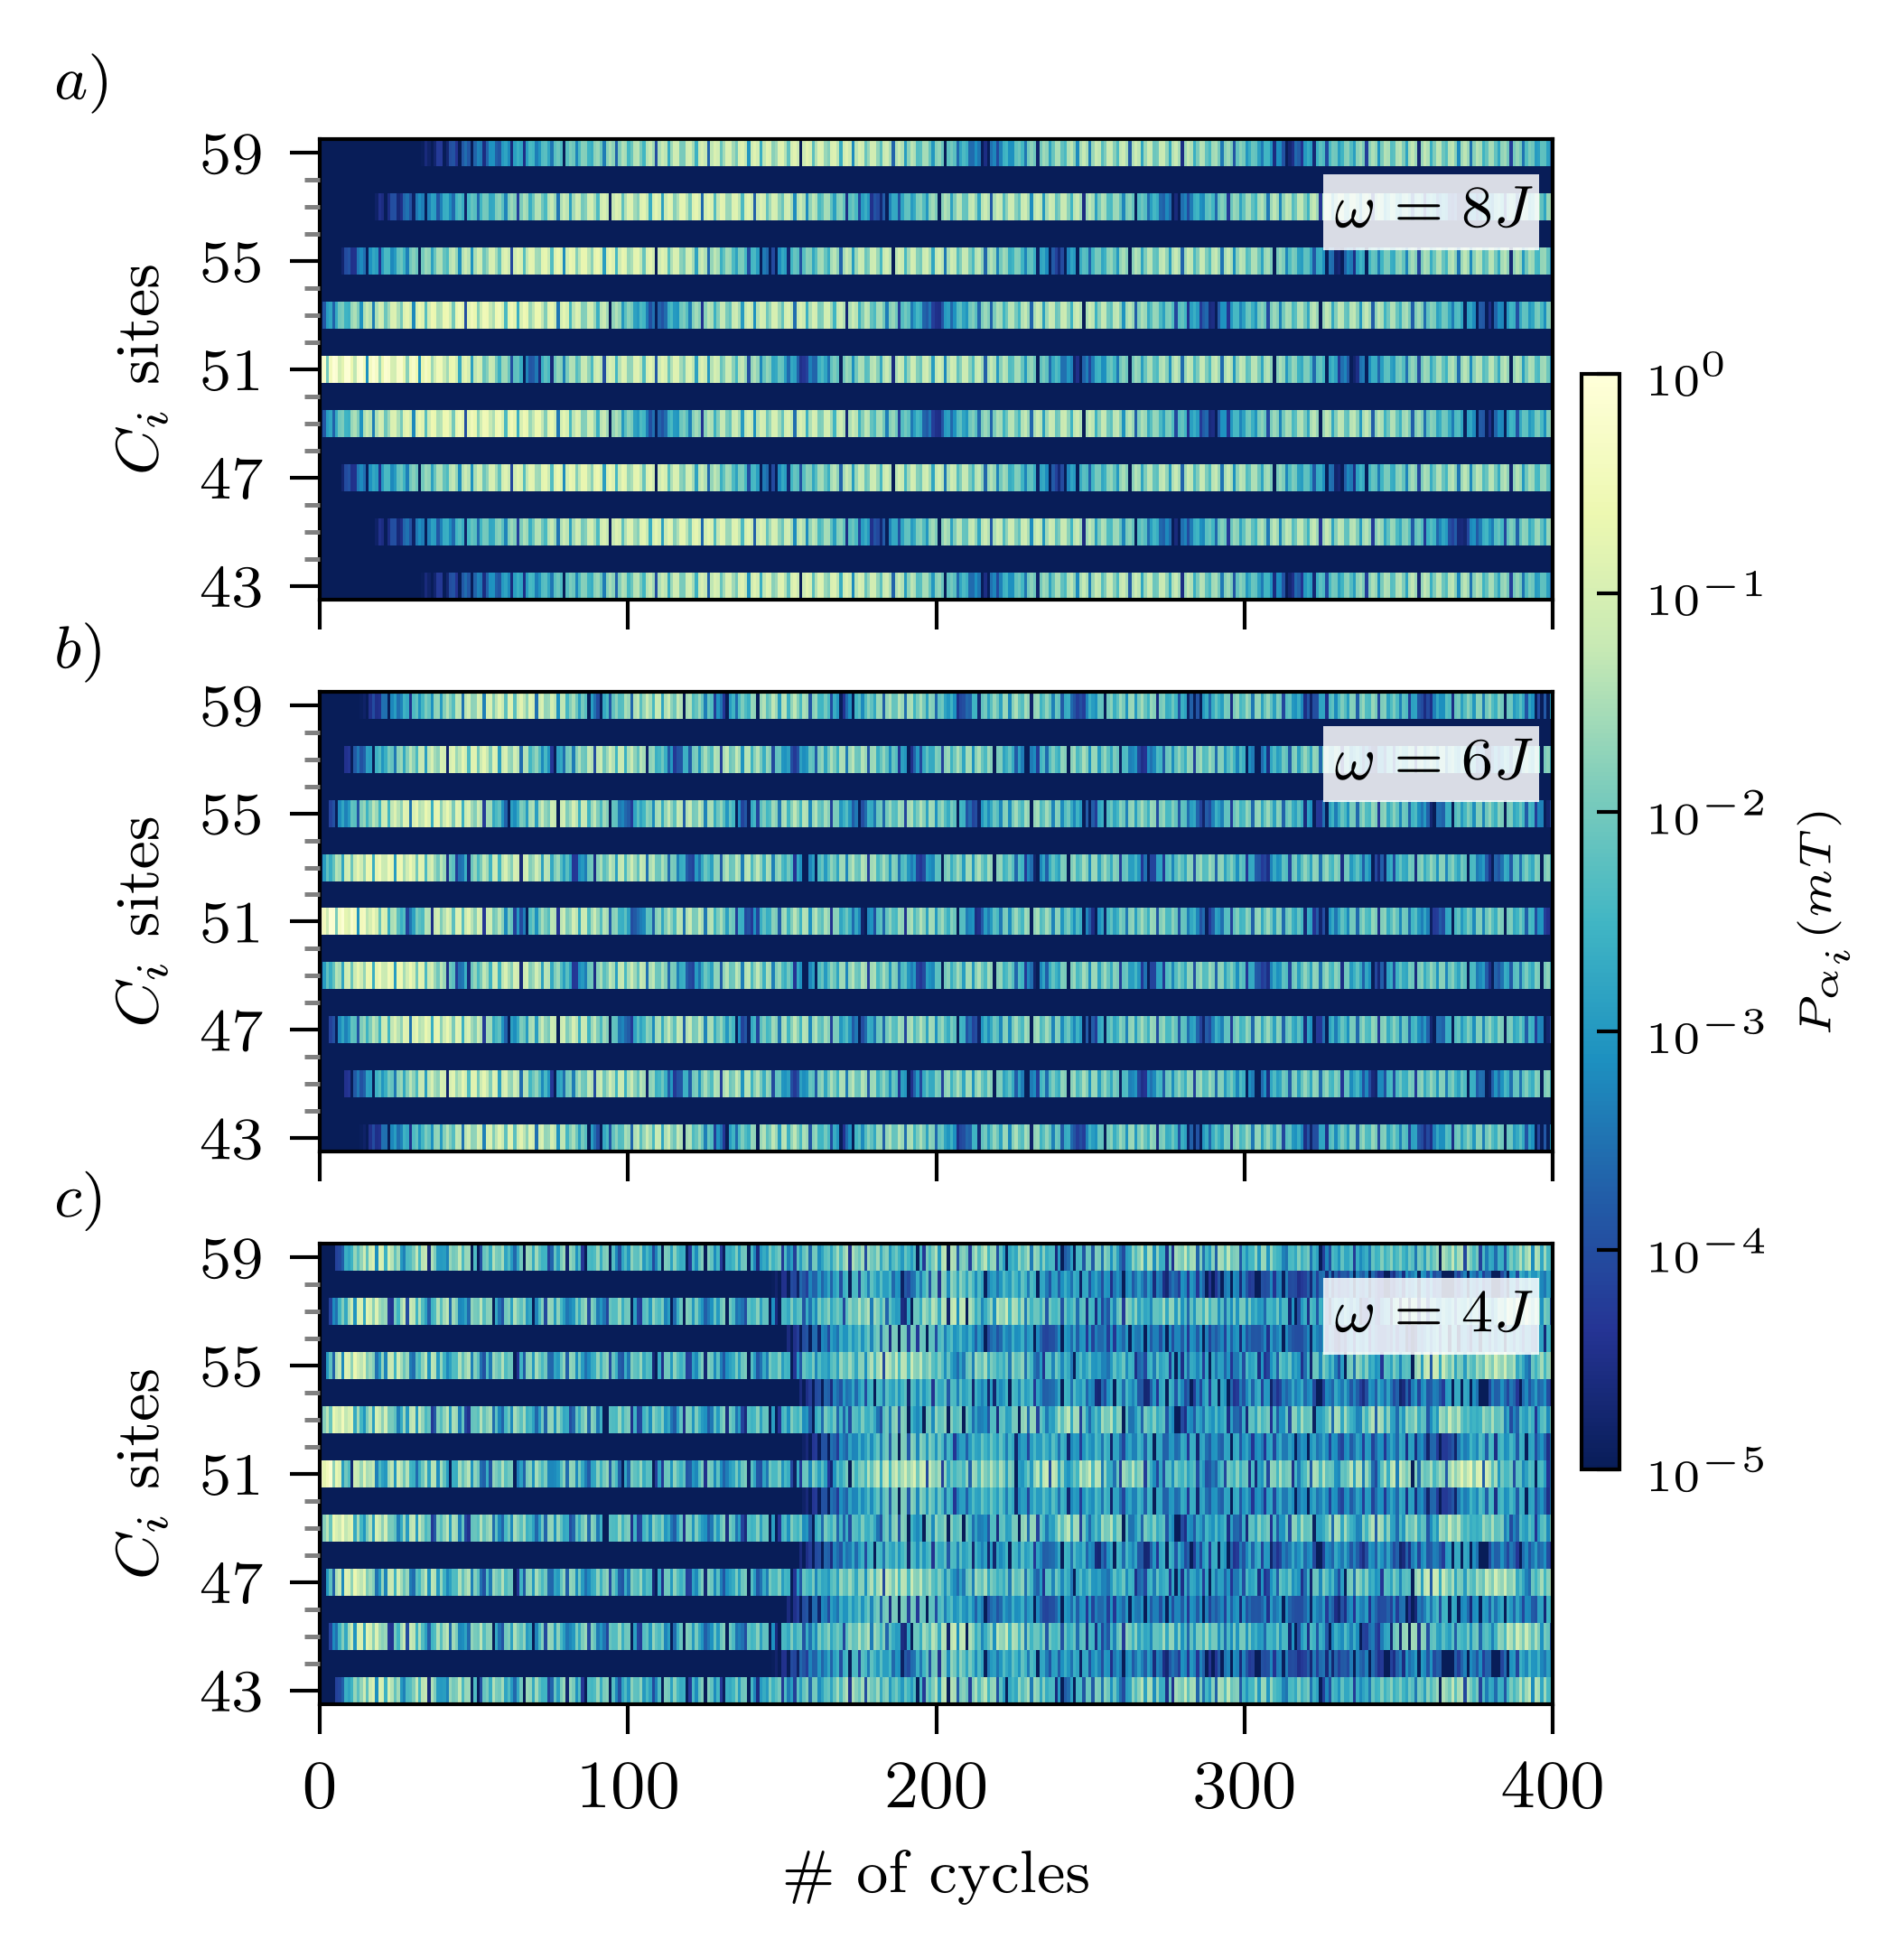

In [17]:
d, p = load_data(DATA / 'FigA05_dynamics_C_site_vs_w.npz')
populations, tvals, Ncells = d['populations'], d['tvals'], p['Ncells']
w_values = p['w_values'][:3]                                     # w = 8, 6, 4

fig, axs = plt.subplots(3, 1, figsize=(3.5, 3.75), sharex=True)
cycles_list = np.linspace(0, 400, 5)
cells = np.arange(43, 60)                                        # cells counted from 1, as in Fig. 4
ticks = 3 * (cells - 1)                                          # site index of C_n

for ax, P, t, w in zip(axs, populations, tvals, w_values):
    T = 2 * np.pi / w
    pcm = ax.imshow(np.log10(P[:, 0::3].T + 1e-12),
                    extent=[t.min() / T, t.max() / T, -1.5, 3 * Ncells + 1.5],   # row k centered on site 3k
                    aspect='auto', origin='lower', vmin=-5, vmax=0, interpolation='none', cmap='YlGnBu_r')
    ax.set_ylim(ticks[0] - 1.5, ticks[-1] + 1.5)
    ax.set_yticks(ticks[::4])
    ax.set_yticklabels([f'${c}$' for c in cells[::4]], fontsize=8)
    ax.set_yticks(np.setdiff1d(ticks, ticks[::4]), minor=True)
    ax.tick_params(axis='both', which='major', length=4, direction='out')
    ax.tick_params(axis='y', which='minor', length=2, direction='out', color='gray')
    ax.set_ylabel(r'$C_i$ sites', fontsize=8)
    ax.text(0.98, 0.9, rf'$\omega = {w:.0f}J$', transform=ax.transAxes, ha='right', va='top', fontsize=8,
            bbox=dict(facecolor='white', edgecolor='none', pad=1.5, alpha=0.85))

axs[2].set_xticks(cycles_list)
axs[2].set_xticklabels([int(i) for i in cycles_list], fontsize=9)
axs[2].set_xlabel(r'$\#$ of cycles', fontsize=8)

fig.subplots_adjust(right=0.8, left=0.15, hspace=0.2)
add_colorbar(fig, pcm, axs[0], axs[2], shrink=0.7)

plt.text(0.01, 0.9, r'$a)$', fontsize=8, transform=fig.transFigure)
plt.text(0.01, 0.62, r'$b)$', fontsize=8, transform=fig.transFigure)
plt.text(0.01, 0.35, r'$c)$', fontsize=8, transform=fig.transFigure)

plt.savefig(FIGURES / 'dynamics_csite_vs_w.pdf', transparent=True)

## Fig. A6 — Hopping renormalization ($\omega = 8$)
Panel a) shows $40\,|J_2|$ (with the full $\Gamma$, $|J_2|$ is about 2.6 times larger than with the original code).

FigA06_hoppings.npz
    parameters: {'J': 1.0, 'w': 8, 'n_max': 99, 'm_max': 99}
    Atilde_vals: shape (400,)
    J1: shape (400,)
    J2: shape (400,)


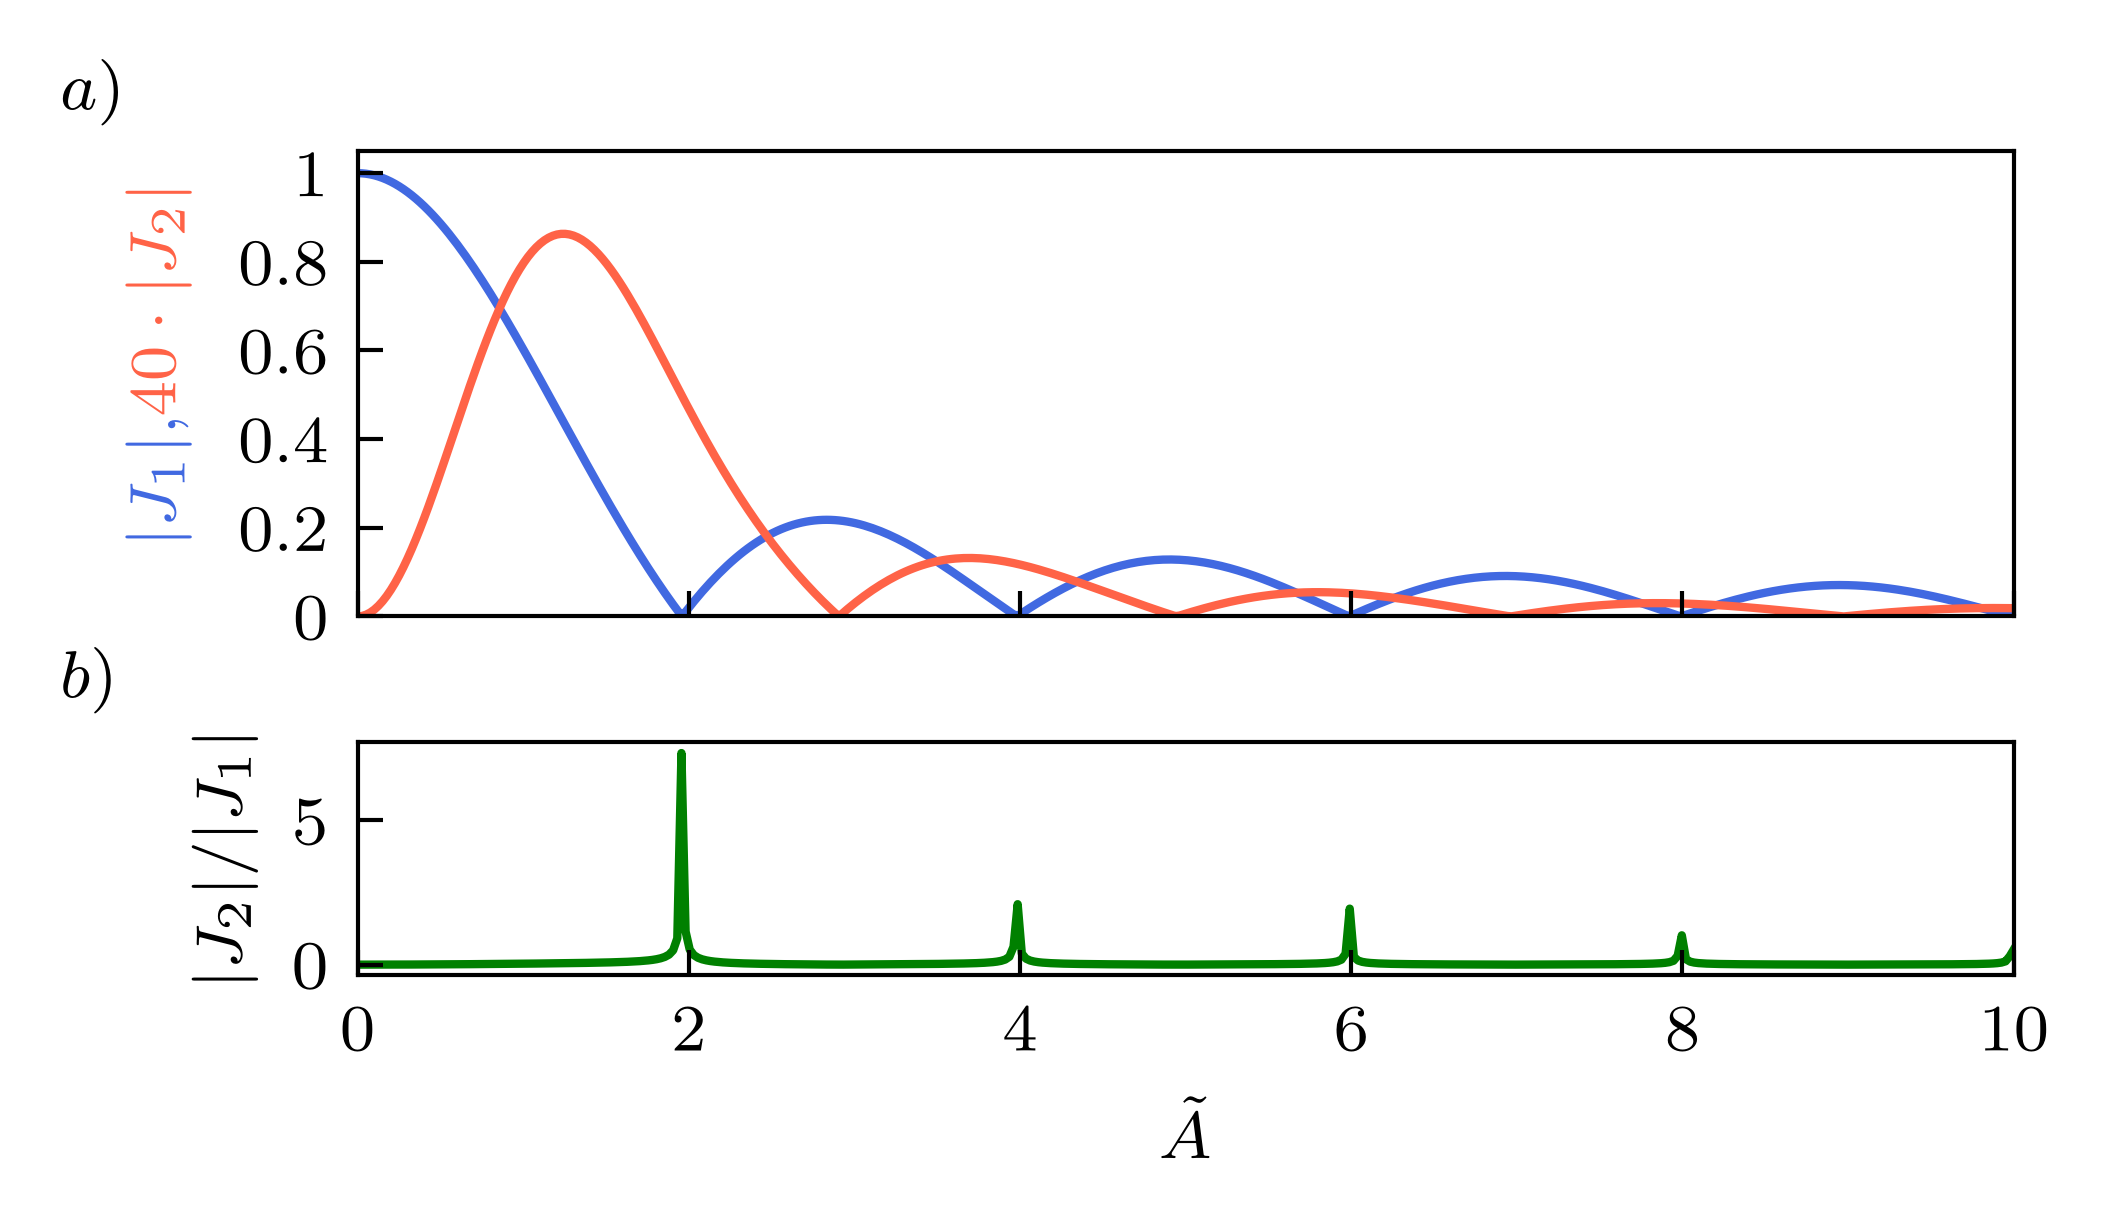

In [18]:
d, p = load_data(DATA / 'FigA06_hoppings.npz')
At, J1_abs, J2_abs = d['Atilde_vals'], np.abs(d['J1']), np.abs(d['J2'])

fig, ax = plt.subplots(2, 1, figsize=(3.5, 2), height_ratios=[1, 0.5])

ax[0].plot(At, J1_abs, linewidth=1, color='royalblue')
ax[0].plot(At, 40 * J2_abs, linewidth=1, color='tomato')
ax[0].set_ylim(0, 1.05)
ax[0].set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1])
ax[0].set_yticklabels([0, 0.2, 0.4, 0.6, 0.8, 1], fontsize=8)
ax[0].text(-0.12, 0.15, r'$|J_1|$,', color='royalblue', transform=ax[0].transAxes, rotation=90, ha='center', va='bottom', fontsize=8)
ax[0].text(-0.12, 0.43, r'$40 \cdot|J_2|$', color='tomato', transform=ax[0].transAxes, rotation=90, ha='center', va='bottom', fontsize=8)

ax[1].plot(At, J2_abs / J1_abs, linewidth=1, color='green')
ax[1].set_ylabel(r'$\vert J_2 \vert / \vert J_1 \vert$', fontsize=8)
ax[1].set_xlabel(r'$\tilde{A}$', fontsize=8)

for axis in ax:
    axis.set_xlim(0, 10)
    axis.set_xticks([0, 2, 4, 6, 8, 10])
ax[0].set_xticklabels([])
ax[1].set_xticklabels([0, 2, 4, 6, 8, 10], fontsize=8)

plt.tight_layout()
plt.text(0.01, 0.96, r'$a)$', fontsize=8, transform=fig.transFigure)
plt.text(0.01, 0.47, r'$b)$', fontsize=8, transform=fig.transFigure)

plt.savefig(FIGURES / 'hopping_ren.pdf', transparent=True)

## Fig. A7 — Diamond chain vs SSH chain
All eigenvalues of the odd diamond chain are plotted (the original loop used the size of the even chain and skipped the 3 highest levels).

FigA07_diamond_vs_SSH.npz
    parameters: {'J1': 1.0, 'Ncells_even': 20, 'Ncells_odd': 21, 't1_ssh': 2.0, 'Ncells_ssh': 20}
    J2_diamond: shape (100,)
    E_diamond_even: shape (100, 61)
    E_diamond_odd: shape (100, 64)
    band_max: shape (100,)
    band_min: shape (100,)
    t2_ssh: shape (201,)
    E_ssh_even: shape (201, 40)
    E_ssh_odd: shape (201, 41)


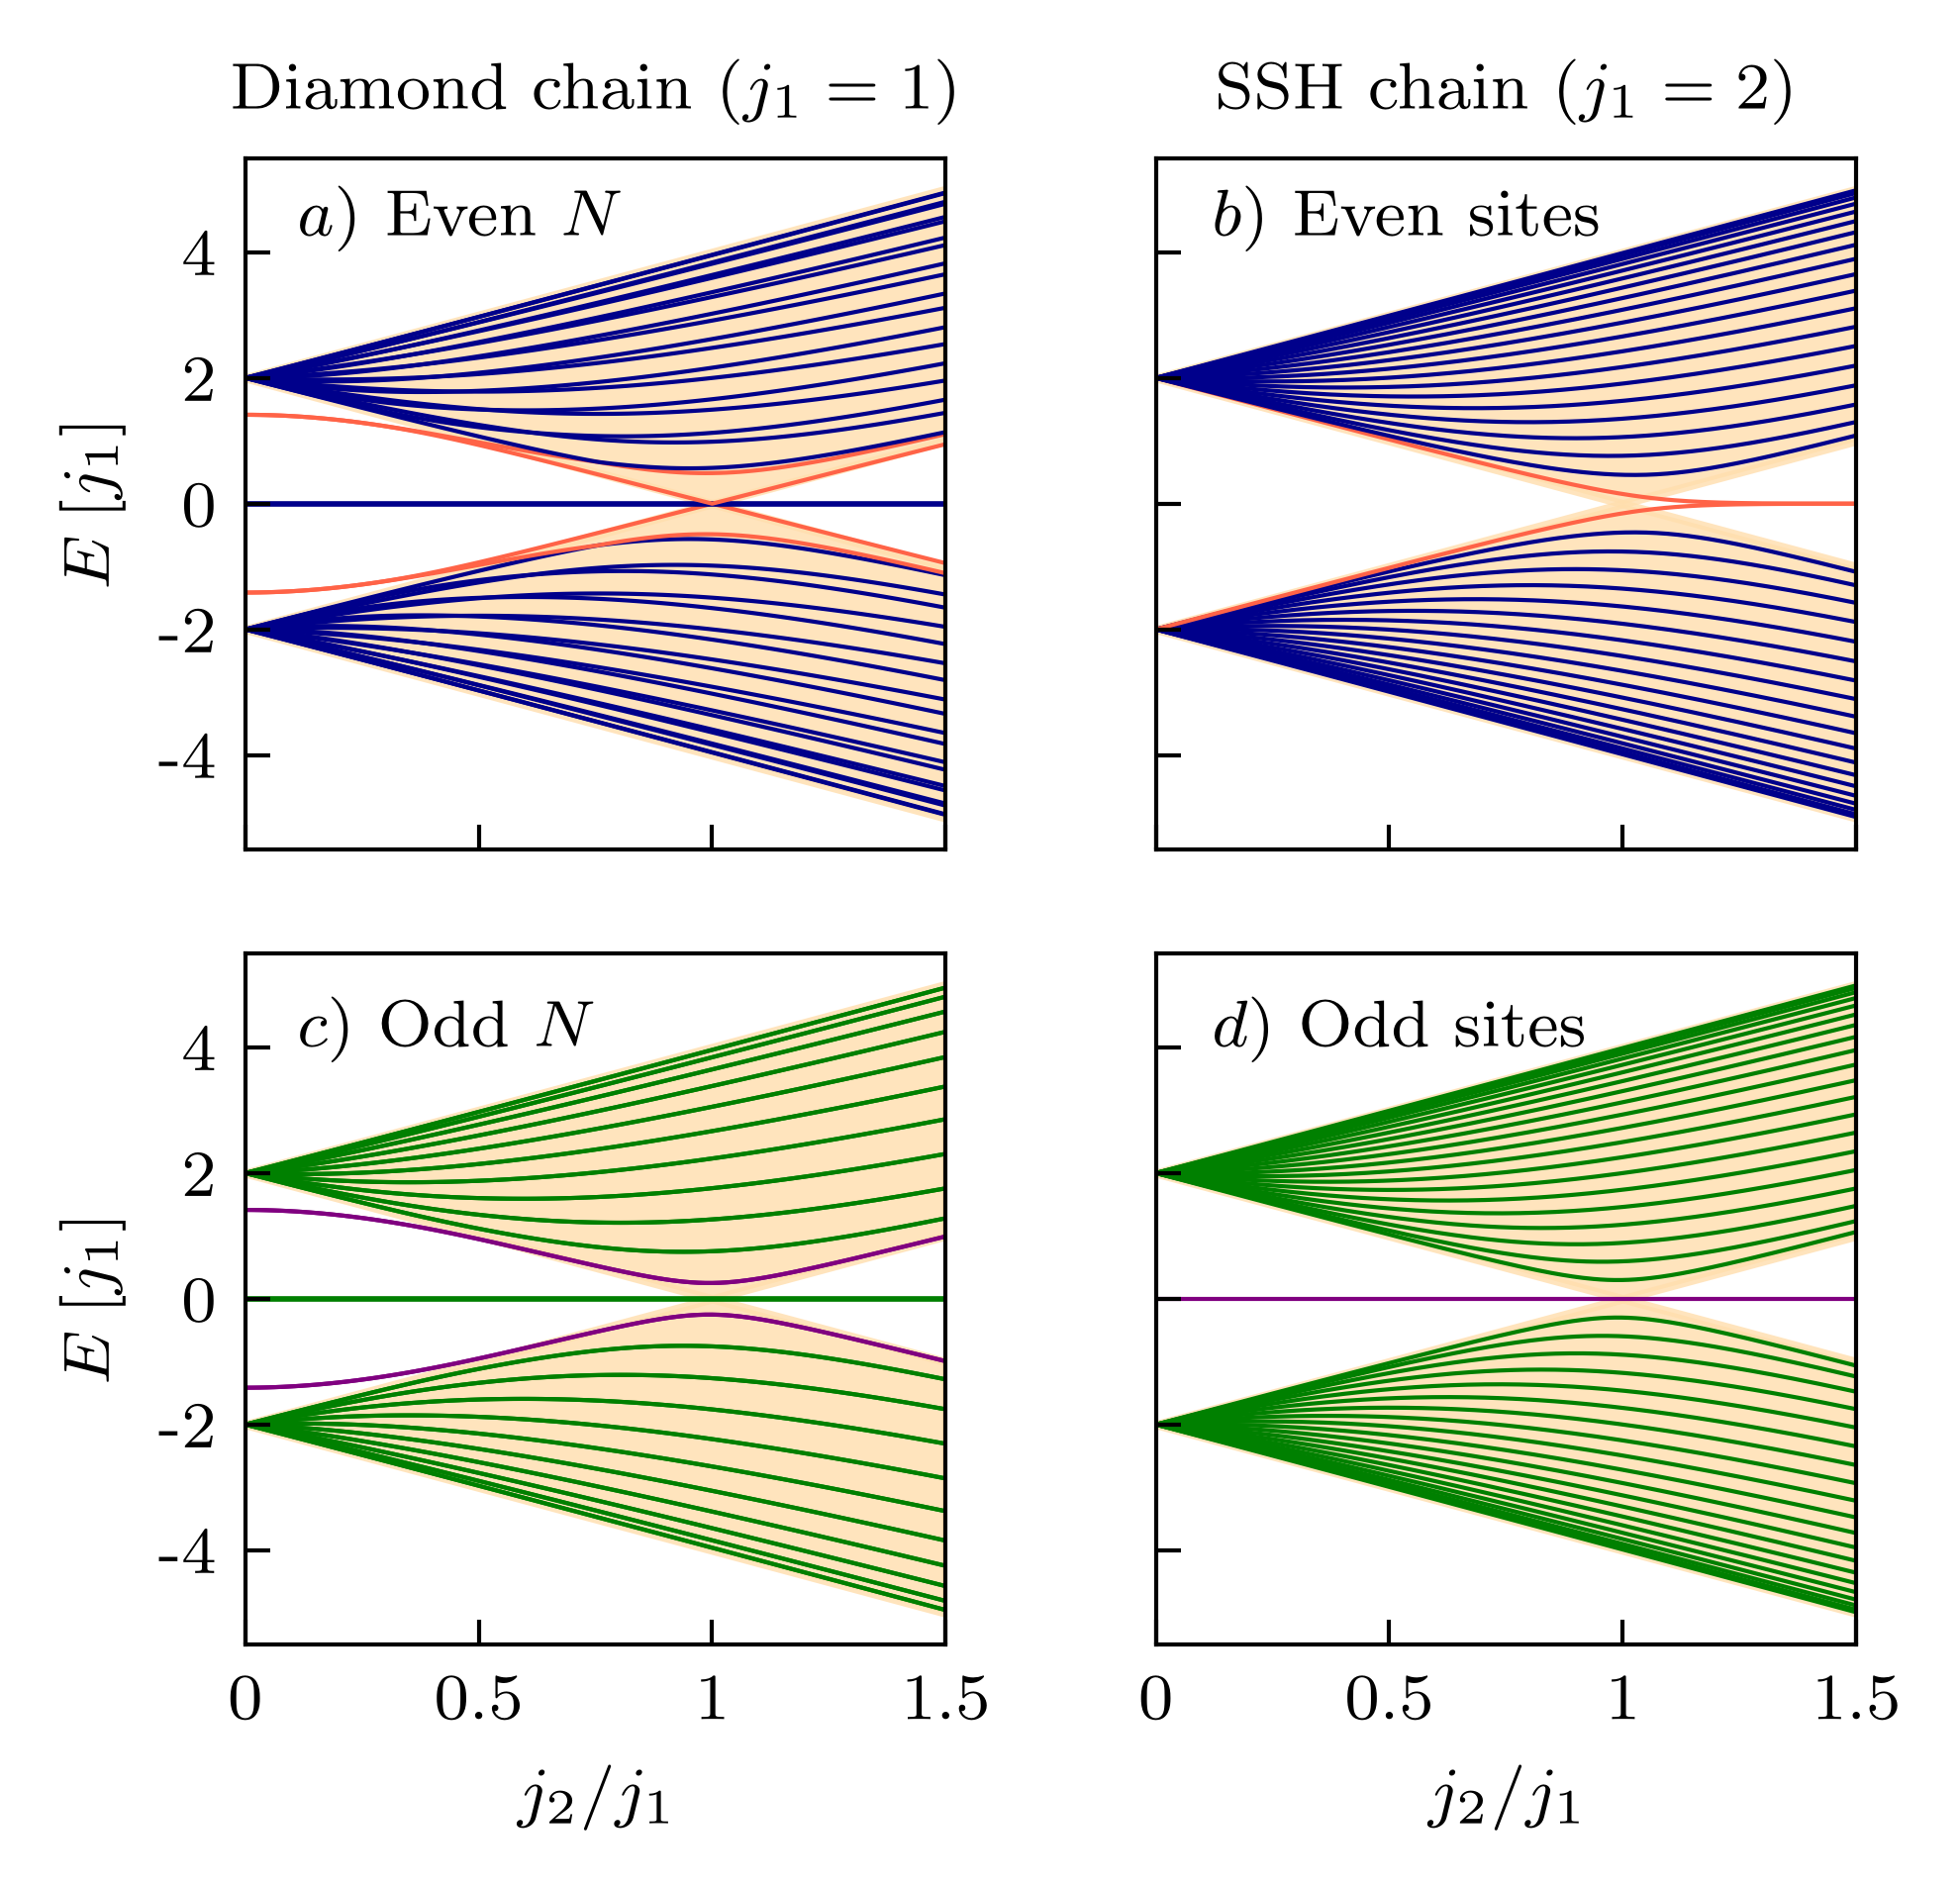

In [19]:
d, p = load_data(DATA / 'FigA07_diamond_vs_SSH.npz')
J2d, t2 = d['J2_diamond'], d['t2_ssh']
x_ssh = t2 / p['t1_ssh']                      # J2 / J1 for the SSH chain

def shade(axis):
    axis.fill_between(J2d, d['band_min'], d['band_max'], color='navajowhite', alpha=0.8)
    axis.fill_between(J2d, -d['band_max'], -d['band_min'], color='navajowhite', alpha=0.8)

def plot_levels(axis, x, E, edge, color, edge_color):
    for i in range(E.shape[1]):
        axis.plot(x, E[:, i], linewidth=0.5, color=edge_color if i in edge else color)

N_even, N_odd = p['Ncells_even'], p['Ncells_odd']
N_ssh = p['Ncells_ssh']

fig, ax = plt.subplots(2, 2, figsize=(3.5, 3.25))
fig.subplots_adjust(hspace=0.15, wspace=0.3)

shade(ax[0, 0])
plot_levels(ax[0, 0], J2d, d['E_diamond_even'], [N_even - 1, N_even, 2 * N_even, 2 * N_even + 1], 'darkblue', 'tomato')
plot_levels(ax[0, 1], x_ssh, d['E_ssh_even'], [N_ssh - 1, N_ssh], 'darkblue', 'tomato')
shade(ax[0, 1])

plot_levels(ax[1, 0], J2d, d['E_diamond_odd'], [N_odd - 1, N_odd, 2 * N_odd, 2 * N_odd + 1], 'green', 'purple')
shade(ax[1, 0])
plot_levels(ax[1, 1], x_ssh, d['E_ssh_odd'], [N_ssh], 'green', 'purple')
shade(ax[1, 1])

for axis in ax.ravel():
    axis.set_xlim([0, 1.5])
    axis.set_xticks([0, 0.5, 1, 1.5])
    axis.set_yticks([-4, -2, 0, 2, 4])
for axis in ax[0]:
    axis.set_xticklabels([])
for axis in ax[1]:
    axis.set_xticklabels([0, 0.5, 1, 1.5], fontsize=8)
    axis.set_xlabel(r'$j_2 / j_1$', fontsize=8)
for axis in ax[:, 0]:
    axis.set_yticklabels([-4, -2, 0, 2, 4], fontsize=8)
    axis.set_ylabel(r'$E \hspace{2pt} [j_1]$', fontsize=8)
for axis in ax[:, 1]:
    axis.set_yticklabels([])

ax[0, 0].set_title(r'Diamond chain ($j_1 = 1$)', fontsize=8)
ax[0, 1].set_title(r'SSH chain ($j_1 = 2$)', fontsize=8)
plt.text(0.15, 0.84, r'$a)$ Even $N$ ', fontsize=8, transform=fig.transFigure)
plt.text(0.59, 0.84, r'$b)$ Even sites', fontsize=8, transform=fig.transFigure)
plt.text(0.15, 0.42, r'$c)$ Odd $N$ ', fontsize=8, transform=fig.transFigure)
plt.text(0.59, 0.42, r'$d)$ Odd sites', fontsize=8, transform=fig.transFigure)

plt.savefig(FIGURES / 'diamond_compared_to_ssh.pdf', transparent=True)

## Fig. A8 — Zak phases: exact vs effective
Same data as the previous figure: exact stroboscopic Floquet modes of $\hat U_{\rm t}(T)$ (markers, every 4th point) and eigenstates of the
second-order $\hat H_{\rm eff}(k)$ (lines; missing at the pole $\tilde A = 1$). Each legend entry shows both handles. One column wide.

FigA02_A08_zak_phase.npz
    parameters: {'J': 1.0, 'phi': 3.141592653589793, 'zeta': -1, 'w': 8, 'nk': 400, 'A_t0': 9.6}
    Avals: shape (101,)
    Z_exact: shape (101, 3)
    Z_effective: shape (101, 3)
    gap_min: shape (101,)
    t0_over_T: shape (41,)
    Z_t0: shape (41, 3)


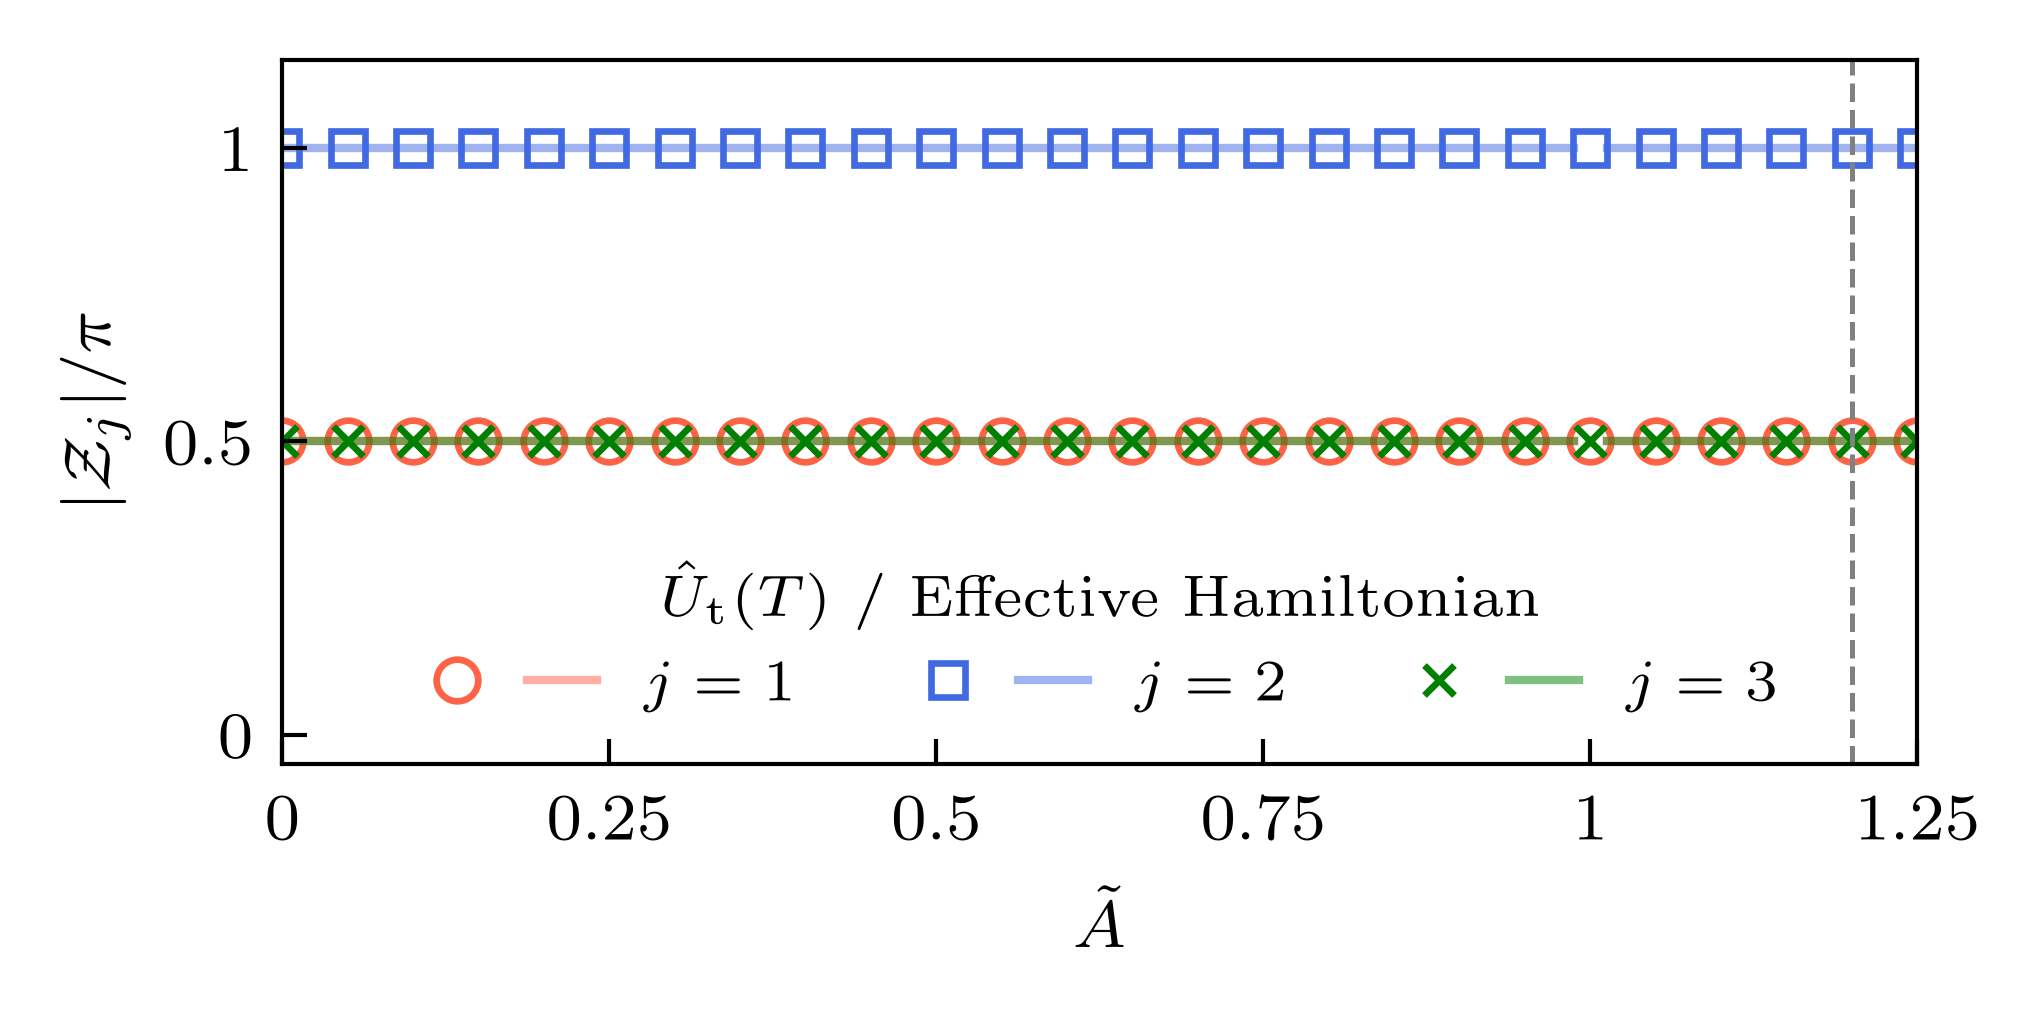

In [20]:
d, p = load_data(DATA / 'FigA02_A08_zak_phase.npz')
At = d['Avals'] / p['w']
Z_exact, Z_effective = np.abs(d['Z_exact']) / np.pi, np.abs(d['Z_effective']) / np.pi

colors = ['tomato', 'royalblue', 'green']
markers = ['o', 's', 'x']                     # j = 1 and j = 3 coincide: different markers keep both visible
sizes = [5, 4, 3.5]

from matplotlib.legend_handler import HandlerTuple

fig, ax = plt.subplots(figsize=(3.5, 1.8))

handles = []
for j in range(3):
    line, = ax.plot(At, Z_effective[:, j], '-', lw=1, color=colors[j], alpha=0.5)
    mark, = ax.plot(At[::4], Z_exact[::4, j], markers[j], ms=sizes[j], mfc='none', mew=0.8, color=colors[j])
    handles.append((mark, line))

ax.axvline(p['A_t0'] / p['w'], ls='--', lw=0.6, color='gray')          # Atilde = 1.2 of the manuscript
ax.set_xlim(0, At.max())
ax.set_ylim(-0.05, 1.15)
ax.set_yticks([0, 0.5, 1])
ax.set_yticklabels([0, 0.5, 1], fontsize=8)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1, 1.25])
ax.set_xticklabels([0, 0.25, 0.5, 0.75, 1, 1.25], fontsize=8)
ax.set_xlabel(r'$\tilde{A}$', fontsize=8)
ax.set_ylabel(r'$|\mathcal{Z}_j|/\pi$', fontsize=8)
ax.legend(handles, [rf'$j = {j + 1}$' for j in range(3)], handler_map={tuple: HandlerTuple(ndivide=None, pad=0.6)},
          handlelength=3, fontsize=7, title=r'$\hat{U}_{\rm t}(T)$ / Effective Hamiltonian', title_fontsize=7,
          ncol=3, loc='lower center', frameon=False)

plt.tight_layout()
plt.savefig(FIGURES / 'zak_phase_effective.pdf', transparent=True)

In [21]:
sorted(f.name for f in FIGURES.glob('*.pdf'))

['bulk_bands.pdf',
 'colormap_AV.pdf',
 'convergence_A.pdf',
 'convergence_Gamma.pdf',
 'diamond_compared_to_ssh.pdf',
 'dynamics_csite_vs_w.pdf',
 'dynamics_starting_csite.pdf',
 'dynamics_starting_ulattice.pdf',
 'edge_states_static.pdf',
 'edgestates_driven.pdf',
 'entanglements.pdf',
 'fouriertransform_colormap.pdf',
 'hopping_ren.pdf',
 'open_vs_closed.pdf',
 'quasienergies.pdf',
 'short_dynamics.pdf',
 'two_particle_spectrum_vs_V.pdf',
 'zak_phase.pdf',
 'zak_phase_effective.pdf']

## Fig. A9 — Fourier transform of $S^{(A)}$ vs $V$
Uses `Data/FigA09_FT_entanglement.npz` (see `FigA09_fourier_transform_entanglement`).

FigA09_FT_entanglement.npz
    parameters: {'Ncells': 2, 'Nup': 2, 'Ndown': 0, 'J': 1.0, 'phi': 3.141592653589793, 'w': 8, 'A': 9.6, 'zeta': -1, 'A_spec': [['C', 1], ['U', 1], ['D', 1]], 'psi0_binary': '1000001|0000000', 'ncycles': 40000}
    Vvals: shape (300,)
    freqs: shape (20001,)
    FT_S_A: shape (300, 20001)
    FT_E_P: shape (300, 20001)


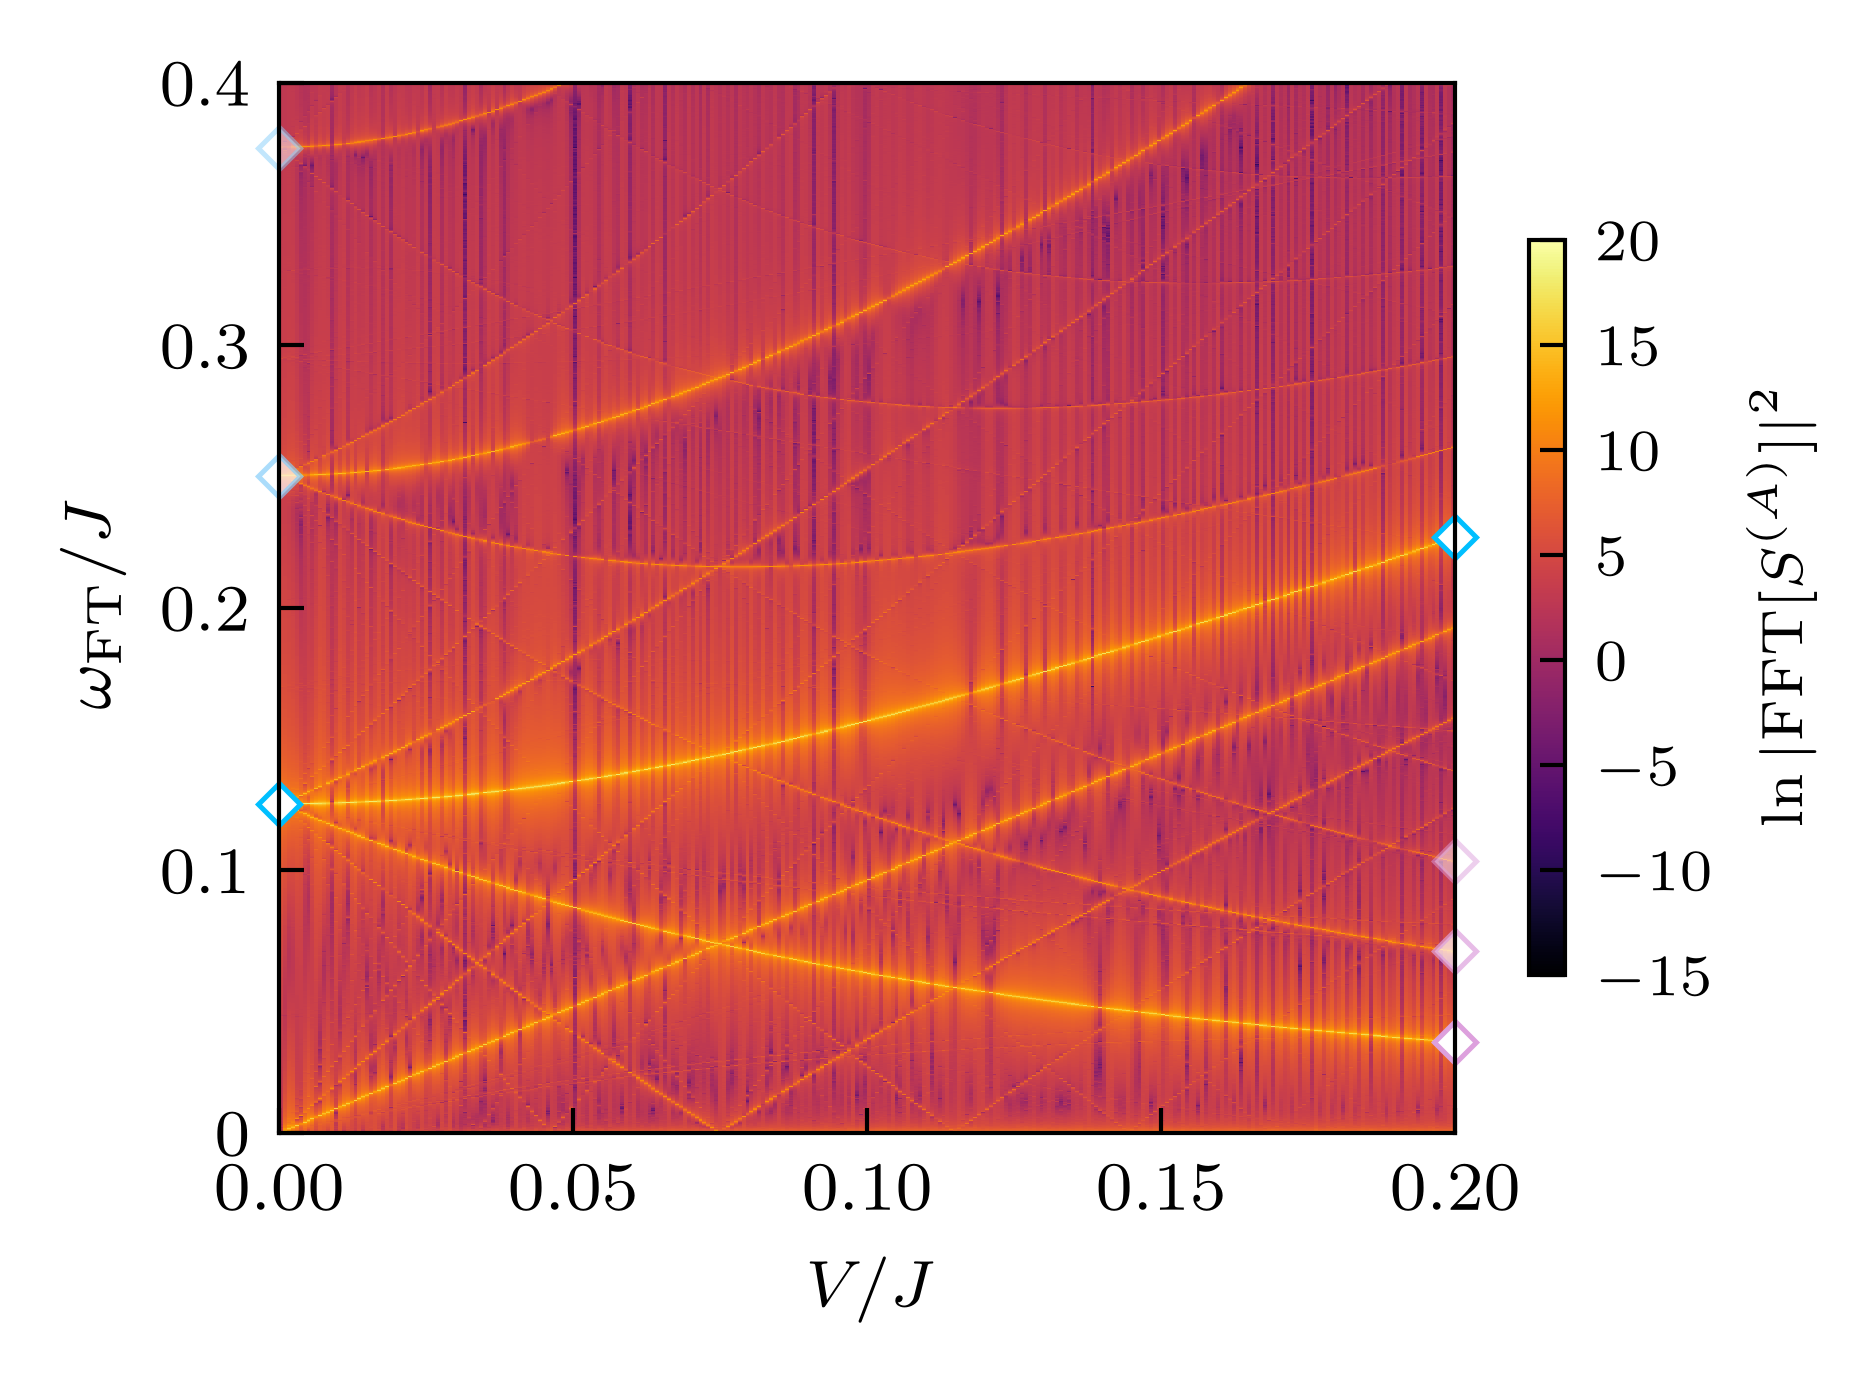

In [22]:
d, p = load_data(DATA / 'FigA09_FT_entanglement.npz')
Vvals, freqs, FT = d['Vvals'], d['freqs'], d['FT_S_A']

fig, ax = plt.subplots(figsize=(3.5, 2.5))
with np.errstate(divide='ignore'):
    pcm = ax.imshow(np.log(FT).T, extent=[Vvals.min(), Vvals.max(), freqs.min(), freqs.max()],
                    aspect='auto', origin='lower', vmin=-15, vmax=20, interpolation='none', cmap='inferno')

def diamond(x, y, color, alpha=1):
    ax.plot(x, y, marker='D', markersize=3.5, markerfacecolor='white', markeredgecolor=color,
            markeredgewidth=0.6, alpha=alpha, clip_on=False)

# Frequencies marked in Fig. 7 and their harmonics (decreasing opacity)
diamond(0, OMEGA_FT_V0, 'deepskyblue')
diamond(0, 2 * OMEGA_FT_V0, 'lightskyblue', alpha=0.7)
diamond(0, 3 * OMEGA_FT_V0, 'lightskyblue', alpha=0.5)
diamond(0.2, OMEGA_FT_V02_SLOW, 'plum')
diamond(0.2, 2 * OMEGA_FT_V02_SLOW, 'plum', alpha=0.7)
diamond(0.2, 3 * OMEGA_FT_V02_SLOW, 'plum', alpha=0.5)
diamond(0.2, OMEGA_FT_V02_FAST, 'deepskyblue')

ax.set_ylim(0, 0.4)
ax.set_xlim(0, 0.2)
ax.set_xlabel(r'$V/J$', fontsize=8)
ax.set_ylabel(r'$\omega_{\mathrm{FT}}/J$', fontsize=8)
ax.set_yticks([0, 0.1, 0.2, 0.3, 0.4])
ax.set_yticklabels([0, 0.1, 0.2, 0.3, 0.4], fontsize=8)
cbar = plt.colorbar(pcm, ax=ax, shrink=0.7)
cbar.set_ticks([-15, -10, -5, 0, 5, 10, 15, 20])
cbar.ax.tick_params(labelsize=7)
cbar.set_label(r'$\ln \vert \mathrm{FFT}[S^{(A)}] \vert^2$', fontsize=7)

plt.tight_layout()
fig.subplots_adjust(top=0.9, bottom=0.2, left=0.2, right=0.9)
plt.savefig(FIGURES / 'fouriertransform_colormap.pdf', transparent=True)

## Fig. A10 — Maximum entanglement vs $A$ and $V$
Uses `Data/FigA10_max_entanglement.npz`, computed by `FigA10_max_entanglement_vs_A_and_V`, which stores $\max S^{(A)}$, $\max E_P(1,1)$ and $\max S^{(A)}_{1,1}$.
Panel b) shows $\max E_P(1,1)$. The published version showed $\max S^{(A)}_{1,1}$ labelled as $E_P(1,1)$; if a data file
without `max_E_P` is used, panel b) falls back to $\max S^{(A)}_{1,1}$ and is labelled accordingly.

FigA10_max_entanglement.npz
    parameters: {'Ncells': 2, 'Nup': 2, 'Ndown': 0, 'J': 1.0, 'phi': 3.141592653589793, 'w': 8, 'zeta': -1, 'A_spec': [['C', 1], ['U', 1], ['D', 1]], 'psi0_binary': '1000001|0000000', 'ncycles': 200}
    Vvals: shape (200,)
    Avals: shape (200,)
    max_S_A: shape (200, 200)
    max_E_P: shape (200, 200)
    max_S_11: shape (200, 200)
max S_A = 1.3870708795983373  2 log 2 = 1.3862943611198906


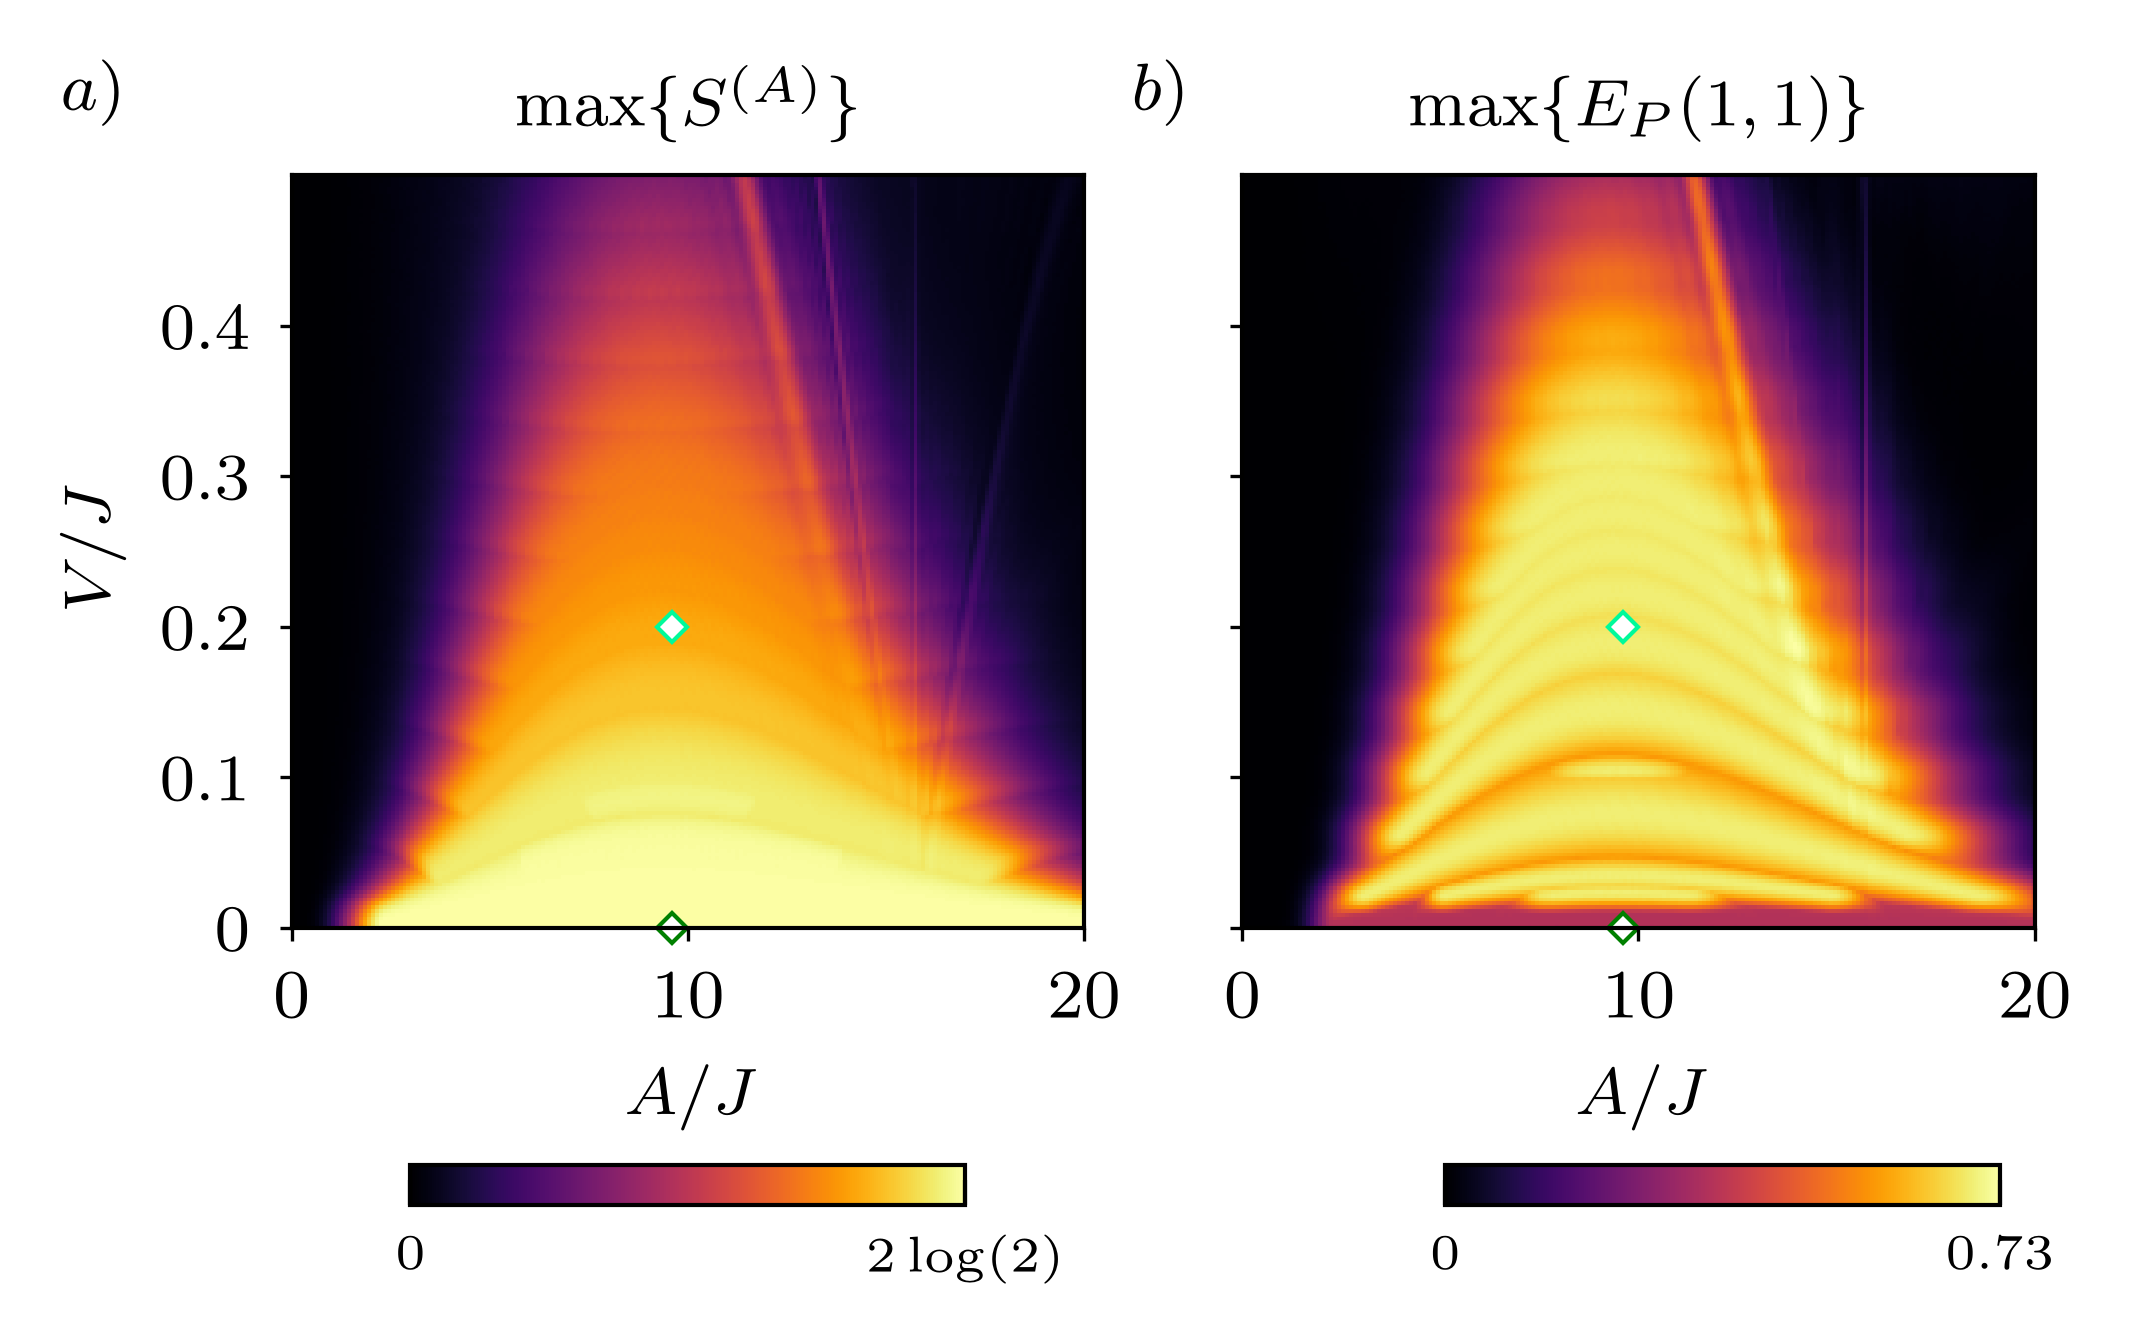

In [23]:
d, p = load_data(DATA / 'FigA10_max_entanglement.npz')
Avals, Vvals = d['Avals'], d['Vvals']

if 'max_E_P' in d:
    panel_b, title_b = d['max_E_P'], r'$\mathrm{max}\{E_P(1,1)\}$'
else:
    print('WARNING: max_E_P not in the data file; plotting max S_11 (as in the published figure). '
          'Run FigA10_max_entanglement_vs_A_and_V.ipynb to compute max E_P(1,1).')
    panel_b, title_b = d['max_S_11'], r'$\mathrm{max}\{S^{(A)}_{1,1}\}$'

A_fig7 = 9.6                                  # (A, V) of Fig. 7
fig, ax = plt.subplots(1, 2, figsize=(3.5, 2.2))
images = []
for axis, data, title in zip(ax, [d['max_S_A'], panel_b], [r'$\mathrm{max}\{S^{(A)}\}$', title_b]):
    images.append(axis.imshow(data, extent=[Avals.min(), Avals.max(), Vvals.min(), Vvals.max()], aspect='auto',
                              origin='lower', vmin=0, vmax=np.amax(data), interpolation='none', cmap='inferno'))
    for V, color in [(0.2, 'mediumspringgreen'), (0., 'green')]:
        axis.plot(A_fig7, V, marker='D', markersize=2.5, markerfacecolor='white', markeredgecolor=color,
                  markeredgewidth=0.5, clip_on=False)
    axis.set_yticks([0, 0.1, 0.2, 0.3, 0.4])
    axis.set_xlabel(r'$A/J$', fontsize=8)
    axis.set_title(title, fontsize=8)
    axis.tick_params(which='major', direction='out', length=1.5, width=0.4)
ax[0].set_yticklabels([0, 0.1, 0.2, 0.3, 0.4], fontsize=8)
ax[0].set_ylabel(r'$V/J$', fontsize=8)
ax[1].set_yticklabels([])

fig.subplots_adjust(top=0.87, bottom=0.3, left=0.12, right=0.95)

# Horizontal colorbars below each panel
shrink = 0.7
for axis, im, offset in zip(ax, images, [0, 0.04]):
    pos = axis.get_position()
    cax = fig.add_axes([pos.x0 + offset + (1 - shrink) / 2 * pos.width, pos.y0 - 0.21, pos.width * shrink, 0.03])
    cbar = fig.colorbar(im, cax=cax, orientation='horizontal')
    cbar.ax.tick_params(labelsize=6)
    vmax = im.get_clim()[1]
    cbar.set_ticks([0, vmax])
    if axis is ax[0]:
        cbar.set_ticklabels([0, r'$2\log(2)$'])
    else:
        cbar.set_ticklabels([0, f'{vmax:.2f}'])

plt.text(0.01, 0.92, r'$a)$', fontsize=8, transform=fig.transFigure)
plt.text(0.52, 0.92, r'$b)$', fontsize=8, transform=fig.transFigure)

plt.savefig(FIGURES / 'colormap_AV.pdf', transparent=True)
print('max S_A =', np.amax(d['max_S_A']), ' 2 log 2 =', 2 * np.log(2))

## Fig. A11 — Two-particle Floquet spectrum vs $V$
Two-particle quasienergies vs $V$ ($N = 2$, $\omega = 8$, $\tilde A = 1.2$), each level followed in $V$ with `sort_bands` and colored by
**a)** its end-site weight, **b)** the spectral weight of $\hat C_1^\dagger \hat C_3^\dagger|0\rangle$, **c)** its flat-band character.
Data from `FigA11_two_particle_spectrum_vs_V` (`Data/FigA11_two_particle_spectrum_vs_V.npz`).
One column wide, three rows.

FigA11_two_particle_spectrum_vs_V.npz
    parameters: {'Ncells': 2, 'Nup': 2, 'Ndown': 0, 'J': 1.0, 'phi': 3.141592653589793, 'w': 8, 'A': 9.6, 'zeta': -1, 'psi0_binary': '1000001|0000000', 'V_highlight': 0.2}
    Vvals: shape (201,)
    quasienergies: shape (201, 21)
    end_weight: shape (201, 21)
    initial_weight: shape (201, 21)
    flat_weight: shape (201, 21)


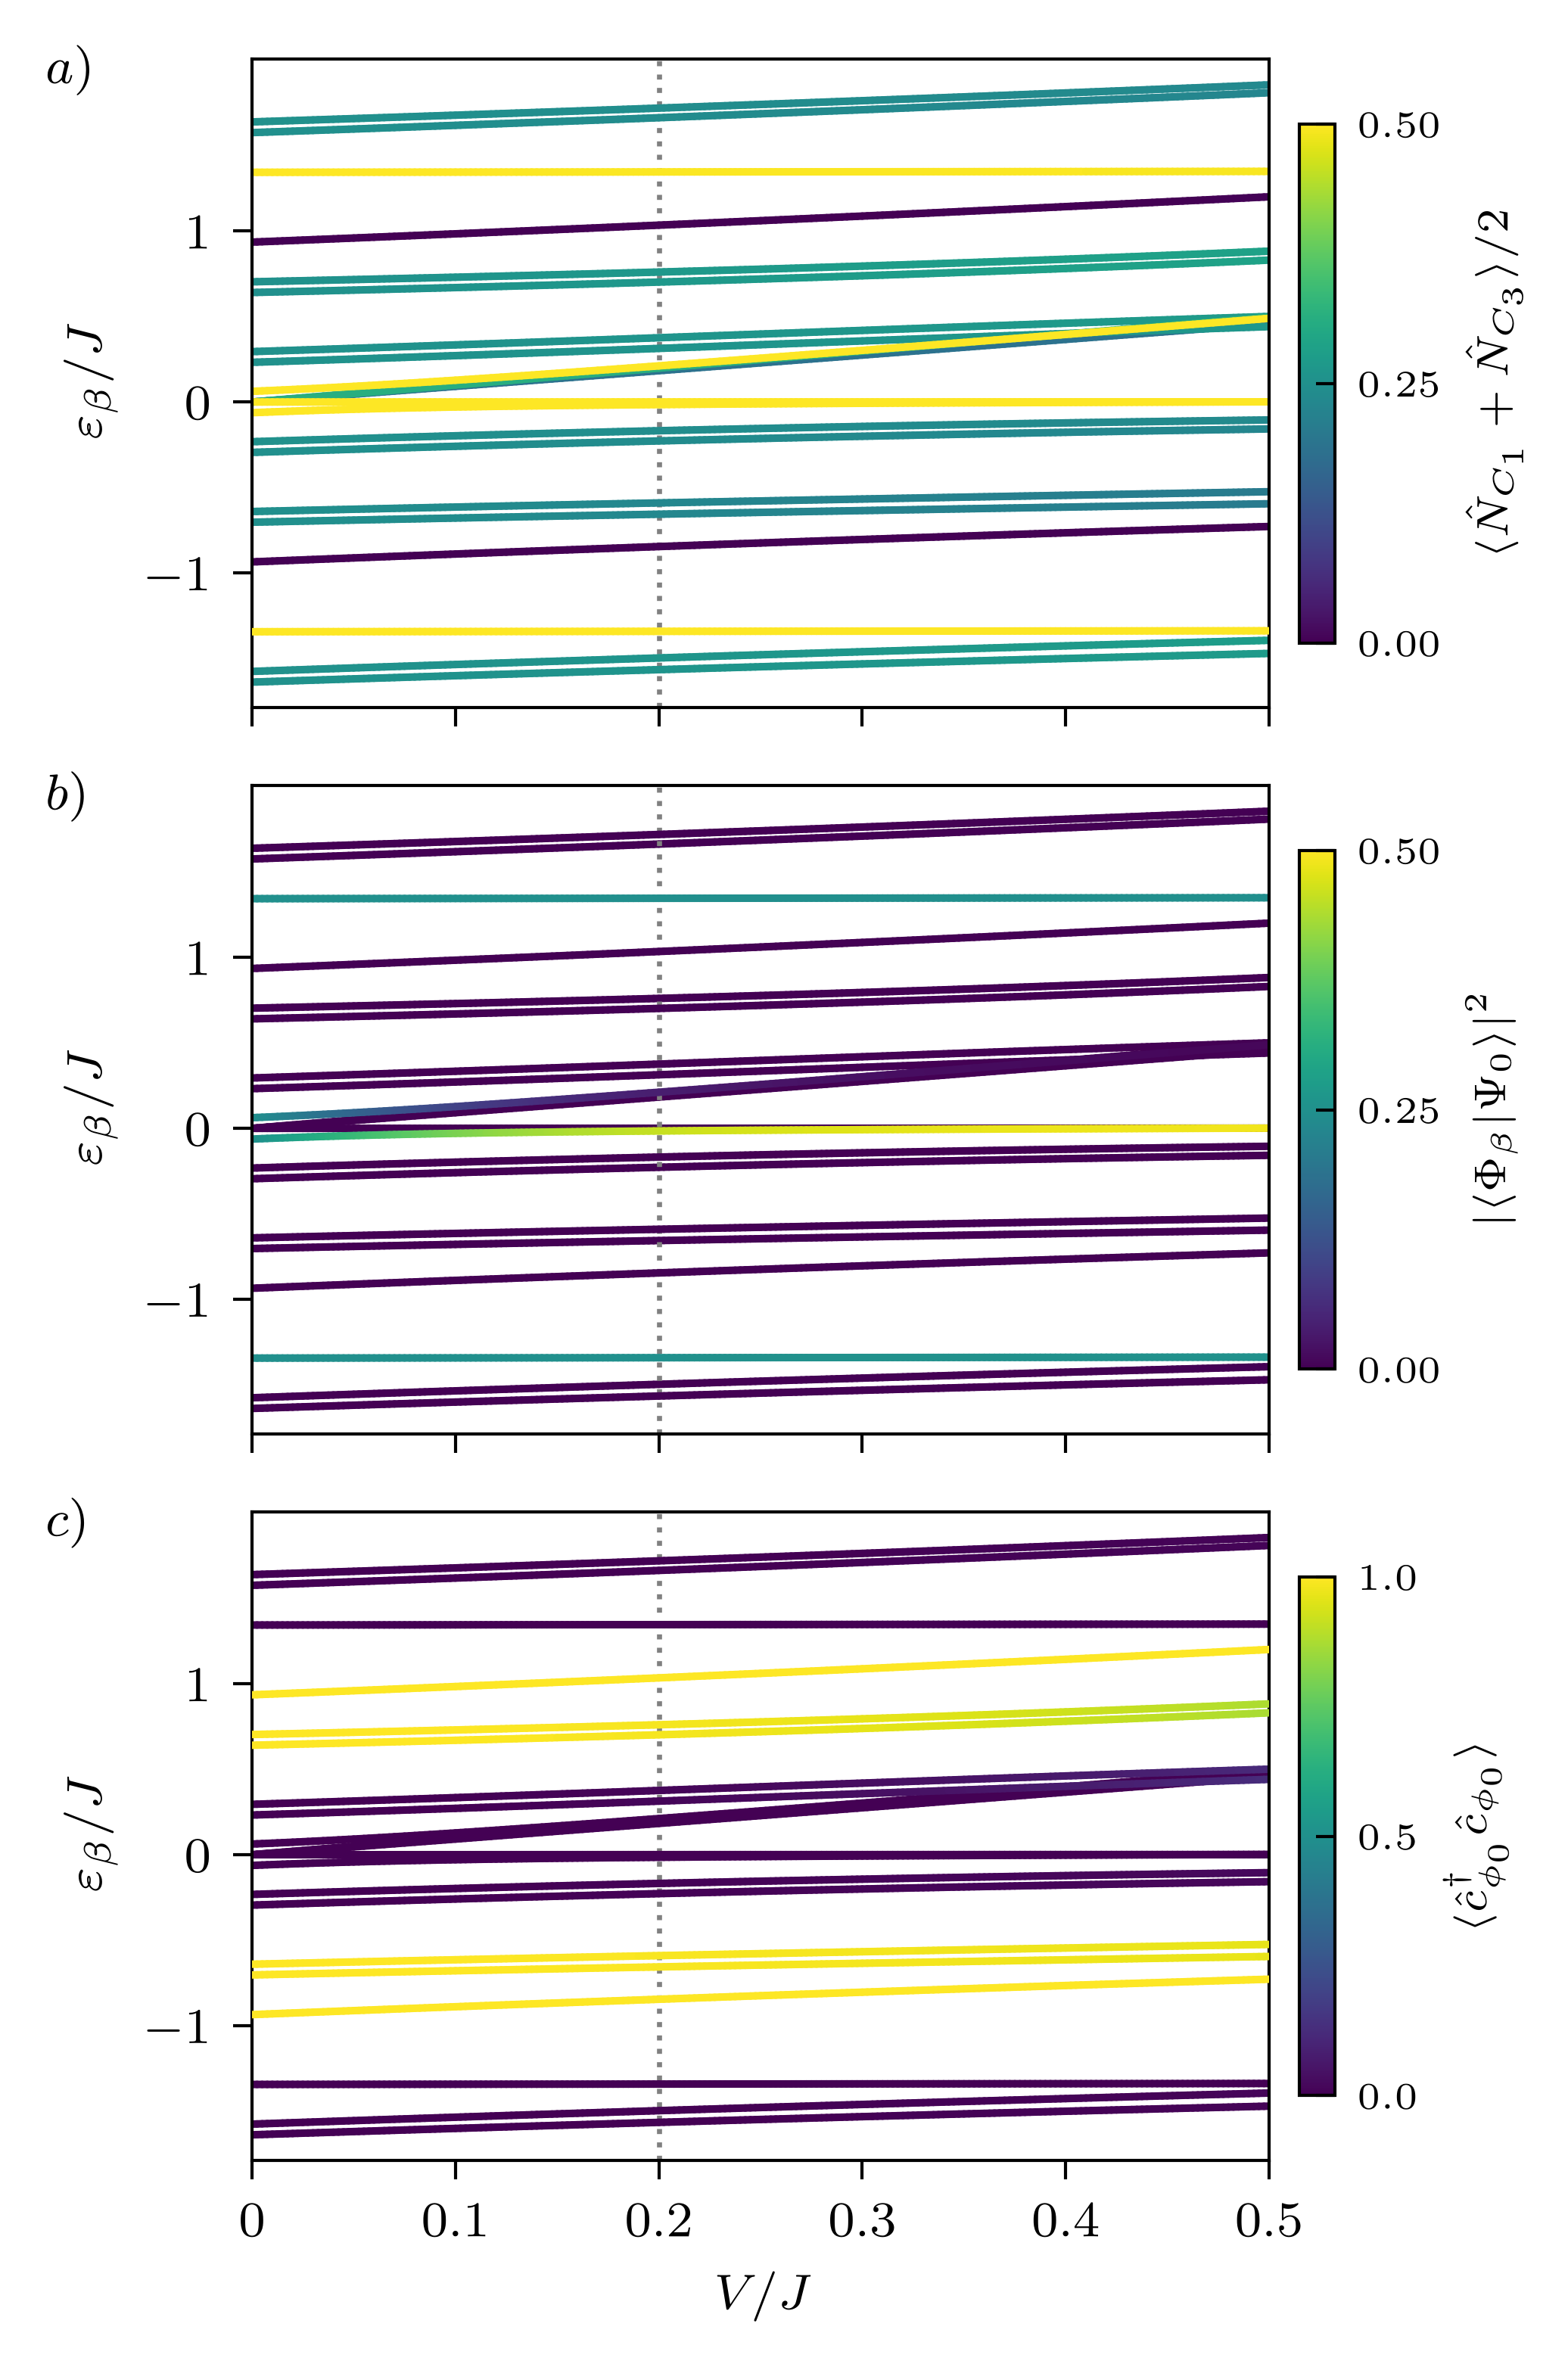

In [24]:
from line_gradient_colors import color_line_lc

d, p = load_data(DATA / 'FigA11_two_particle_spectrum_vs_V.npz')
Vvals, quasienergies = d['Vvals'], d['quasienergies']
markers = [(d['end_weight'], 0.5, r'$\langle \hat N_{C_1} + \hat N_{C_3}\rangle / 2$'),
           (d['initial_weight'], 0.5, r'$|\langle \Phi_\beta | \Psi_0 \rangle|^2$'),
           (d['flat_weight'], 1.0, r'$\langle \hat c_{\phi_0}^\dagger \hat c_{\phi_0} \rangle$')]

fig, axs = plt.subplots(3, 1, figsize=(3.5, 5.2), sharex=True)

for ax, (marker, vmax, cbar_label), label in zip(axs, markers, 'abc'):
    for j in range(quasienergies.shape[1]):
        lc = color_line_lc(Vvals, quasienergies[:, j], marker[:, j], ax=ax, vmin=0, vmax=vmax,
                           cmap='viridis', lw=1.2, zorder=2 + marker[:, j].max())   # high weight on top
    ax.axvline(p['V_highlight'], color='gray', ls=':', lw=0.8)
    ax.set_xlim(Vvals.min(), Vvals.max())
    ax.set_ylim(quasienergies.min() - 0.15, quasienergies.max() + 0.15)
    ax.set_yticks([-1, 0, 1])
    ax.set_yticklabels(['$-1$', '$0$', '$1$'], fontsize=8)
    ax.set_ylabel(r'$\varepsilon_\beta/J$', fontsize=8)
    ax.tick_params(axis='both', which='major', length=3, direction='out')

    cax = ax.inset_axes([1.03, 0.1, 0.035, 0.8])
    cbar = fig.colorbar(lc, cax=cax)
    cbar.set_ticks([0, vmax / 2, vmax])
    cbar.ax.tick_params(labelsize=6)
    cbar.set_label(cbar_label, fontsize=7)

axs[2].set_xticks([0, 0.1, 0.2, 0.3, 0.4, 0.5])
axs[2].set_xticklabels([0, 0.1, 0.2, 0.3, 0.4, 0.5], fontsize=8)
axs[2].set_xlabel(r'$V/J$', fontsize=8)

fig.subplots_adjust(left=0.14, right=0.78, top=0.97, bottom=0.08, hspace=0.12)
for ax, label in zip(axs, 'abc'):
    fig.text(0.01, ax.get_position().y1 - 0.01, rf'${label})$', fontsize=8)

plt.savefig(FIGURES / 'two_particle_spectrum_vs_V.pdf', transparent=True)